# Dự đoán khách hàng vỡ nợ thẻ tín dụng

### Đồ án tốt nghiệp: ứng dụng học máy (Logistic Regression, Decision Tree, Random Forest) cho bài toán phân loại vỡ nợ thẻ tín dụng.


Bộ dữ liệu chứa thông tin về tình trạng thanh toán, yếu tố nhân khẩu học, dữ liệu tín dụng, lịch sử thanh toán và sao kê của khách hàng sử dụng thẻ tín dụng tại Đài Loan từ tháng 4/2005 đến tháng 9/2005 (UCI Machine Learning Repository, id=350).

# Mục lục

* [Mục tiêu](#obj)
* [Nhập thư viện và tải dữ liệu](#imp)
* [Tiền xử lý dữ liệu](#prep)
* [Feature Engineering](#fe)
    * [Tạo thêm đặc trưng nghiệp vụ mới](#fe2)
* [Phân tích khám phá dữ liệu (EDA)](#eda)
    * [Ánh xạ biến mục tiêu](#map)
    * [Thống kê mô tả](#stat)
    * [Tỷ lệ vỡ nợ theo nhóm](#rate)
    * [Chuẩn hoá và trực quan hoá đặc trưng](#std)
    * [Tương quan](#corr)
* [Học máy: Các mô hình phân loại](#ml)
    * [Xử lý mất cân bằng dữ liệu](#imb)
    * [Chia tập train/test](#sp)
    * [Đa cộng tuyến (VIF) cho Logistic Regression](#vif)
    * [Huấn luyện mô hình](#train)
    * [Đánh giá mô hình trên tập test](#eval)
    * [So sánh ROC và Precision-Recall](#roc)
    * [Đánh giá chéo (Cross-Validation)](#cv)
    * [Kiểm định thống kê](#ttest)
* [Feature Importance](#fi)
* [Kết luận](#conclusion)


<a id='obj'></a>
## Mục tiêu:<br>
-       Xác định các yếu tố chính ảnh hưởng đến khả năng vỡ nợ thẻ tín dụng của khách hàng.
-       Dự đoán khả năng vỡ nợ thẻ tín dụng cho khách hàng của ngân hàng, chỉ sử dụng 3 thuật toán: Logistic Regression, Decision Tree và Random Forest.


<a id='imp'></a>
## Nhập thư viện và tải dữ liệu


In [1]:
# Thư viện xử lý dữ liệu và trực quan hoá
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('ggplot')

# Tải dữ liệu trực tiếp từ UCI Machine Learning Repository
from ucimlrepo import fetch_ucirepo

# scikit-learn / imbalanced-learn: tiền xử lý, pipeline, mô hình hoá
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)
from sklearn.exceptions import ConvergenceWarning
# Pipeline của imblearn cho phép đặt SMOTE bên trong: SMOTE chỉ chạy khi fit (trên train), không chạy khi predict
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

# Kiểm định thống kê
from scipy.stats import ttest_rel

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_STATE = 42

# Toàn bộ hình vẽ được lưu vào thư mục figures/
FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)

def save_fig(name, fig=None):
    """Lưu hình hiện tại (hoặc fig được truyền vào) thành figures/<name>.png."""
    (fig or plt.gcf()).savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')

In [2]:
uci = fetch_ucirepo(id=350)  # Default of Credit Card Clients

# ucimlrepo trả về tên cột X1..X23 và Y; tên gốc nằm ở cột 'description' của bảng biến.
# Cột ID được ucimlrepo tách riêng (uci.data.ids) nên không nằm trong `data`.
col_names = dict(zip(uci.variables['name'], uci.variables['description']))
col_names['Y'] = 'Default'
data = pd.concat([uci.data.features, uci.data.targets], axis=1).rename(columns=col_names)

expected = (['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE',
             'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
            + [f'BILL_AMT{i}' for i in range(1, 7)]
            + [f'PAY_AMT{i}' for i in range(1, 7)] + ['Default'])
assert list(data.columns) == expected, data.columns
print(f"Kích thước dữ liệu: {data.shape}")
data.sample(5, random_state=RANDOM_STATE)

Kích thước dữ liệu: (30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,Default
2308,30000,1,2,2,25,0,0,0,0,0,...,12580,13716,14828,1500,2000,1500,1500,1500,2000,0
22404,150000,2,1,2,26,0,0,0,0,0,...,101581,77741,77264,4486,4235,3161,2647,2669,2669,0
23397,70000,2,3,1,32,0,0,0,0,0,...,69753,70111,70212,2431,3112,3000,2438,2500,2554,0
25058,130000,1,3,2,49,0,0,0,0,0,...,16898,11236,6944,1610,1808,7014,27,7011,4408,0
2664,50000,2,2,2,36,0,0,0,0,0,...,19574,20295,19439,2000,1500,1000,1800,0,1000,1


<a id='prep'></a>
## Tiền xử lý dữ liệu

Trước khi đi vào Feature Engineering, ta cần **kiểm chứng dữ liệu bằng code**: kiểm tra dòng trùng lặp (sau khi đã bỏ cột ID — nếu còn ID thì mọi dòng đều khác nhau), giá trị thiếu ở từng cột, và kiểu dữ liệu của các biến phân loại.


In [3]:
# Kiểm tra số dòng trùng lặp — thực hiện SAU khi bỏ ID (ID không có trong `data`)
assert 'ID' not in data.columns
n_duplicated = data.duplicated().sum()
n_dup_features = data.drop(columns='Default').duplicated().sum()
print(f"Số dòng trùng lặp hoàn toàn (23 đặc trưng + Default): {n_duplicated}")
print(f"Số dòng trùng lặp chỉ xét 23 đặc trưng: {n_dup_features}")

if n_duplicated > 0:
    data = data.drop_duplicates().reset_index(drop=True)
    print(f"Đã loại bỏ dòng trùng lặp. Số dòng còn lại: {len(data)}")
else:
    print("Không có dòng trùng lặp.")

Số dòng trùng lặp hoàn toàn (23 đặc trưng + Default): 35
Số dòng trùng lặp chỉ xét 23 đặc trưng: 56
Đã loại bỏ dòng trùng lặp. Số dòng còn lại: 29965


Sau khi bỏ cột ID, dữ liệu có **35 dòng trùng lặp hoàn toàn** (trùng cả 23 đặc trưng lẫn nhãn Default); nếu chỉ xét 23 đặc trưng thì có 56 dòng trùng (21 dòng trùng đặc trưng nhưng khác nhãn — đây là nhiễu nhãn không thể xử lý bằng mô hình). Ta loại 35 dòng trùng lặp hoàn toàn để tránh cùng một bản ghi xuất hiện ở cả train lẫn test; dữ liệu còn **29.965 dòng**.

In [4]:
# Kiểm tra giá trị thiếu theo từng cột
missing = data.isnull().sum()
missing_pct = (missing / len(data) * 100).round(2)
missing_report = pd.DataFrame({'so_luong_thieu': missing, 'ty_le_%': missing_pct})
missing_report = missing_report[missing_report['so_luong_thieu'] > 0]

if missing_report.empty:
    print("Không có giá trị thiếu ở bất kỳ cột nào.")
else:
    print(missing_report)


Không có giá trị thiếu ở bất kỳ cột nào.


Kết quả xác nhận dữ liệu không có giá trị thiếu. Bước kiểm chứng này là cần thiết trước khi mô hình hoá.


In [5]:
# Kiểm tra kiểu dữ liệu hiện tại của các biến phân loại
categorical_cols = ['SEX', 'EDUCATION', 'MARRIAGE']
print("Kiểu dữ liệu trước khi chuyển đổi:")
print(data[categorical_cols].dtypes)

data[categorical_cols] = data[categorical_cols].astype('category')
print("\nKiểu dữ liệu sau khi chuyển đổi sang category:")
print(data[categorical_cols].dtypes)


Kiểu dữ liệu trước khi chuyển đổi:
SEX          int64
EDUCATION    int64
MARRIAGE     int64
dtype: object

Kiểu dữ liệu sau khi chuyển đổi sang category:
SEX          category
EDUCATION    category
MARRIAGE     category
dtype: object


Ba biến trên đã được xác nhận đúng bản chất là biến phân loại. Để tiện cho EDA, tính tương quan và các mô hình cây, ta chuyển các cột này về lại kiểu số nguyên (giữ nguyên mã hoá 1, 2, 3,...). Decision Tree và Random Forest dùng trực tiếp mã hoá này; riêng Logistic Regression sẽ **one-hot encode** EDUCATION và MARRIAGE bên trong Pipeline (xem mục [Chia tập train/test](#sp)), vì mô hình tuyến tính không nên coi mã 1 < 2 < 3 < 4 là có thứ tự. SEX chỉ có 2 giá trị nên giữ nguyên.

In [6]:
data[categorical_cols] = data[categorical_cols].astype('int64')
print(data[categorical_cols].dtypes)


SEX          int64
EDUCATION    int64
MARRIAGE     int64
dtype: object


Có những biến cần được chuyển sang dạng phân loại (đã xử lý ở bước tiền xử lý):
* __SEX:__ Giới tính
                    1 = nam
                    2 = nữ
* __EDUCATION:__ Học vấn
                     1 = sau đại học
                     2 = đại học
                     3 = trung học phổ thông
                     4 = khác
                     5 = không xác định
                     6 = không xác định
* __MARRIAGE:__ Tình trạng hôn nhân
                    1 = đã kết hôn
                    2 = độc thân
                    3 = khác
* __PAY_0,2,3,4,5,6:__ Tình trạng trả nợ vào tháng 9, 8, 7, 6, 5, 4 năm 2005 (tương ứng)
                    -2 = không phát sinh chi tiêu (không sử dụng thẻ)
                    -1 = trả đúng hạn, trả hết
                     0 = sử dụng tín dụng quay vòng (revolving credit, trả tối thiểu)
                    1 = trễ hạn 1 tháng
                    2 = trễ hạn 2 tháng
                    ...
                    8 = trễ hạn 8 tháng
                    9 = trễ hạn từ 9 tháng trở lên


<a id='fe'></a>
## Feature engineering

Dữ liệu đã được mã hoá sẵn, tuy nhiên một số biến phân loại có các nhóm trùng lặp về ý nghĩa. Ví dụ, biến 'education' có ba nhóm mang thông tin tương tự nhau:<br>
4: khác, 5: không xác định, và 6: không xác định<br>


In [7]:
# Cột ID đã được tách riêng khi tải dữ liệu; cột mục tiêu đã được đặt tên 'Default'
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 29965 entries, 0 to 29964
Data columns (total 24 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   LIMIT_BAL  29965 non-null  int64
 1   SEX        29965 non-null  int64
 2   EDUCATION  29965 non-null  int64
 3   MARRIAGE   29965 non-null  int64
 4   AGE        29965 non-null  int64
 5   PAY_0      29965 non-null  int64
 6   PAY_2      29965 non-null  int64
 7   PAY_3      29965 non-null  int64
 8   PAY_4      29965 non-null  int64
 9   PAY_5      29965 non-null  int64
 10  PAY_6      29965 non-null  int64
 11  BILL_AMT1  29965 non-null  int64
 12  BILL_AMT2  29965 non-null  int64
 13  BILL_AMT3  29965 non-null  int64
 14  BILL_AMT4  29965 non-null  int64
 15  BILL_AMT5  29965 non-null  int64
 16  BILL_AMT6  29965 non-null  int64
 17  PAY_AMT1   29965 non-null  int64
 18  PAY_AMT2   29965 non-null  int64
 19  PAY_AMT3   29965 non-null  int64
 20  PAY_AMT4   29965 non-null  int64
 21  PAY_AMT5   29965 non-nu

In [8]:
data['EDUCATION'].unique()


array([2, 1, 3, 5, 4, 6, 0])

Các nhóm 4: khác, 5: không xác định, và 6: không xác định có thể gộp chung vào một nhóm '4'.


In [9]:
data['EDUCATION']=np.where(data['EDUCATION'] == 5, 4, data['EDUCATION'])
data['EDUCATION']=np.where(data['EDUCATION'] == 6, 4, data['EDUCATION'])
data['EDUCATION']=np.where(data['EDUCATION'] == 0, 4, data['EDUCATION'])


Sau khi gộp nhóm, biến education có các nhóm sau:


In [10]:
data['EDUCATION'].unique()


array([2, 1, 3, 4])

Tương tự, cột 'marriage' nên chỉ có ba nhóm: 1 = đã kết hôn, 2 = độc thân, 3 = khác nhưng lại chứa nhóm '0' — sẽ được gộp vào nhóm '3'.


In [11]:
data['MARRIAGE'].unique()


array([1, 2, 3, 0])

In [12]:
data['MARRIAGE']=np.where(data['MARRIAGE'] == 0, 3, data['MARRIAGE'])
data['MARRIAGE'].unique()


array([1, 2, 3])

<a id='fe2'></a>
### Tạo thêm đặc trưng nghiệp vụ mới

Ngoài việc gộp nhóm EDUCATION/MARRIAGE, ta tạo thêm các đặc trưng tổng hợp từ lịch sử sao kê (BILL_AMT1-6), lịch sử thanh toán (PAY_AMT1-6) và tình trạng trễ hạn (PAY_0, PAY_2-6) — các đặc trưng này được kỳ vọng phản ánh hành vi tín dụng của khách hàng tốt hơn so với từng cột riêng lẻ theo tháng:

* **AVG_BILL_AMT**: trung bình số tiền sao kê trong 6 tháng gần nhất.
* **AVG_PAY_AMT**: trung bình số tiền đã thanh toán trong 6 tháng gần nhất.
* **PAY_RATIO**: tỷ lệ giữa số tiền đã trả và số tiền sao kê (AVG_PAY_AMT / max(AVG_BILL_AMT, 1); mẫu số chặn dưới ở 1 để tránh chia cho 0 và tỷ lệ âm khi sao kê ≤ 0) — tỷ lệ càng thấp, khách hàng càng có nguy cơ vỡ nợ.
* **NUM_MONTHS_DELAYED**: số tháng (trong 6 tháng) mà khách hàng trễ hạn thanh toán (PAY_x > 0).
* **MAX_DELAY**: số tháng trễ hạn lớn nhất trong 6 tháng.
* **CREDIT_UTIL**: tỷ lệ sử dụng hạn mức tín dụng (AVG_BILL_AMT / (LIMIT_BAL + 1)).

Ngoài ra, với mỗi cột tình trạng trả nợ PAY_x (PAY_0, PAY_2–PAY_6), ta thêm **2 cờ nhị phân** và **giữ nguyên cột gốc**:

* **PAY_x_nouse** = 1 nếu PAY_x = −2 (tháng đó không phát sinh chi tiêu).
* **PAY_x_revolving** = 1 nếu PAY_x = 0 (tháng đó sử dụng tín dụng quay vòng).

Lý do: các giá trị −2, −1, 0 là **trạng thái** chứ không phải "số tháng trễ hạn", nên việc coi PAY_x là biến số liên tục (−2 < −1 < 0 < 1 < ...) là không hợp lý với mô hình tuyến tính. Cờ nhị phân cho phép Logistic Regression học riêng hiệu ứng của từng trạng thái.


In [13]:
bill_cols = ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']
pay_amt_cols = ['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
pay_status_cols = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

data['AVG_BILL_AMT'] = data[bill_cols].mean(axis=1)
data['AVG_PAY_AMT'] = data[pay_amt_cols].mean(axis=1)
# Mẫu số chặn dưới ở 1: sao kê <= 0 (không nợ / dư có) sẽ cho 0/0 = NaN hoặc tỷ lệ âm cực lớn với công thức (AVG_BILL_AMT + 1)
data['PAY_RATIO'] = data['AVG_PAY_AMT'] / data['AVG_BILL_AMT'].clip(lower=1)
data['NUM_MONTHS_DELAYED'] = (data[pay_status_cols] > 0).sum(axis=1)
data['MAX_DELAY'] = data[pay_status_cols].max(axis=1)
data['CREDIT_UTIL'] = data['AVG_BILL_AMT'] / (data['LIMIT_BAL'] + 1)

# Cờ nhị phân cho các trạng thái đặc biệt của PAY_x (giữ nguyên cột gốc)
flag_cols = []
for c in pay_status_cols:
    data[f'{c}_nouse'] = (data[c] == -2).astype(int)
    data[f'{c}_revolving'] = (data[c] == 0).astype(int)
    flag_cols += [f'{c}_nouse', f'{c}_revolving']

new_features = ['AVG_BILL_AMT', 'AVG_PAY_AMT', 'PAY_RATIO', 'NUM_MONTHS_DELAYED', 'MAX_DELAY', 'CREDIT_UTIL']
data[new_features].describe().T


print("Tỷ lệ các cờ trạng thái (trung bình = % số dòng có cờ = 1):")
print(data[flag_cols].mean().round(3).to_string())

Tỷ lệ các cờ trạng thái (trung bình = % số dòng có cờ = 1):
PAY_0_nouse        0.092
PAY_0_revolving    0.492
PAY_2_nouse        0.125
PAY_2_revolving    0.525
PAY_3_nouse        0.135
PAY_3_revolving    0.526
PAY_4_nouse        0.144
PAY_4_revolving    0.549
PAY_5_nouse        0.151
PAY_5_revolving    0.566
PAY_6_nouse        0.162
PAY_6_revolving    0.544


So sánh phân bố các đặc trưng mới giữa nhóm default và non-default để kiểm chứng ý nghĩa của chúng:


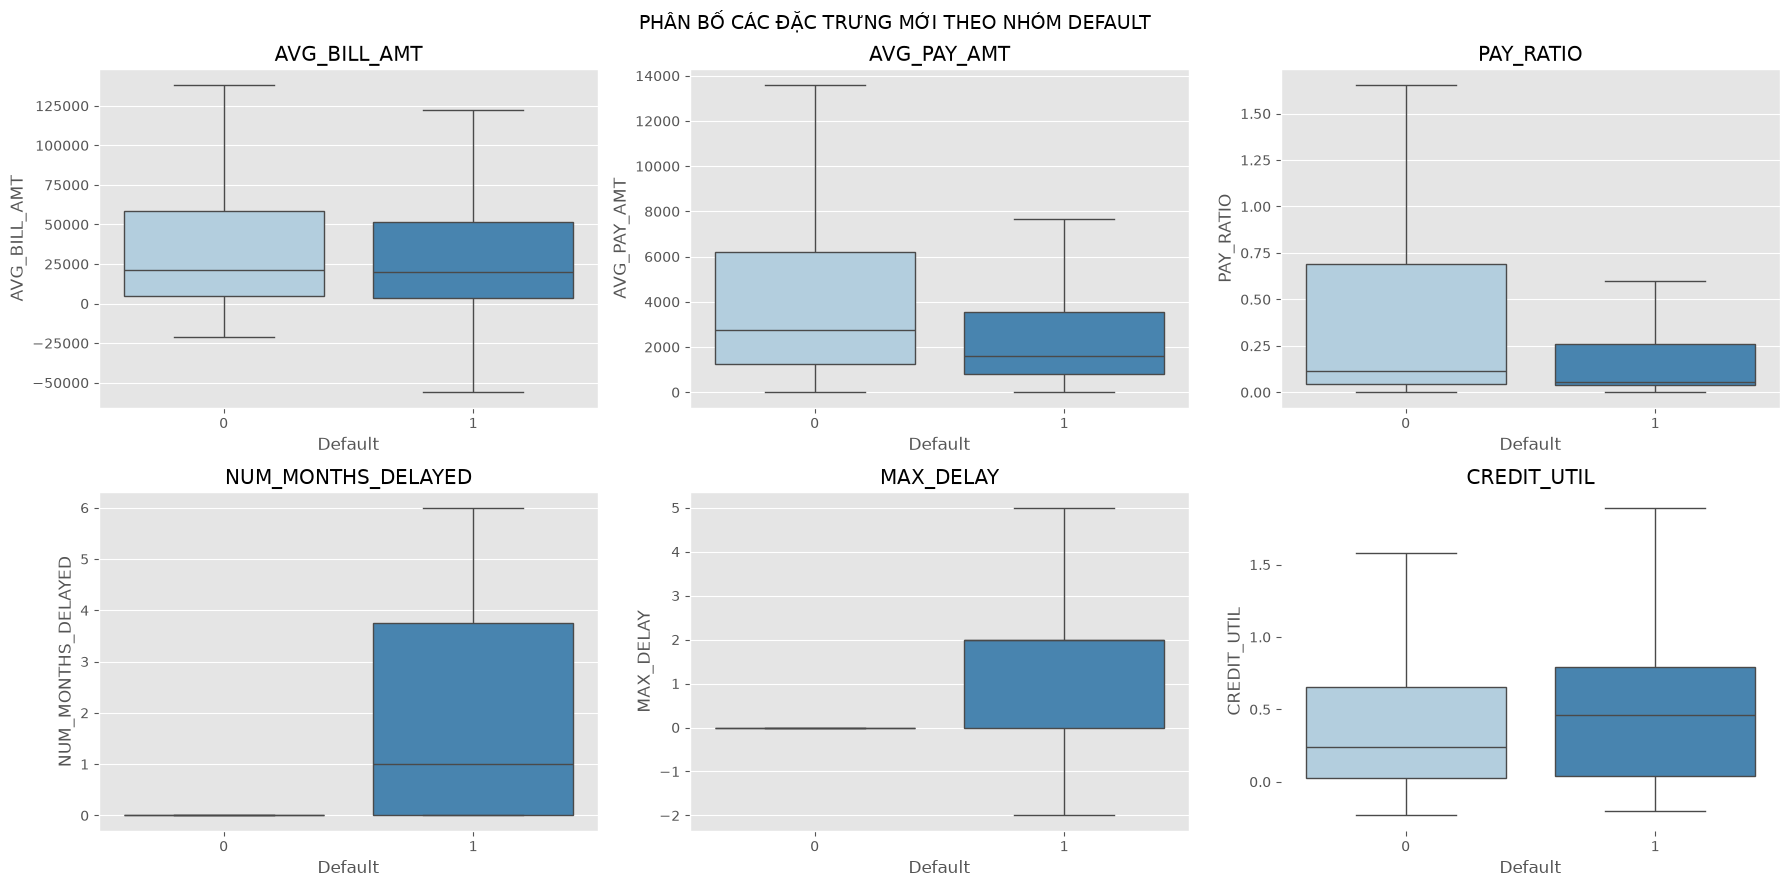

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), new_features):
    sns.boxplot(x='Default', y=col, data=data, palette='Blues', ax=ax, showfliers=False)
    ax.set_title(col)
plt.suptitle('PHÂN BỐ CÁC ĐẶC TRƯNG MỚI THEO NHÓM DEFAULT', size=14)
plt.tight_layout()
plt.box(False)
save_fig('new_features_boxplot')


Có thể quan sát PAY_RATIO, NUM_MONTHS_DELAYED và MAX_DELAY có xu hướng khác biệt rõ giữa hai nhóm — khách hàng vỡ nợ thường có tỷ lệ trả nợ thấp hơn và số tháng trễ hạn nhiều hơn, phù hợp với kỳ vọng nghiệp vụ và biện minh cho việc bổ sung các đặc trưng này.


Tách biến mục tiêu (target) và các đặc trưng (features), thực hiện **sau khi** đã hoàn tất Feature Engineering để `features` phản ánh đầy đủ các cột đã gộp nhóm và tạo mới:


In [15]:
y = data['Default']
features = data.drop('Default', axis=1)


<a id='eda'></a>
## Phân tích khám phá dữ liệu (EDA)

<a id='map'></a>
### Ánh xạ biến mục tiêu

Sau khi loại dòng trùng lặp, trong 29.965 chủ thẻ tín dụng có 6.630 thẻ vỡ nợ; tức là tỷ lệ vỡ nợ trong dữ liệu là 22,1% (22,13%).

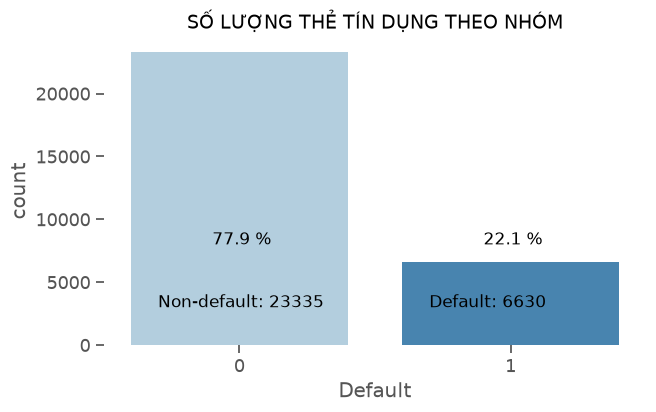

In [16]:
# Tần suất vỡ nợ
yes = data.Default.sum()
no = len(data)-yes

# Tỷ lệ phần trăm
yes_perc = round(yes/len(data)*100, 1)
no_perc = round(no/len(data)*100, 1)

plt.figure(figsize=(7,4))
sns.set_context('notebook', font_scale=1.2)
sns.countplot(x='Default', data=data, palette="Blues")
plt.annotate('Non-default: {}'.format(no), xy=(-0.3, 15000), xytext=(-0.3, 3000), size=12)
plt.annotate('Default: {}'.format(yes), xy=(0.7, 15000), xytext=(0.7, 3000), size=12)
plt.annotate(str(no_perc)+" %", xy=(-0.3, 15000), xytext=(-0.1, 8000), size=12)
plt.annotate(str(yes_perc)+" %", xy=(0.7, 15000), xytext=(0.9, 8000), size=12)
plt.title('SỐ LƯỢNG THẺ TÍN DỤNG THEO NHÓM', size=14)
# Bỏ khung
plt.box(False)
save_fig('default_count');


<a id='stat'></a>
### Thống kê mô tả
Bảng dưới đây trình bày thống kê mô tả các biến trong bộ dữ liệu.


In [17]:
pd.set_option('display.width', 100)
pd.set_option('display.precision', 2)

print("THỐNG KÊ TÓM TẮT CÁC CỘT SỐ")
print()
print(data.describe().T)


THỐNG KÊ TÓM TẮT CÁC CỘT SỐ

                      count       mean        std        min       25%        50%        75%  \
LIMIT_BAL           29965.0  167442.01  129760.14   10000.00  50000.00  140000.00  240000.00   
SEX                 29965.0       1.60       0.49       1.00      1.00       2.00       2.00   
EDUCATION           29965.0       1.84       0.74       1.00      1.00       2.00       2.00   
MARRIAGE            29965.0       1.56       0.52       1.00      1.00       2.00       2.00   
AGE                 29965.0      35.49       9.22      21.00     28.00      34.00      41.00   
PAY_0               29965.0      -0.02       1.12      -2.00     -1.00       0.00       0.00   
PAY_2               29965.0      -0.13       1.20      -2.00     -1.00       0.00       0.00   
PAY_3               29965.0      -0.16       1.20      -2.00     -1.00       0.00       0.00   
PAY_4               29965.0      -0.22       1.17      -2.00     -1.00       0.00       0.00   
PAY_5      

Hạn mức tín dụng (LIMIT_BAL) có giá trị trung bình 167.442 Đài tệ, độ lệch chuẩn 129.760 Đài tệ, trung vị 140.000 Đài tệ, dao động từ 10.000 đến 1.000.000 Đài tệ.<br>
Trình độ học vấn chủ yếu là đại học (2: 46,8%) và sau đại học (1: 35,3%), tiếp theo là trung học phổ thông (3: 16,4%); nhóm khác (4, sau khi gộp 0/5/6) chỉ chiếm 1,6%. Về hôn nhân, 53,2% độc thân, 45,5% đã kết hôn, 1,3% khác. Nữ chiếm 60,4%. Độ tuổi trung bình 35,5 tuổi, độ lệch chuẩn 9,2 tuổi (từ 21 đến 79 tuổi).<br>
BILL_AMT có giá trị âm (sao kê dư có, ví dụ BILL_AMT6 thấp nhất −339.603), còn PAY_RATIO lệch phải rất mạnh (trung bình 20,68, trung vị 0,09, độ lệch chuẩn 688) do một số khách hàng có sao kê rất nhỏ nhưng thanh toán lớn.

### Tần suất các biến giải thích theo nhóm vỡ nợ và không vỡ nợ


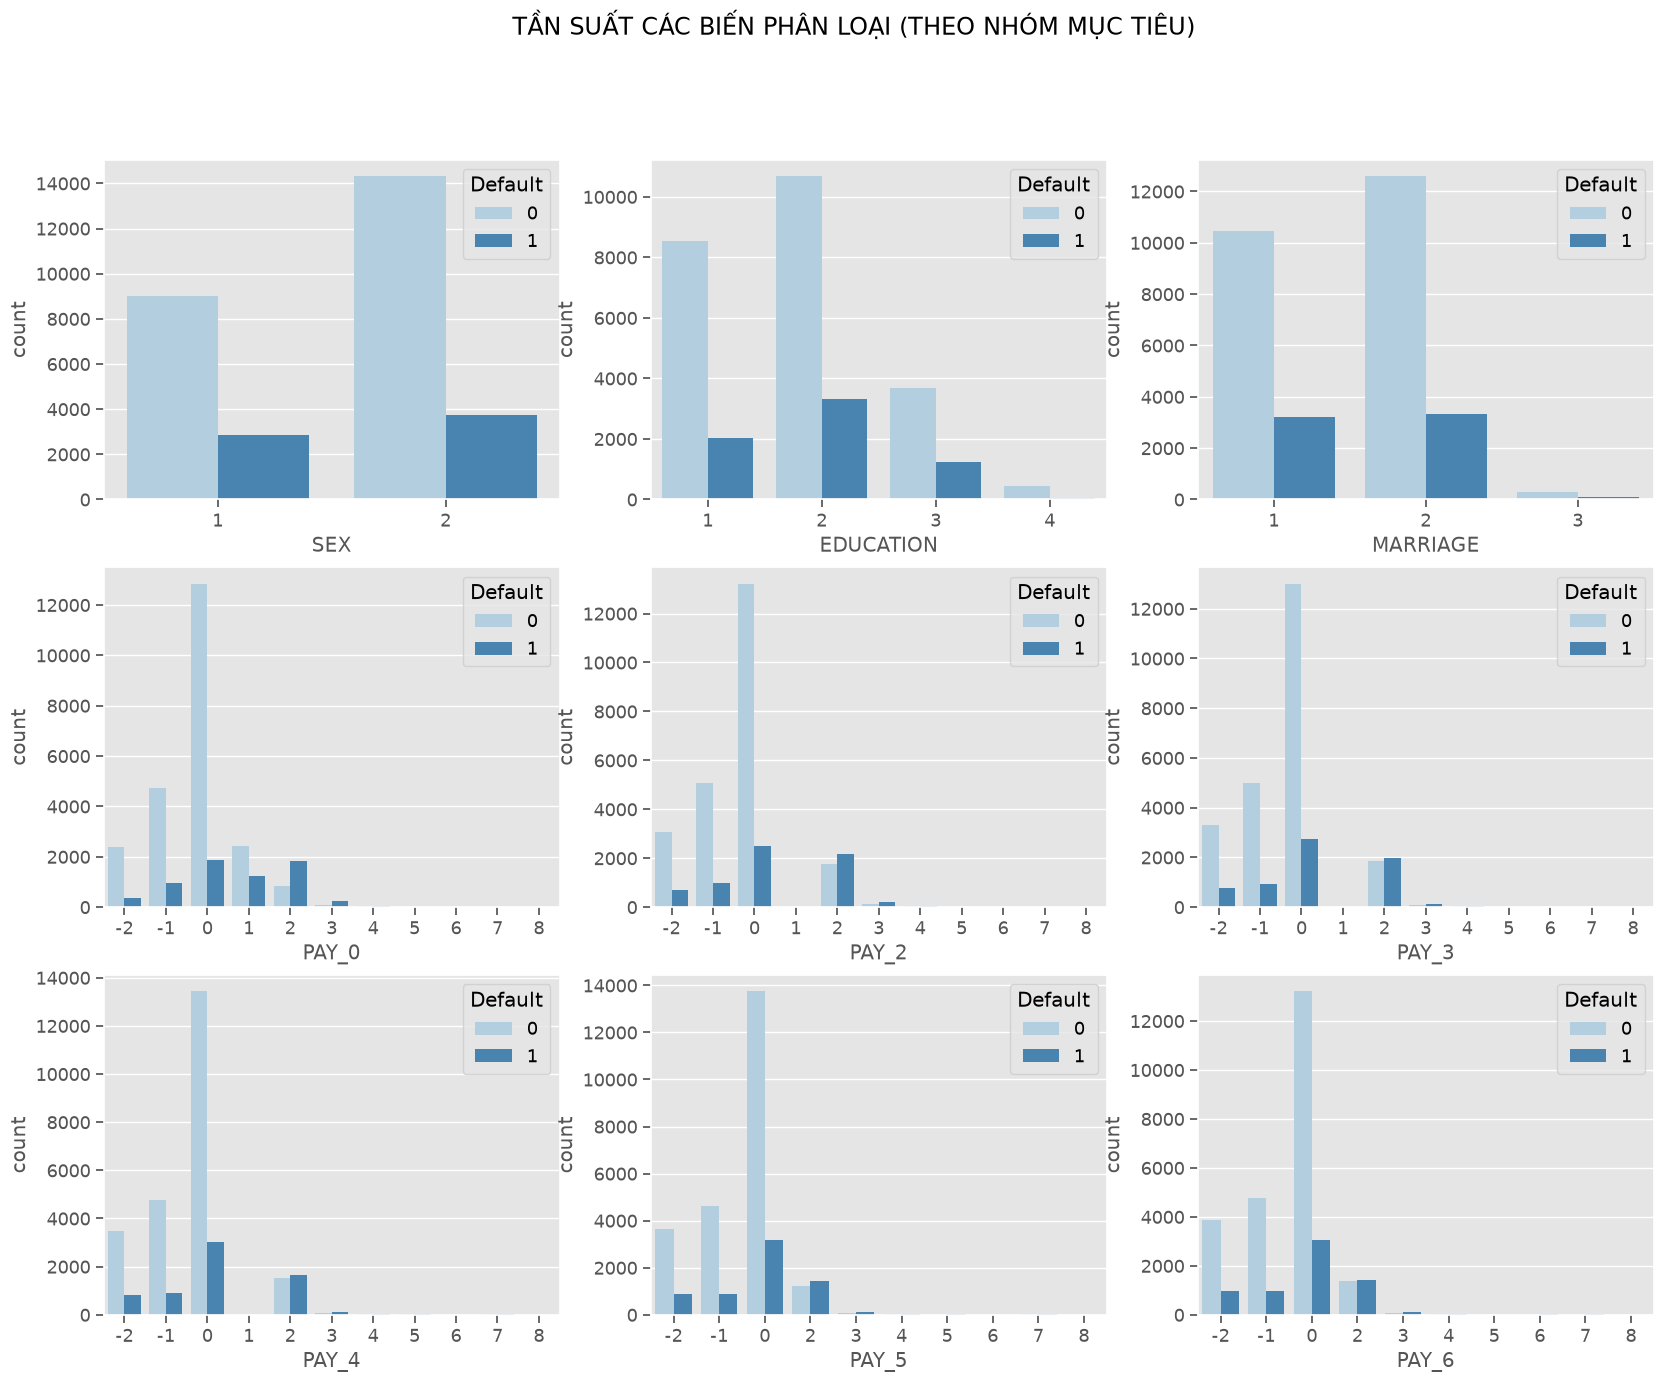

In [18]:
# Tạo một dataframe mới gồm các biến phân loại
subset = data[['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4',
               'PAY_5', 'PAY_6', 'Default']]

f, axes = plt.subplots(3, 3, figsize=(20, 15), facecolor='white')
f.suptitle('TẦN SUẤT CÁC BIẾN PHÂN LOẠI (THEO NHÓM MỤC TIÊU)')
ax1 = sns.countplot(x="SEX", hue="Default", data=subset, palette="Blues", ax=axes[0,0])
ax2 = sns.countplot(x="EDUCATION", hue="Default", data=subset, palette="Blues",ax=axes[0,1])
ax3 = sns.countplot(x="MARRIAGE", hue="Default", data=subset, palette="Blues",ax=axes[0,2])
ax4 = sns.countplot(x="PAY_0", hue="Default", data=subset, palette="Blues", ax=axes[1,0])
ax5 = sns.countplot(x="PAY_2", hue="Default", data=subset, palette="Blues", ax=axes[1,1])
ax6 = sns.countplot(x="PAY_3", hue="Default", data=subset, palette="Blues", ax=axes[1,2])
ax7 = sns.countplot(x="PAY_4", hue="Default", data=subset, palette="Blues", ax=axes[2,0])
ax8 = sns.countplot(x="PAY_5", hue="Default", data=subset, palette="Blues", ax=axes[2,1])
ax9 = sns.countplot(x="PAY_6", hue="Default", data=subset, palette="Blues", ax=axes[2,2])
save_fig('categorical_by_default');


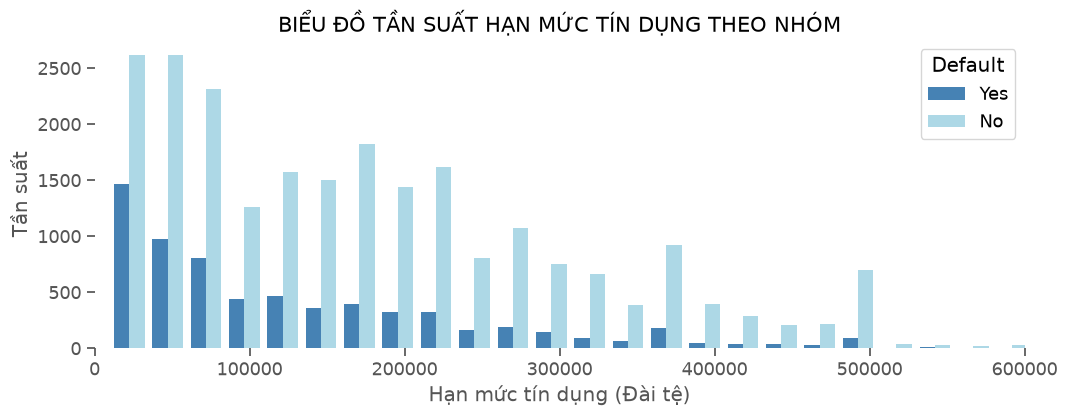

In [19]:
x1 = list(data[data['Default'] == 1]['LIMIT_BAL'])
x2 = list(data[data['Default'] == 0]['LIMIT_BAL'])

plt.figure(figsize=(12,4))
sns.set_context('notebook', font_scale=1.2)
plt.hist([x1, x2], bins = 40, density=False, color=['steelblue', 'lightblue'])
plt.xlim([0,600000])
plt.legend(['Yes', 'No'], title = 'Default', loc='upper right', facecolor='white')
plt.xlabel('Hạn mức tín dụng (Đài tệ)')
plt.ylabel('Tần suất')
plt.title('BIỂU ĐỒ TẦN SUẤT HẠN MỨC TÍN DỤNG THEO NHÓM', size=15)
plt.box(False)
save_fig('limit_bal_hist');


Bộ dữ liệu (sau khi loại trùng lặp) có 29.965 khách hàng sử dụng thẻ tín dụng.

Biểu đồ tần suất cho thấy nhóm vỡ nợ tập trung ở các mức hạn mức thấp; tỷ lệ vỡ nợ theo nhóm hạn mức được định lượng cụ thể ở mục [Tỷ lệ vỡ nợ theo nhóm](#rate).

Vì giá trị 0 của Default nghĩa là 'không vỡ nợ' và giá trị 1 nghĩa là 'vỡ nợ', trung bình 0,221 cho thấy có 22,1% hợp đồng thẻ tín dụng vỡ nợ vào tháng tiếp theo.

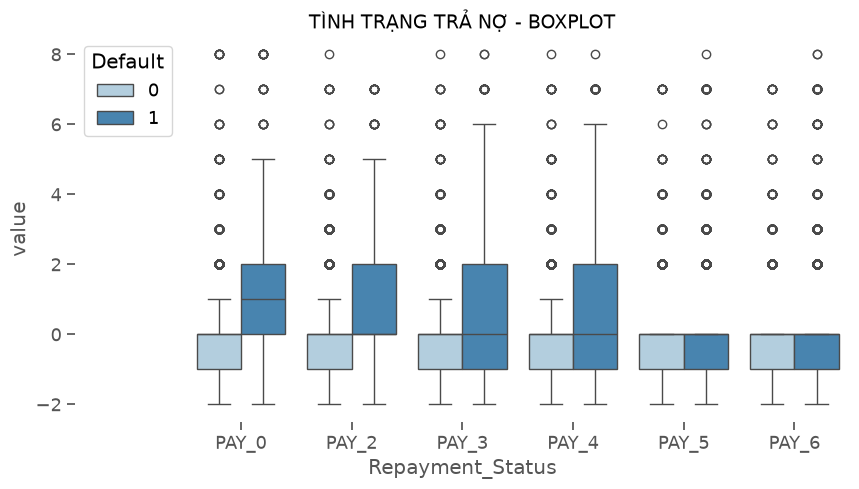

In [20]:
Repayment = data[['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']]

Repayment = pd.concat([y,Repayment],axis=1)
Repayment = pd.melt(Repayment,id_vars="Default",
                    var_name="Repayment_Status",
                    value_name='value')

plt.figure(figsize=(10,5))
sns.set_context('notebook', font_scale=1.2)
sns.boxplot(y="value", x="Repayment_Status", hue="Default", data=Repayment, palette='Blues')
plt.legend(loc='best', title= 'Default', facecolor='white')
plt.xlim([-1.5,5.5])
plt.title('TÌNH TRẠNG TRẢ NỢ - BOXPLOT', size=14)
plt.box(False)
save_fig('repayment_status_boxplot');


Có thể thấy PAY_0 (tình trạng trả nợ tháng 9) và PAY_2 (tình trạng trả nợ tháng 8) có khả năng phân biệt tốt hơn so với tình trạng trả nợ các tháng khác.


<a id='rate'></a>
### Tỷ lệ vỡ nợ theo nhóm

Bảng tỷ lệ vỡ nợ theo từng mức PAY_0, theo nhóm hạn mức LIMIT_BAL (5 phân vị), theo nhóm CREDIT_UTIL (5 phân vị) và theo số tháng trễ hạn NUM_MONTHS_DELAYED. Đây là thống kê mô tả trên toàn bộ dữ liệu (không có bước nào học tham số cho mô hình).

In [21]:
def default_rate_by(group):
    """Số khách hàng, số vỡ nợ và tỷ lệ vỡ nợ (%) theo nhóm."""
    g = data.groupby(group, observed=True)['Default']
    return pd.DataFrame({'so_KH': g.size(), 'so_vo_no': g.sum(),
                         'ty_le_vo_no_%': (g.mean() * 100).round(2)})

rate_pay0 = default_rate_by('PAY_0')
rate_limit = default_rate_by(pd.qcut(data['LIMIT_BAL'], q=5, duplicates='drop').rename('LIMIT_BAL (phân vị)'))
rate_util = default_rate_by(pd.qcut(data['CREDIT_UTIL'], q=5, duplicates='drop').rename('CREDIT_UTIL (phân vị)'))
rate_delay = default_rate_by('NUM_MONTHS_DELAYED')

for title, tbl in [('Theo PAY_0', rate_pay0), ('Theo LIMIT_BAL (5 phân vị)', rate_limit),
                   ('Theo CREDIT_UTIL (5 phân vị)', rate_util), ('Theo NUM_MONTHS_DELAYED', rate_delay)]:
    print(f"===== Tỷ lệ vỡ nợ {title} =====")
    print(tbl.to_string(), end='\n\n')

===== Tỷ lệ vỡ nợ Theo PAY_0 =====
       so_KH  so_vo_no  ty_le_vo_no_%
PAY_0                                
-2      2750       364          13.24
-1      5682       954          16.79
 0     14737      1888          12.81
 1      3667      1248          34.03
 2      2666      1843          69.13
 3       322       244          75.78
 4        76        52          68.42
 5        26        13          50.00
 6        11         6          54.55
 7         9         7          77.78
 8        19        11          57.89

===== Tỷ lệ vỡ nợ Theo LIMIT_BAL (5 phân vị) =====
                       so_KH  so_vo_no  ty_le_vo_no_%
LIMIT_BAL (phân vị)                                  
(9999.999, 50000.0]     7673      2439          31.79
(50000.0, 100000.0]     4817      1244          25.83
(100000.0, 180000.0]    6114      1215          19.87
(180000.0, 270000.0]    5412       913          16.87
(270000.0, 1000000.0]   5949       819          13.77

===== Tỷ lệ vỡ nợ Theo CREDIT_UTIL (5 ph

**Nhận xét:**

* **PAY_0:** các trạng thái không trễ hạn có tỷ lệ vỡ nợ thấp: −2 (không chi tiêu) 13,2%, −1 (trả hết) 16,8%, 0 (tín dụng quay vòng) 12,8%. Tỷ lệ tăng vọt khi bắt đầu trễ hạn: trễ 1 tháng 34,0%, trễ 2 tháng 69,1%, trễ 3 tháng 75,8%. Các mức ≥ 4 có tỷ lệ 50–78% nhưng rất ít mẫu (tổng 141 khách hàng) nên không ổn định. Quan hệ **không đơn điệu** ở vùng −2/−1/0 (−1 cao hơn 0) củng cố việc tạo cờ nhị phân thay vì coi PAY_x là biến liên tục.
* **LIMIT_BAL:** tỷ lệ vỡ nợ giảm đơn điệu theo hạn mức: 31,8% ở nhóm thấp nhất (≤ 50.000) → 25,8% → 19,9% → 16,9% → 13,8% ở nhóm cao nhất (> 270.000).
* **CREDIT_UTIL:** quan hệ hình chữ U: nhóm sử dụng gần như 0 (≤ 1,8% hạn mức, gồm cả khách hàng dư có) có tỷ lệ 22,7%, thấp nhất là nhóm 1,8–13,5% (14,2%), sau đó tăng dần lên 31,2% ở nhóm sử dụng > 75,8% hạn mức.
* **NUM_MONTHS_DELAYED:** tỷ lệ vỡ nợ tăng gần như đơn điệu từ 11,7% (không trễ tháng nào, 19.918 khách hàng) lên 29,9% (1 tháng), 38,8% (2), 50,9% (3), 57,3% (4–5) và 70,3% (trễ cả 6 tháng).

<a id='std'></a>
### Chuẩn hoá và trực quan hoá dữ liệu
Biểu đồ boxplot dưới đây cho thấy các đặc trưng có thang đo và đơn vị khác nhau. Nhiều mô hình sử dụng một dạng khoảng cách nào đó khi dự đoán, vì vậy nên chuẩn hoá dữ liệu.


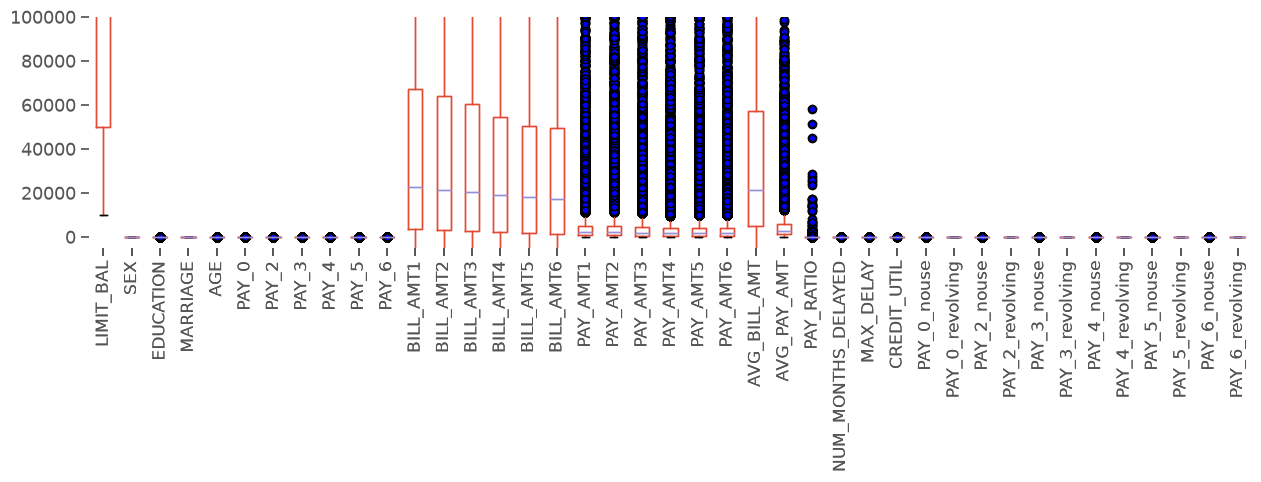

In [22]:
## dữ liệu có khoảng giá trị rất rộng (bên dưới), cần được chuẩn hoá.
plt.figure(figsize=(15,3))
ax= data.drop('Default', axis=1).boxplot(data.columns.name, rot=90)
outliers = dict(markerfacecolor='b', marker='p')
ax= features.boxplot(features.columns.name, rot=90, flierprops=outliers)
plt.xticks(size=12)
ax.set_ylim([-5000,100000])
plt.box(False)
save_fig('feature_ranges_boxplot');


Các đặc trưng (trừ các cờ nhị phân PAY_x_nouse/PAY_x_revolving) được chuẩn hoá (standardization) để trực quan hoá; nghĩa là mỗi đặc trưng có giá trị trung bình bằng 0 và phương sai bằng 1. **Phép chuẩn hoá này chỉ phục vụ vẽ biểu đồ**, không dùng cho mô hình — mô hình dùng `StandardScaler` nằm trong Pipeline, chỉ fit trên tập train.

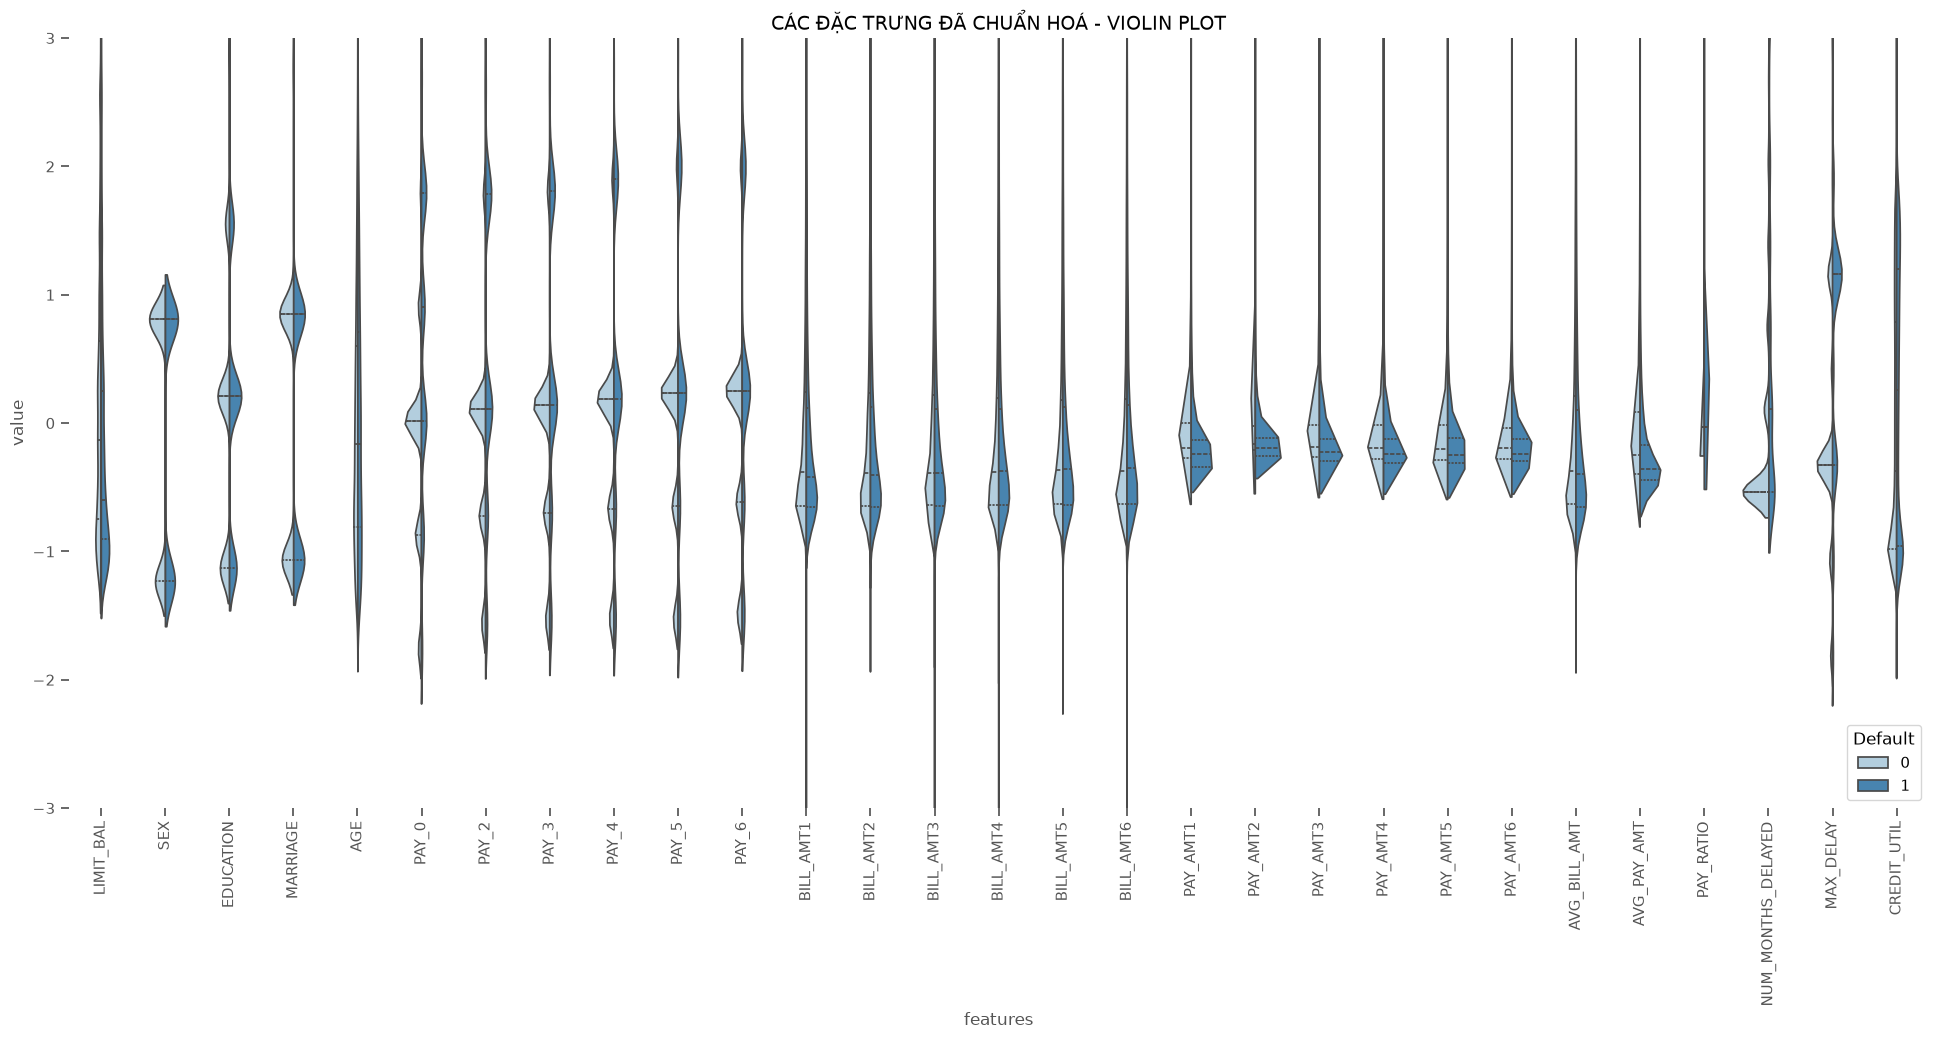

In [23]:
eda_features = features.drop(columns=flag_cols)
stdX = (eda_features - eda_features.mean()) / eda_features.std()  # chỉ phục vụ EDA
data_st = pd.concat([y,stdX.iloc[:,:]],axis=1)
data_st = pd.melt(data_st,id_vars="Default",
                    var_name="features",
                    value_name='value')
plt.figure(figsize=(24,10))
sns.set_context('notebook', font_scale=1)
sns.violinplot(y="value", x="features", hue="Default", data=data_st,split=True,
               inner="quart", palette='Blues')
plt.legend(loc=4, title= 'Default', facecolor='white')
plt.ylim([-3,3])
plt.xticks(rotation=90)
plt.title('CÁC ĐẶC TRƯNG ĐÃ CHUẨN HOÁ - VIOLIN PLOT', size=14)
plt.box(False)
save_fig('standardized_violin');


<a id='corr'></a>
### Tương quan
Ma trận tương quan giữa các biến được thể hiện qua biểu đồ heatmap bên dưới. Biến duy nhất có tương quan dương đáng kể với biến phụ thuộc 'Default' là tình trạng trả nợ tháng gần nhất (tháng 9). Tương quan âm cao nhất với default xảy ra ở Limit_Balance, cho thấy khách hàng có hạn mức tín dụng thấp hơn có xu hướng vỡ nợ nhiều hơn. Cũng có thể quan sát một số biến có tương quan cao với nhau, chẳng hạn giữa số tiền sao kê và tình trạng trả nợ ở các tháng khác nhau.

Xem xét ma trận tương quan, được xác định qua hệ số Pearson.


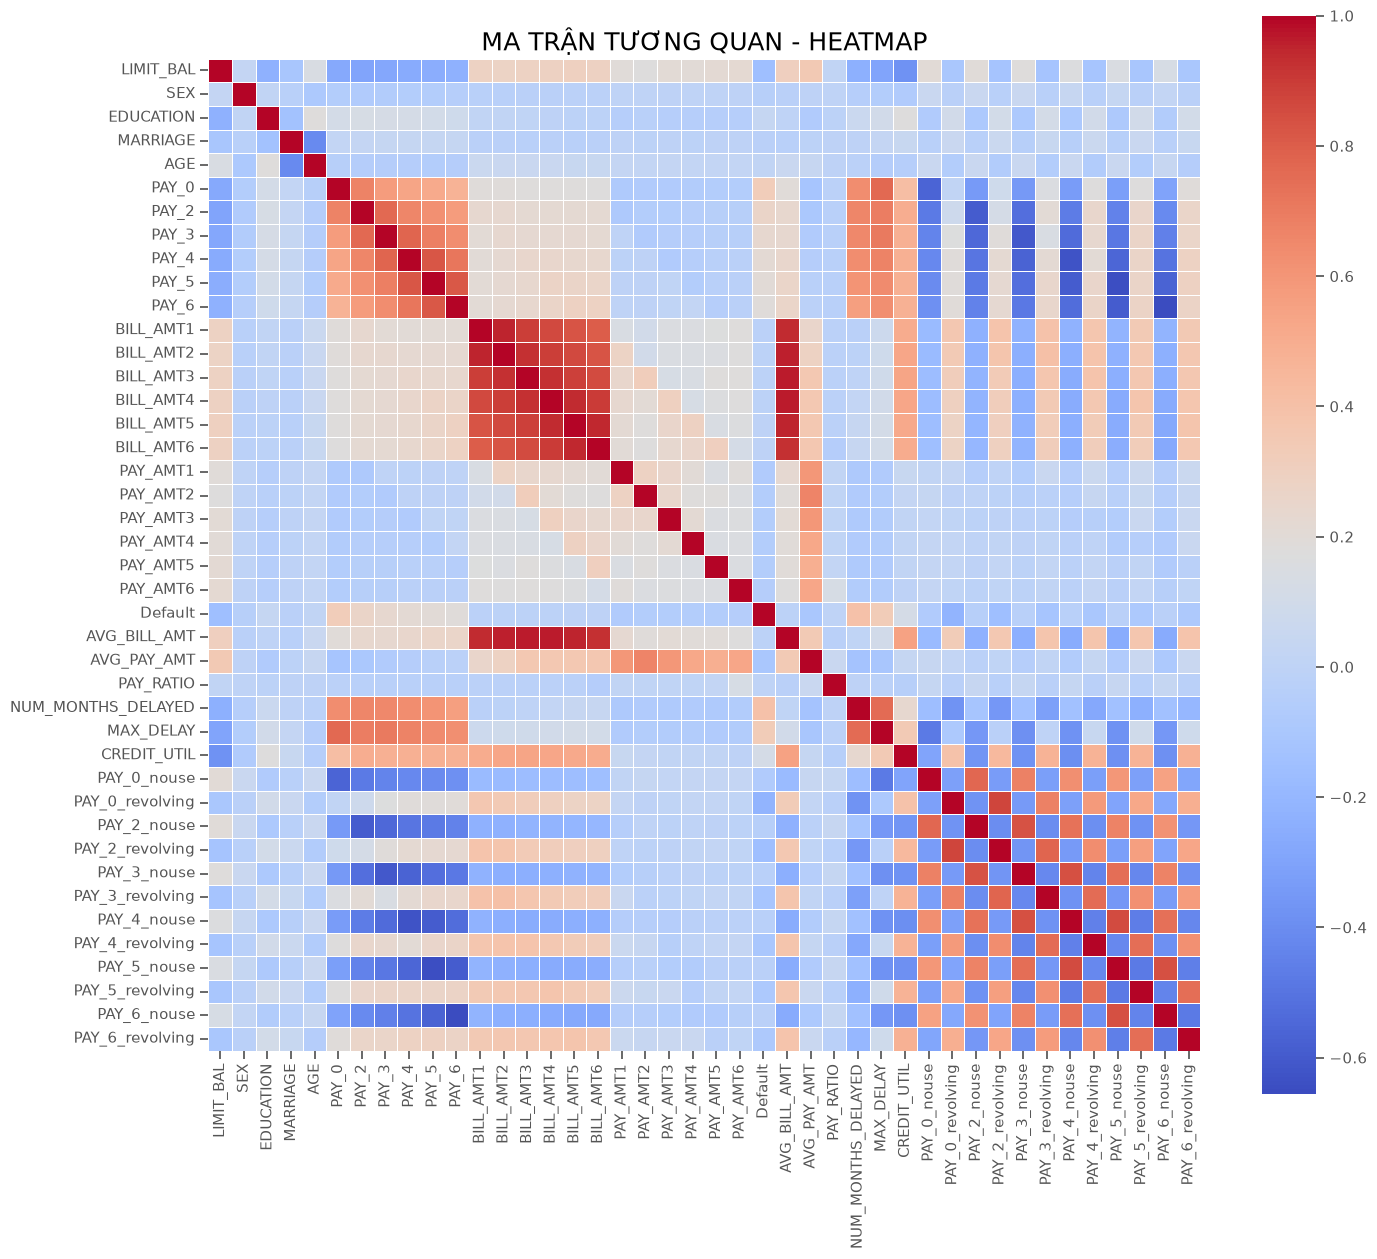

In [24]:
# xem xét ma trận tương quan, xác định qua hệ số Pearson
corr = data.corr() # .corr dùng để tìm tương quan
f,ax = plt.subplots(figsize=(16, 14))
sns.heatmap(corr, cbar = True,  square = True, annot = False, fmt= '.1f',
            xticklabels= True, yticklabels= True
            ,cmap="coolwarm", linewidths=.5, ax=ax)
plt.title('MA TRẬN TƯƠNG QUAN - HEATMAP', size=18)
save_fig('correlation_heatmap');


Heatmap cho thấy các đặc trưng có tương quan với nhau (đa cộng tuyến), ví dụ như PAY_0,2,3,4,5,6 và BILL_AMT1,2,3,4,5,6. Trong các trường hợp đó, tương quan là dương.

Dữ liệu không tương quan tiềm năng hữu ích hơn: có khả năng phân biệt tốt hơn!

**Tương quan có ý nghĩa gì?**<br>

Hãy thử fit riêng dữ liệu tương quan và không tương quan bằng hồi quy tuyến tính:


Dữ liệu không tương quan tiềm năng hữu ích hơn: có khả năng phân biệt tốt hơn!


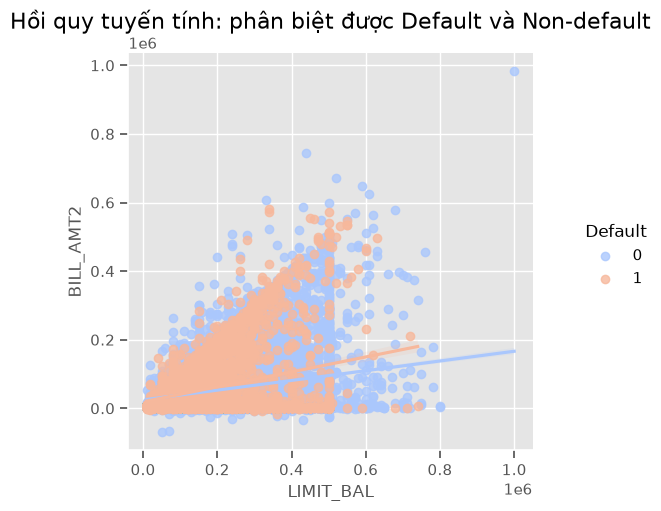

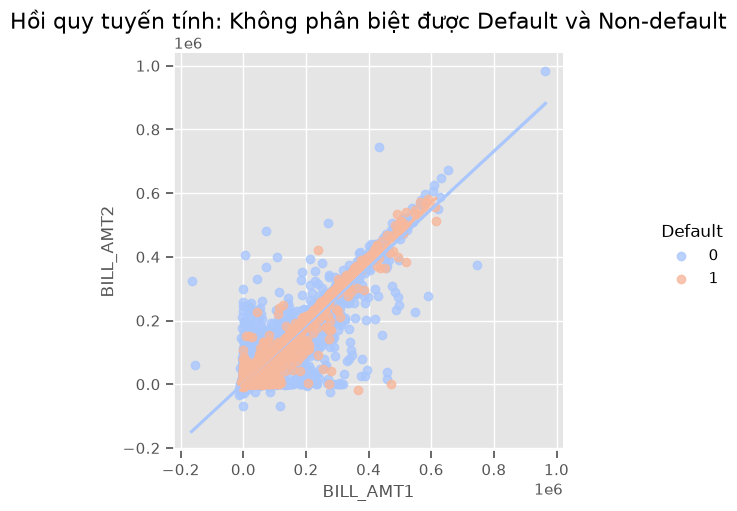

In [25]:
g1 = sns.lmplot(x='LIMIT_BAL', y= 'BILL_AMT2', data = data, hue ='Default',
           palette='coolwarm')
plt.title('Hồi quy tuyến tính: phân biệt được Default và Non-default', size=16)
save_fig('lmplot_limit_vs_bill2', g1.figure)

g2 = sns.lmplot(x='BILL_AMT1', y= 'BILL_AMT2', data = data, hue ='Default',
           palette='coolwarm')
plt.title('Hồi quy tuyến tính: Không phân biệt được Default và Non-default', size=16)
save_fig('lmplot_bill1_vs_bill2', g2.figure);

print('Dữ liệu không tương quan tiềm năng hữu ích hơn: có khả năng phân biệt tốt hơn!')

<a id='ml'></a>
## Học máy: Các mô hình phân loại

Ba mô hình phân loại được sử dụng trong đồ án này: Logistic Regression, Decision Tree và Random Forest Classifier.<br>

Dữ liệu được chia thành đặc trưng (X) và mục tiêu (y), sau đó chia thành tập train (80%) và test (20%) — dùng **chung một cách chia** cho cả 3 mô hình (stratify theo y, random_state=42). **Mọi bước có học tham số từ dữ liệu** (StandardScaler, OneHotEncoder, SMOTE) đều nằm trong `Pipeline` và chỉ được fit trên tập train (hoặc trên phần train của từng fold khi cross-validation). Tập test chỉ được dùng một lần ở bước đánh giá cuối.

Hai tập đặc trưng được sử dụng:

* **Mô hình cây (Decision Tree, Random Forest):** toàn bộ đặc trưng, EDUCATION/MARRIAGE giữ mã hoá số, không chuẩn hoá (mô hình cây không nhạy với thang đo).
* **Logistic Regression:** bỏ AVG_BILL_AMT và AVG_PAY_AMT (là tổ hợp tuyến tính của BILL_AMT1–6 và PAY_AMT1–6, gây đa cộng tuyến hoàn hảo — xem mục [VIF](#vif)); one-hot EDUCATION và MARRIAGE (bỏ nhóm đầu làm nhóm tham chiếu); chuẩn hoá các cột còn lại bằng StandardScaler.

<a id='imb'></a>
### Xử lý mất cân bằng dữ liệu

Như đã chỉ ra ở phần EDA, khách hàng vỡ nợ chỉ chiếm **22,1%** dữ liệu (6.630/29.965) — đây là bài toán phân loại mất cân bằng (imbalanced classification). Nếu không xử lý, mô hình có xu hướng thiên về dự đoán lớp đa số (non-default), dẫn đến recall thấp cho lớp thiểu số (default) — trong khi đây lại là lớp quan trọng nhất đối với ngân hàng.

Mỗi mô hình được thử nghiệm với 3 phương án:

1. **`none`**: không xử lý mất cân bằng.
2. **`balanced`**: `class_weight='balanced'` — tự động tăng trọng số cho lớp thiểu số khi tính hàm mất mát.
3. **`smote`**: SMOTE (Synthetic Minority Over-sampling Technique, thư viện `imbalanced-learn`) đặt **bên trong Pipeline**, nên chỉ sinh mẫu tổng hợp trên phần dữ liệu đang được fit (train/fold train), không bao giờ chạm vào tập test hay fold validation. Vì SMOTE dựa trên khoảng cách k-láng giềng, dữ liệu được chuẩn hoá trước bước SMOTE (với mô hình cây, bước chuẩn hoá này không ảnh hưởng đến cách chia nút).

<a id='sp'></a>
### Chia tập dữ liệu: train và test

Cả 3 mô hình nhận cùng `X_train`/`X_test`; Pipeline của Logistic Regression tự chọn tập cột của mình (bỏ AVG_BILL_AMT, AVG_PAY_AMT) thông qua `ColumnTransformer`.

In [26]:
X = features
y = data['Default']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

# Tập đặc trưng cho Logistic Regression
lr_drop_cols = ['AVG_BILL_AMT', 'AVG_PAY_AMT']   # tổ hợp tuyến tính của BILL_AMT1-6 / PAY_AMT1-6
lr_cat_cols = ['EDUCATION', 'MARRIAGE']           # one-hot
lr_num_cols = [c for c in X.columns if c not in lr_drop_cols + lr_cat_cols]

print(f"Kích thước tập train: {X_train.shape}, tập test: {X_test.shape}")
print(f"Tỷ lệ default trong tập train: {y_train.mean():.3f}, tập test: {y_test.mean():.3f}")
print(f"Số đặc trưng cho mô hình cây: {X.shape[1]}; cho Logistic Regression (trước one-hot): "
      f"{len(lr_num_cols) + len(lr_cat_cols)}")

Kích thước tập train: (23972, 41), tập test: (5993, 41)
Tỷ lệ default trong tập train: 0.221, tập test: 0.221
Số đặc trưng cho mô hình cây: 41; cho Logistic Regression (trước one-hot): 39


<a id='vif'></a>
### Đa cộng tuyến (VIF) cho Logistic Regression

Hệ số phóng đại phương sai VIF<sub>j</sub> = 1 / (1 − R<sub>j</sub><sup>2</sup>), với R<sub>j</sub><sup>2</sup> là hệ số xác định khi hồi quy đặc trưng j theo tất cả đặc trưng còn lại. VIF<sub>j</sub> cũng chính là phần tử đường chéo thứ j của ma trận nghịch đảo của ma trận tương quan. Quy ước thường dùng: VIF > 10 là đa cộng tuyến nghiêm trọng.

VIF được tính trên **tập train**, với ma trận thiết kế giống hệt đầu vào của Logistic Regression (one-hot EDUCATION/MARRIAGE, bỏ nhóm đầu).

In [27]:
def design_matrix(df, cols):
    return pd.get_dummies(df[cols], columns=lr_cat_cols, drop_first=True, dtype=float)

def vif_table(design):
    return pd.Series(np.linalg.inv(design.corr().values).diagonal(),
                     index=design.columns, name='VIF').sort_values(ascending=False)

# Nếu giữ AVG_BILL_AMT, AVG_PAY_AMT: ma trận tương quan suy biến (hạng < số cột) => VIF = vô cùng
design_with_avg = design_matrix(X_train, lr_num_cols + lr_drop_cols + lr_cat_cols)
print(f"Giữ AVG_*: {design_with_avg.shape[1]} cột, hạng ma trận tương quan = "
      f"{np.linalg.matrix_rank(design_with_avg.corr().values)}")

design_lr = design_matrix(X_train, lr_num_cols + lr_cat_cols)
print(f"Bỏ AVG_* : {design_lr.shape[1]} cột, hạng ma trận tương quan = "
      f"{np.linalg.matrix_rank(design_lr.corr().values)}")

vif = vif_table(design_lr)
print(f"\nSố đặc trưng có VIF > 10: {(vif > 10).sum()} / {len(vif)}")
vif.round(2).to_frame()

Giữ AVG_*: 44 cột, hạng ma trận tương quan = 42


Bỏ AVG_* : 42 cột, hạng ma trận tương quan = 42

Số đặc trưng có VIF > 10: 7 / 42


,VIF
BILL_AMT2,28.27
BILL_AMT5,25.56
BILL_AMT3,22.47
NUM_MONTHS_DELAYED,21.54
BILL_AMT4,21.11
BILL_AMT1,15.69
BILL_AMT6,15.45
PAY_5_nouse,7.40
PAY_4_nouse,7.12
PAY_2_nouse,6.91


**Nhận xét VIF:**

* Nếu giữ AVG_BILL_AMT và AVG_PAY_AMT, ma trận tương quan 44 cột chỉ có hạng 42 → **suy biến** (đa cộng tuyến hoàn hảo, VIF = ∞). Sau khi bỏ hai cột này, ma trận 42 cột có hạng đầy đủ.
* Còn **7/42 đặc trưng có VIF > 10**: BILL_AMT1–6 (VIF từ 15,5 đến 28,3, do sao kê các tháng liên tiếp tương quan rất cao) và NUM_MONTHS_DELAYED (21,5, do được tính trực tiếp từ PAY_x). Các cờ PAY_x_nouse/PAY_x_revolving và PAY_x có VIF 3–7,4; các biến nhân khẩu học, PAY_AMT, PAY_RATIO đều < 2,5.
* Ở bước này ta **chưa loại thêm** đặc trưng: Logistic Regression dùng điều chuẩn L2 mặc định (C = 1) giúp ổn định hệ số khi có đa cộng tuyến, nhưng cần lưu ý hệ số của từng BILL_AMT riêng lẻ không nên diễn giải độc lập. Việc gộp/bỏ BILL_AMT là ứng viên cho bước tinh chỉnh tiếp theo.

<a id='train'></a>
### Huấn luyện mô hình

Ở bước này **chưa tinh chỉnh siêu tham số**: cả 3 mô hình dùng siêu tham số mặc định của scikit-learn (Logistic Regression: `C=1.0`, `max_iter=5000`; Decision Tree: cây không giới hạn độ sâu; Random Forest: 100 cây). Mỗi mô hình được thử với 3 phương án xử lý mất cân bằng (`none`, `balanced`, `smote`), đánh giá bằng `StratifiedKFold(n_splits=5)` **chỉ trên tập train**. Tập test hoàn toàn không tham gia vào việc lựa chọn.

#### Logistic Regression

Logistic Regression là một trong những thuật toán đơn giản nhất, ước lượng mối quan hệ giữa một biến nhị phân phụ thuộc và các biến độc lập, tính xác suất xảy ra của một sự kiện. Tham số điều chuẩn C kiểm soát sự đánh đổi giữa việc tăng độ phức tạp (overfitting) và giữ mô hình đơn giản (underfitting).


#### Decision Tree

Decision Tree là một thuật toán phổ biến cho bài toán phân loại vì dễ diễn giải. Một node nội bộ đại diện cho một đặc trưng, nhánh đại diện cho một quy tắc quyết định, và mỗi node lá đại diện cho kết quả. Decision Tree không cần chuẩn hoá dữ liệu, nhưng dễ bị overfit với dữ liệu nhiễu và cho kết quả thiên lệch khi dữ liệu mất cân bằng.


#### Random Forest

Random Forest gồm nhiều Decision Tree kết hợp lại. Mô hình tạo ra các tập con ngẫu nhiên khác nhau từ tập train làm các bộ dự đoán và chọn lời giải tốt nhất bằng cách bỏ phiếu (voting), nhờ đó tránh được overfitting.


In [28]:
model_names = {'lr': 'Logistic Regression', 'dt': 'Decision Tree', 'rf': 'Random Forest'}
variants = ['none', 'balanced', 'smote']


def make_model(kind, variant):
    """Tạo Pipeline cho mô hình `kind` ('lr'|'dt'|'rf') với phương án mất cân bằng `variant`."""
    class_weight = 'balanced' if variant == 'balanced' else None
    if kind == 'lr':
        steps = [('prep', ColumnTransformer([
            ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), lr_cat_cols),
            ('scale', StandardScaler(), lr_num_cols),
        ], remainder='drop', verbose_feature_names_out=False))]  # remainder='drop' loại AVG_BILL_AMT, AVG_PAY_AMT
        clf = LogisticRegression(class_weight=class_weight, max_iter=5000, random_state=RANDOM_STATE)
    else:
        # Mô hình cây không cần chuẩn hoá; chỉ chuẩn hoá khi có SMOTE (SMOTE dùng khoảng cách kNN)
        steps = [('scale', StandardScaler())] if variant == 'smote' else []
        cls = DecisionTreeClassifier if kind == 'dt' else RandomForestClassifier
        clf = cls(class_weight=class_weight, random_state=RANDOM_STATE)
    if variant == 'smote':
        steps.append(('smote', SMOTE(random_state=RANDOM_STATE)))
    return Pipeline(steps + [('clf', clf)])


skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'average_precision']

cv_all = {}
for kind in model_names:
    for variant in variants:
        cv_all[(kind, variant)] = cross_validate(make_model(kind, variant), X_train, y_train,
                                                 cv=skf, scoring=scoring, n_jobs=-1)

cv_table = pd.DataFrame({
    (model_names[k], v): {m: s[f'test_{m}'].mean() for m in scoring}
    for (k, v), s in cv_all.items()
}).T.round(4)
cv_table.index.names = ['Model', 'Phương án']
cv_table.columns = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']
print("Kết quả 5-fold CV trên tập train (trung bình qua 5 fold):")
cv_table.style.format('{:.4f}')

Kết quả 5-fold CV trên tập train (trung bình qua 5 fold):


Với bài toán ngân hàng, chi phí bỏ sót một khách hàng sắp vỡ nợ (false negative) thường cao hơn chi phí cảnh báo nhầm (false positive), do đó với mỗi mô hình ta chọn phương án có **Recall trung bình 5-fold trên tập train** cao nhất, kể cả khi phải đánh đổi một phần Precision hoặc Accuracy. Phương án được chọn sau đó được fit lại trên toàn bộ tập train.

In [29]:
# Chọn phương án theo Recall CV trên train — KHÔNG dùng tập test
chosen = {k: max(variants, key=lambda v: cv_all[(k, v)]['test_recall'].mean()) for k in model_names}
fitted = {k: make_model(k, chosen[k]).fit(X_train, y_train) for k in model_names}
LR, Tree, Ran = fitted['lr'], fitted['dt'], fitted['rf']

for k, v in chosen.items():
    print(f"{model_names[k]}: chọn phương án '{v}' (Recall CV = {cv_all[(k, v)]['test_recall'].mean():.4f})")

Logistic Regression: chọn phương án 'balanced' (Recall CV = 0.6135)
Decision Tree: chọn phương án 'smote' (Recall CV = 0.4600)
Random Forest: chọn phương án 'balanced' (Recall CV = 0.4981)


**Nhận xét (CV 5-fold trên train, siêu tham số mặc định):**

* **Logistic Regression:** `balanced` (Recall 0,6135) và `smote` (0,61) gần như tương đương, cả hai tăng Recall từ 0,37 lên ~0,61 so với `none`, đổi lại Precision giảm từ 0,65 xuống ~0,46; ROC-AUC không đổi (0,77) — xử lý mất cân bằng chủ yếu dịch chuyển ngưỡng quyết định chứ không làm mô hình phân biệt tốt hơn.
* **Decision Tree:** cây không giới hạn độ sâu bị overfit rõ rệt (ROC-AUC chỉ 0,61, PR-AUC 0,29 ở cả 3 phương án); `smote` cho Recall cao nhất (0,46) nên được chọn. Đây là mô hình được kỳ vọng cải thiện nhiều nhất khi tinh chỉnh `max_depth`, `min_samples_leaf`.
* **Random Forest:** `balanced` được chọn (Recall 0,50, F1 0,52), tốt hơn `smote` (0,49) một chút.

<a id='eval'></a>
### Đánh giá mô hình trên tập test

Với mỗi mô hình: in `classification_report`, vẽ confusion matrix, tính ROC-AUC, vẽ đường cong Precision-Recall và tính PR-AUC. Do dữ liệu mất cân bằng, PR-AUC phản ánh hiệu năng thực tế trên lớp thiểu số (default) tốt hơn ROC-AUC.


In [30]:
def evaluate_model(model, X_te, y_te, name):
    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]

    print(f"===== {name} =====")
    print(classification_report(y_te, y_pred))

    report = classification_report(y_te, y_pred, output_dict=True)
    roc_auc = roc_auc_score(y_te, y_proba)
    pr_auc = average_precision_score(y_te, y_proba)
    print(f"ROC-AUC: {roc_auc:.4f}   PR-AUC: {pr_auc:.4f}")

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    cm = confusion_matrix(y_te, y_pred)
    sns.heatmap(cm, annot=True, cmap="Blues", fmt="d",
                xticklabels=['Non-default', 'Default'],
                yticklabels=['Non-default', 'Default'], ax=axes[0])
    axes[0].set_title(f'Confusion Matrix - {name}')
    axes[0].set_xlabel('Predicted label')
    axes[0].set_ylabel('True label')

    fpr, tpr, _ = roc_curve(y_te, y_proba)
    axes[1].plot(fpr, tpr, label=f'AUC={roc_auc:.2f}')
    axes[1].plot([0, 1], [0, 1], 'k--')
    axes[1].set_title(f'ROC Curve - {name}')
    axes[1].set_xlabel('False Positive Rate')
    axes[1].set_ylabel('True Positive Rate')
    axes[1].legend(loc='lower right')

    precision, recall, _ = precision_recall_curve(y_te, y_proba)
    axes[2].plot(recall, precision, label=f'PR-AUC={pr_auc:.2f}')
    axes[2].set_title(f'Precision-Recall Curve - {name}')
    axes[2].set_xlabel('Recall')
    axes[2].set_ylabel('Precision')
    axes[2].legend(loc='lower left')

    plt.tight_layout()
    save_fig(f"eval_{name.lower().replace(' ', '_')}", fig)
    plt.show()

    return {
        'precision': report['1']['precision'],
        'recall': report['1']['recall'],
        'f1': report['1']['f1-score'],
        'roc_auc': roc_auc,
        'pr_auc': pr_auc,
    }


===== Logistic Regression =====
              precision    recall  f1-score   support

           0       0.87      0.80      0.84      4667
           1       0.46      0.59      0.52      1326

    accuracy                           0.76      5993
   macro avg       0.67      0.70      0.68      5993
weighted avg       0.78      0.76      0.77      5993

ROC-AUC: 0.7616   PR-AUC: 0.5275


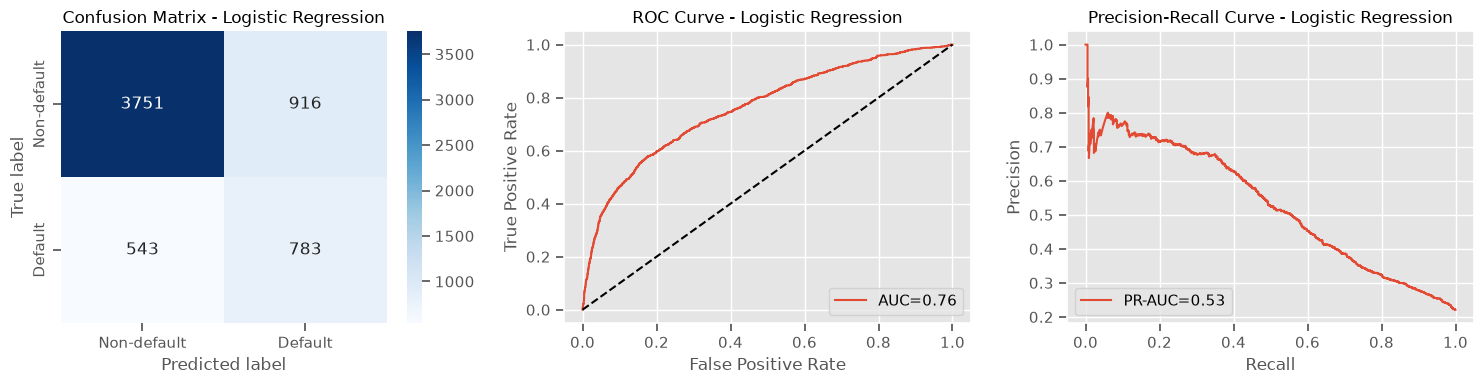

In [31]:
lr_test_metrics = evaluate_model(LR, X_test, y_test, 'Logistic Regression')

===== Decision Tree =====
              precision    recall  f1-score   support

           0       0.84      0.76      0.80      4667
           1       0.37      0.48      0.42      1326

    accuracy                           0.70      5993
   macro avg       0.60      0.62      0.61      5993
weighted avg       0.73      0.70      0.71      5993



ROC-AUC: 0.6221   PR-AUC: 0.2910


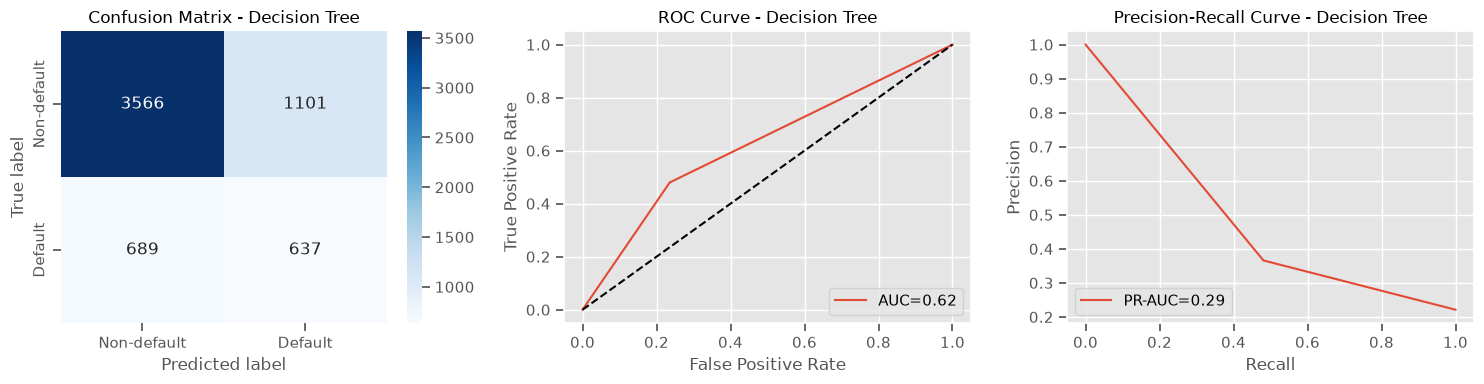

In [32]:
dt_test_metrics = evaluate_model(Tree, X_test, y_test, 'Decision Tree')

===== Random Forest =====
              precision    recall  f1-score   support

           0       0.86      0.89      0.87      4667
           1       0.54      0.48      0.51      1326

    accuracy                           0.80      5993
   macro avg       0.70      0.68      0.69      5993
weighted avg       0.79      0.80      0.79      5993

ROC-AUC: 0.7607   PR-AUC: 0.5279


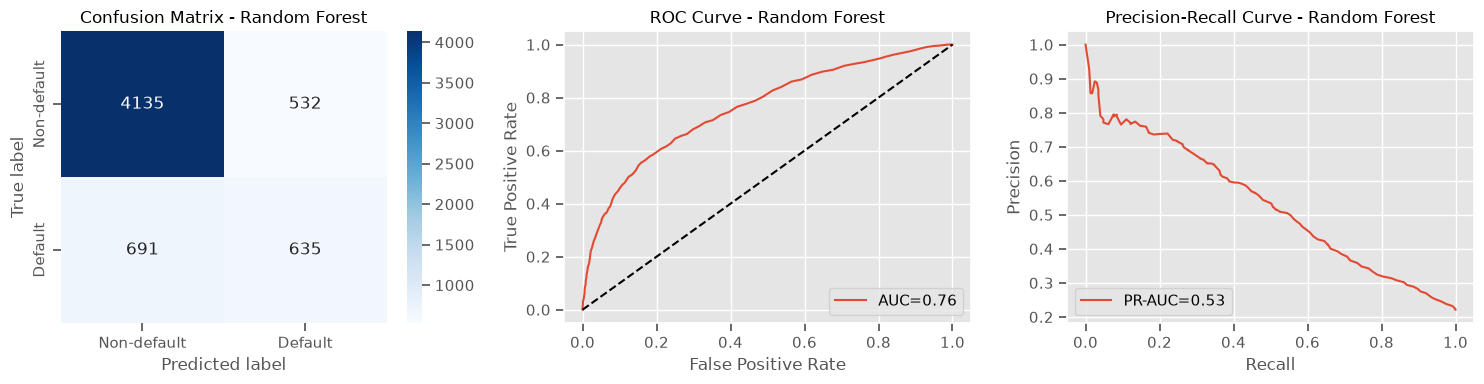

In [33]:
rf_test_metrics = evaluate_model(Ran, X_test, y_test, 'Random Forest')

**Kết quả trên tập test (5.993 khách hàng, 1.326 vỡ nợ):**

| Mô hình (phương án) | Precision | Recall | F1 | ROC-AUC | PR-AUC | Accuracy |
|---|---|---|---|---|---|---|
| Logistic Regression (balanced) | 0,46 | 0,59 | 0,52 | 0,7616 | 0,5275 | 0,76 |
| Decision Tree (smote) | 0,37 | 0,48 | 0,42 | 0,6221 | 0,2910 | 0,70 |
| Random Forest (balanced) | 0,54 | 0,48 | 0,51 | 0,7607 | 0,5279 | 0,80 |

Kết quả trên test khớp với CV trên train (chênh lệch < 0,02), cho thấy không có dấu hiệu rò rỉ dữ liệu hay lựa chọn quá khớp với tập test. Logistic Regression và Random Forest có ROC-AUC/PR-AUC gần như bằng nhau; LR có Recall cao hơn (0,59 so với 0,48), RF có Precision và Accuracy cao hơn.

<a id='roc'></a>
### So sánh ROC và Precision-Recall giữa 3 mô hình

Receiver Operating Characteristic (ROC) là đồ thị của True Positive Rate so với False Positive Rate. AUC (Area Under Curve) càng cao thể hiện mô hình phân biệt càng tốt giữa hai lớp; AUC = 0.5 nghĩa là mô hình không có khả năng phân biệt.


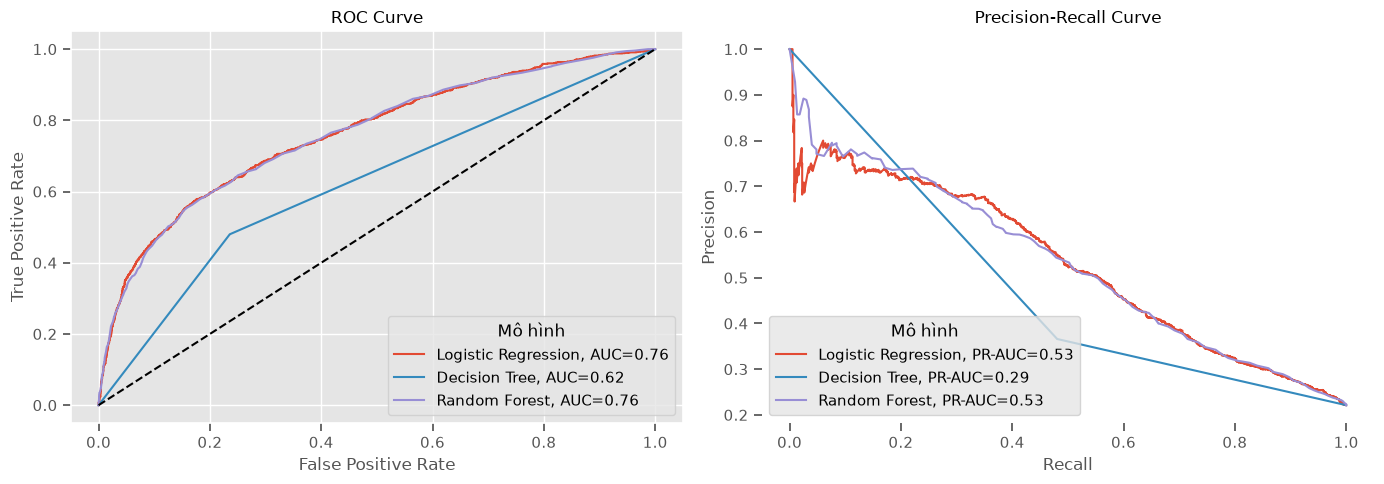

In [34]:
models_for_plot = {
    'Logistic Regression': (LR, X_test),
    'Decision Tree': (Tree, X_test),
    'Random Forest': (Ran, X_test),
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, (model, X_te) in models_for_plot.items():
    y_proba = model.predict_proba(X_te)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    axes[0].plot(fpr, tpr, label=f'{name}, AUC={auc:.2f}')

    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    pr_auc = average_precision_score(y_test, y_proba)
    axes[1].plot(recall, precision, label=f'{name}, PR-AUC={pr_auc:.2f}')

axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_title('ROC Curve')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right', title='Mô hình')

axes[1].set_title('Precision-Recall Curve')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left', title='Mô hình')

plt.tight_layout()
plt.box(False)
save_fig('roc_pr_comparison')


AUC càng cao (gần 1) thể hiện mô hình phân biệt tốt hơn giữa hai lớp. Với dữ liệu mất cân bằng, PR-AUC phản ánh hiệu năng trên lớp thiểu số (default) thực tế hơn ROC-AUC, vì ROC-AUC có thể "lạc quan giả" khi số lượng mẫu âm (non-default) áp đảo.


<a id='cv'></a>
### Đánh giá chéo (Cross-Validation) với StratifiedKFold

Kết quả `StratifiedKFold(n_splits=5)` + `cross_validate` của phương án được chọn cho mỗi mô hình (đã tính ở mục Huấn luyện, **chỉ trên tập train**): accuracy, f1, roc_auc và average_precision (PR-AUC) qua từng fold. Toàn bộ tiền xử lý (scaler, one-hot, SMOTE) nằm trong Pipeline nên chỉ được fit trên phần train của từng fold.

In [35]:
cv_results = {model_names[k]: cv_all[(k, chosen[k])] for k in model_names}

for name, scores in cv_results.items():
    print(f"{name}: "
          f"accuracy={scores['test_accuracy'].mean():.4f}±{scores['test_accuracy'].std():.4f}, "
          f"f1={scores['test_f1'].mean():.4f}±{scores['test_f1'].std():.4f}, "
          f"roc_auc={scores['test_roc_auc'].mean():.4f}±{scores['test_roc_auc'].std():.4f}, "
          f"pr_auc={scores['test_average_precision'].mean():.4f}±{scores['test_average_precision'].std():.4f}")

Logistic Regression: accuracy=0.7578±0.0059, f1=0.5285±0.0097, roc_auc=0.7693±0.0099, pr_auc=0.5216±0.0157
Decision Tree: accuracy=0.6982±0.0075, f1=0.4029±0.0067, roc_auc=0.6131±0.0053, pr_auc=0.2845±0.0046
Random Forest: accuracy=0.7984±0.0044, f1=0.5223±0.0112, roc_auc=0.7681±0.0077, pr_auc=0.5255±0.0056


Lập bảng tổng hợp cuối cùng so sánh 3 mô hình. Precision/Recall lấy từ tập test giữ riêng (mục Đánh giá mô hình ở trên); F1, ROC-AUC, PR-AUC, Accuracy lấy trung bình ± độ lệch chuẩn qua 5 fold trên tập train (`cross_validate`), để phản ánh độ ổn định của mô hình thay vì chỉ một lần chia dữ liệu.

In [36]:
test_metrics = {
    'Logistic Regression': lr_test_metrics,
    'Decision Tree': dt_test_metrics,
    'Random Forest': rf_test_metrics,
}

summary_rows = []
for name in cv_results:
    scores = cv_results[name]
    tm = test_metrics[name]
    summary_rows.append({
        'Model': name,
        'Phương án': chosen[[k for k in model_names if model_names[k] == name][0]],
        'Precision (test)': round(tm['precision'], 4),
        'Recall (test)': round(tm['recall'], 4),
        'F1 (5-fold mean±std)': f"{scores['test_f1'].mean():.4f} ± {scores['test_f1'].std():.4f}",
        'ROC-AUC (5-fold mean±std)': f"{scores['test_roc_auc'].mean():.4f} ± {scores['test_roc_auc'].std():.4f}",
        'PR-AUC (5-fold mean±std)': f"{scores['test_average_precision'].mean():.4f} ± {scores['test_average_precision'].std():.4f}",
        'Accuracy (5-fold mean±std)': f"{scores['test_accuracy'].mean():.4f} ± {scores['test_accuracy'].std():.4f}",
    })

summary_df = pd.DataFrame(summary_rows)
summary_df


,Model,Phương án,Precision (test),Recall (test),F1 (5-fold mean±std),ROC-AUC (5-fold mean±std),PR-AUC (5-fold mean±std),Accuracy (5-fold mean±std)
0,Logistic Regression,balanced,0.46,0.59,0.5285 ± 0.0097,0.7693 ± 0.0099,0.5216 ± 0.0157,0.7578 ± 0.0059
1,Decision Tree,smote,0.37,0.48,0.4029 ± 0.0067,0.6131 ± 0.0053,0.2845 ± 0.0046,0.6982 ± 0.0075
2,Random Forest,balanced,0.54,0.48,0.5223 ± 0.0112,0.7681 ± 0.0077,0.5255 ± 0.0056,0.7984 ± 0.0044


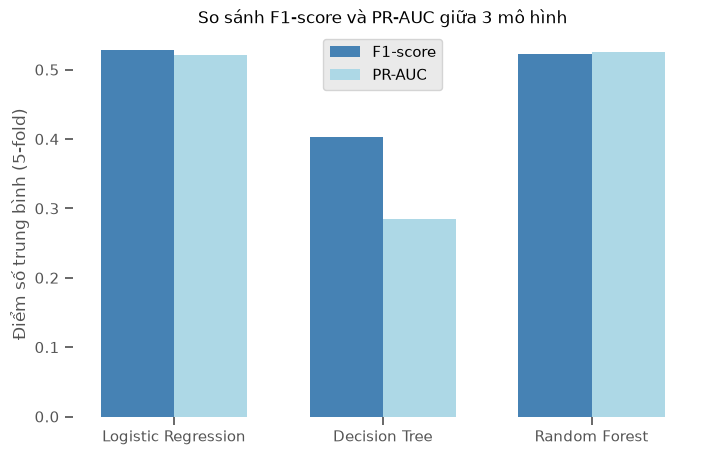

In [37]:
f1_means = [cv_results[name]['test_f1'].mean() for name in cv_results]
prauc_means = [cv_results[name]['test_average_precision'].mean() for name in cv_results]

x = np.arange(len(cv_results))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width/2, f1_means, width, label='F1-score', color='steelblue')
ax.bar(x + width/2, prauc_means, width, label='PR-AUC', color='lightblue')
ax.set_xticks(x)
ax.set_xticklabels(list(cv_results.keys()))
ax.set_ylabel('Điểm số trung bình (5-fold)')
ax.set_title('So sánh F1-score và PR-AUC giữa 3 mô hình')
ax.legend()
plt.box(False)
save_fig('f1_prauc_comparison')


<a id='ttest'></a>
### Kiểm định thống kê: Paired t-test

Chọn 2 mô hình có F1-score (5-fold) trung bình cao nhất, sau đó dùng `scipy.stats.ttest_rel` (paired t-test) trên kết quả F1 của từng fold (5-fold CV trên tập train) để kiểm định xem chênh lệch có ý nghĩa thống kê hay không, với mức ý nghĩa α = 0.05.


In [38]:
f1_by_model = {name: cv_results[name]['test_f1'] for name in cv_results}
ranked = sorted(f1_by_model.items(), key=lambda kv: kv[1].mean(), reverse=True)
model_a, model_b = ranked[0][0], ranked[1][0]
scores_a, scores_b = ranked[0][1], ranked[1][1]

t_stat, p_value = ttest_rel(scores_a, scores_b)
print(f"So sánh {model_a} (F1={scores_a.mean():.4f}) vs. {model_b} (F1={scores_b.mean():.4f})")
print(f"t-statistic = {t_stat:.4f}, p-value = {p_value:.4f}")

alpha = 0.05
if p_value < alpha:
    print(f"=> p-value < {alpha}: chênh lệch F1-score giữa {model_a} và {model_b} có ý nghĩa thống kê.")
else:
    print(f"=> p-value >= {alpha}: chưa đủ cơ sở kết luận chênh lệch F1-score giữa {model_a} và "
          f"{model_b} có ý nghĩa thống kê.")


So sánh Logistic Regression (F1=0.5285) vs. Random Forest (F1=0.5223)
t-statistic = 1.1915, p-value = 0.2993
=> p-value >= 0.05: chưa đủ cơ sở kết luận chênh lệch F1-score giữa Logistic Regression và Random Forest có ý nghĩa thống kê.


Hai mô hình có F1 trung bình cao nhất là Logistic Regression (0,5285) và Random Forest (0,5223); paired t-test trên 5 fold cho t = 1,19, **p = 0,30 > 0,05** → chưa đủ cơ sở kết luận chênh lệch F1 giữa hai mô hình có ý nghĩa thống kê. Lưu ý: với 5 fold, kiểm định có độ mạnh thấp, và các fold dùng chung dữ liệu train nên giả định độc lập của t-test chỉ gần đúng.

<a id='fi'></a>
## Feature Importance

So sánh mức độ quan trọng của các đặc trưng theo Random Forest (`feature_importances_`) và theo hệ số hồi quy (coefficients) của Logistic Regression, đặc biệt chú ý các đặc trưng mới tạo ở bước Feature Engineering (AVG_BILL_AMT, AVG_PAY_AMT, PAY_RATIO, NUM_MONTHS_DELAYED, MAX_DELAY, CREDIT_UTIL và các cờ PAY_x_nouse/PAY_x_revolving). Lưu ý: hệ số của Logistic Regression tính trên dữ liệu đã chuẩn hoá nên so sánh được độ lớn giữa các đặc trưng số; AVG_BILL_AMT, AVG_PAY_AMT không có trong mô hình LR.


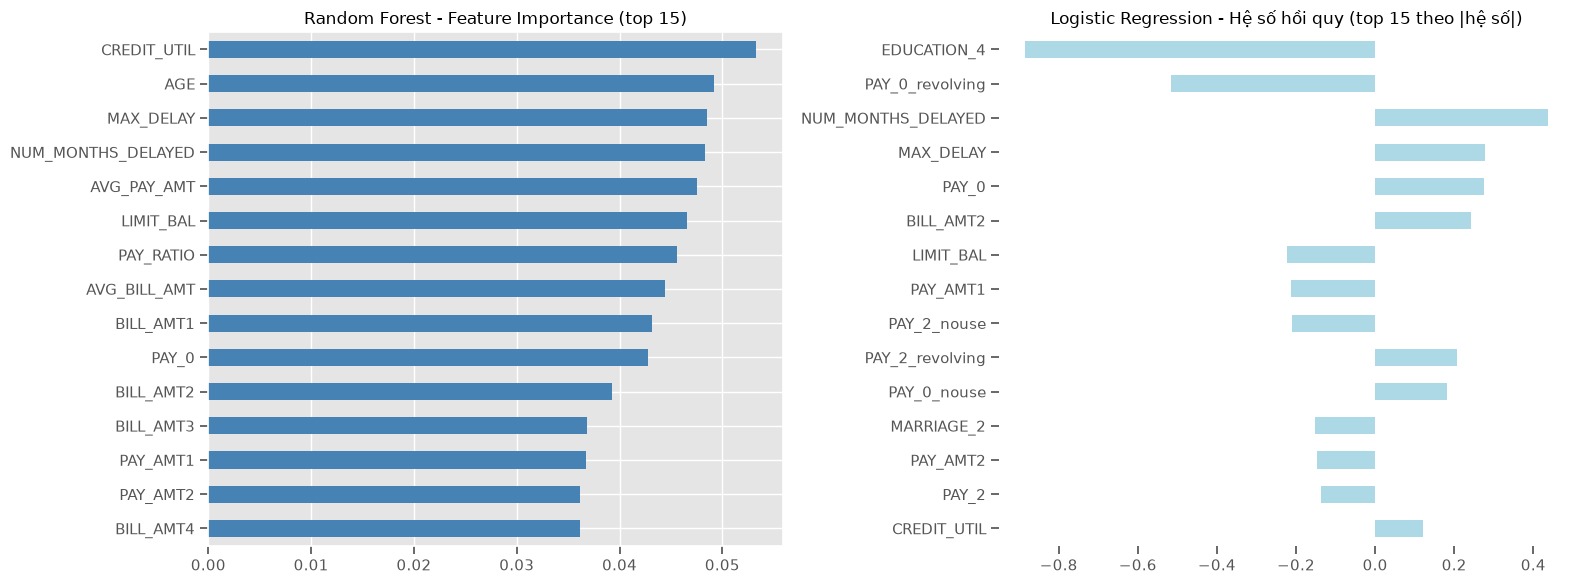

In [39]:
rf_importance = pd.Series(Ran.named_steps['clf'].feature_importances_,
                          index=X_train.columns).sort_values(ascending=False)
lr_coef = pd.Series(LR.named_steps['clf'].coef_[0],
                    index=LR.named_steps['prep'].get_feature_names_out()).sort_values(key=abs, ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
rf_importance.head(15).plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].invert_yaxis()
axes[0].set_title('Random Forest - Feature Importance (top 15)')

lr_coef.head(15).plot(kind='barh', ax=axes[1], color='lightblue')
axes[1].invert_yaxis()
axes[1].set_title('Logistic Regression - Hệ số hồi quy (top 15 theo |hệ số|)')

plt.tight_layout()
plt.box(False)
save_fig('feature_importance')

In [40]:
top_n = 10
rf_top = set(rf_importance.head(top_n).index)
lr_top = set(lr_coef.head(top_n).index)
common = rf_top & lr_top
new_features_set = set(new_features) | set(flag_cols)

print(f"Đặc trưng chung trong top {top_n} của cả 2 mô hình: {sorted(common)}")
print(f"Đặc trưng mới (Feature Engineering) xuất hiện trong top {top_n} của Random Forest: "
      f"{sorted(rf_top & new_features_set)}")
print(f"Đặc trưng mới (Feature Engineering) xuất hiện trong top {top_n} của Logistic Regression: "
      f"{sorted(lr_top & new_features_set)}")


Đặc trưng chung trong top 10 của cả 2 mô hình: ['LIMIT_BAL', 'MAX_DELAY', 'NUM_MONTHS_DELAYED', 'PAY_0']
Đặc trưng mới (Feature Engineering) xuất hiện trong top 10 của Random Forest: ['AVG_BILL_AMT', 'AVG_PAY_AMT', 'CREDIT_UTIL', 'MAX_DELAY', 'NUM_MONTHS_DELAYED', 'PAY_RATIO']
Đặc trưng mới (Feature Engineering) xuất hiện trong top 10 của Logistic Regression: ['MAX_DELAY', 'NUM_MONTHS_DELAYED', 'PAY_0_revolving', 'PAY_2_nouse', 'PAY_2_revolving']


Mức độ đồng thuận giữa hai mô hình: **LIMIT_BAL, PAY_0, MAX_DELAY và NUM_MONTHS_DELAYED** cùng nằm trong top 10 của cả Random Forest và Logistic Regression — hai trong số đó là đặc trưng mới tạo ở bước Feature Engineering. Top 10 của Random Forest chứa cả 6 đặc trưng tổng hợp (AVG_BILL_AMT, AVG_PAY_AMT, CREDIT_UTIL, MAX_DELAY, NUM_MONTHS_DELAYED, PAY_RATIO); top 10 của Logistic Regression chứa các cờ trạng thái PAY_0_revolving, PAY_2_nouse, PAY_2_revolving — minh chứng việc bổ sung cờ nhị phân có ích cho mô hình tuyến tính.

<a id='conclusion'></a>
## Kết luận

**Tổng kết (baseline, chưa tinh chỉnh siêu tham số):** Bảng so sánh ở mục [Đánh giá chéo](#cv) là căn cứ để lựa chọn mô hình. Trong bài toán dự đoán vỡ nợ thẻ tín dụng, **Recall và PR-AUC** nên được ưu tiên hơn Accuracy hoặc ROC-AUC đơn thuần, vì:

- Chi phí bỏ sót một khách hàng thực sự vỡ nợ (false negative) — không trích lập dự phòng, không có biện pháp xử lý kịp thời — thường lớn hơn nhiều so với chi phí cảnh báo nhầm một khách hàng tốt (false positive).
- Dữ liệu mất cân bằng (22,1% default) khiến Accuracy dễ gây hiểu lầm — một mô hình luôn dự đoán "không vỡ nợ" vẫn đạt Accuracy khoảng 77,9% nhưng vô dụng trong thực tế.
- PR-AUC phản ánh sát hơn ROC-AUC hiệu năng trên lớp thiểu số (default), vốn là lớp mà ngân hàng quan tâm nhất.

Ở bước baseline, **Logistic Regression (`class_weight='balanced'`)** có Recall cao nhất (0,61 CV; 0,59 test) với PR-AUC tương đương Random Forest (0,52–0,53), nên là mô hình đề xuất tạm thời. Random Forest (`balanced`) cho Precision và Accuracy cao hơn; chênh lệch F1 giữa hai mô hình không có ý nghĩa thống kê (p = 0,30). Decision Tree mặc định bị overfit và kém nhất trên mọi chỉ số.

**Hạn chế:**
- Chưa tinh chỉnh siêu tham số: Decision Tree không giới hạn độ sâu, Random Forest và Logistic Regression dùng tham số mặc định.
- Recall ở lớp default vẫn còn thấp so với kỳ vọng thực tế (≤ 0,61), một phần do các đặc trưng hiện có (chủ yếu là lịch sử 6 tháng gần nhất) chưa phản ánh đầy đủ hành vi tín dụng dài hạn của khách hàng.
- Còn đa cộng tuyến đáng kể trong tập đặc trưng của Logistic Regression (BILL_AMT1–6, NUM_MONTHS_DELAYED có VIF > 10).
- SMOTE thông thường sinh giá trị không nguyên cho các cờ nhị phân và mã one-hot; SMOTENC là lựa chọn phù hợp hơn cho dữ liệu hỗn hợp. Ở bước này SMOTE không cải thiện so với `class_weight='balanced'` (trừ Decision Tree).
- Ba mô hình sử dụng đều là các mô hình cơ bản; các kỹ thuật ensemble nâng cao hơn (Gradient Boosting, stacking) có thể cải thiện hiệu năng nhưng nằm ngoài phạm vi của đồ án này.

**Hướng phát triển tiếp theo:**
- Tinh chỉnh siêu tham số bằng `RandomizedSearchCV`/`GridSearchCV` với Pipeline, chấm điểm theo Recall/PR-AUC, chỉ trên tập train.
- Xử lý đa cộng tuyến của BILL_AMT (gộp, lấy xu hướng, hoặc bỏ bớt) cho Logistic Regression.
- Bổ sung thêm đặc trưng theo thời gian (xu hướng tăng/giảm số tiền sao kê qua các tháng, thay vì chỉ lấy trung bình).
- Điều chỉnh ngưỡng phân loại (classification threshold) thay vì mặc định 0,5, dựa trên đường cong Precision-Recall (chọn ngưỡng bằng CV trên train), để tối ưu Recall theo yêu cầu nghiệp vụ cụ thể của ngân hàng.


<a id='ch4'></a>
# Chương 4. Thực nghiệm: cải tiến, tinh chỉnh và đánh giá mô hình

Chương này mở rộng phần baseline ở trên nhằm trả lời ba câu hỏi nghiên cứu:

* **CH1** – Những yếu tố nào ảnh hưởng mạnh nhất đến khả năng vỡ nợ? (mục [4.6](#ch4_6))
* **CH2** – Mô hình nào dự đoán tốt nhất, và chênh lệch giữa các mô hình có ý nghĩa thống kê không? (mục [4.4](#ch4_4))
* **CH3** – Xử lý mất cân bằng lớp và ngưỡng quyết định ảnh hưởng thế nào tới khả năng phát hiện khách hàng vỡ nợ? (mục [4.3](#ch4_3))

Nội dung:

* [4.1. Cải tiến đặc trưng cho Logistic Regression](#ch4_1)
* [4.2. Tinh chỉnh siêu tham số](#ch4_2)
* [4.3. Mất cân bằng lớp và ngưỡng quyết định](#ch4_3)
* [4.4. So sánh mô hình và kiểm định thống kê](#ch4_4)
* [4.5. Đánh giá cuối trên tập test](#ch4_5)
* [4.5b. Mô hình với xác suất được hiệu chỉnh: RF cấu hình A + ngưỡng theo chi phí](#ch4_5b)
* [4.6. Diễn giải mô hình](#ch4_6) (và [4.6b](#ch4_6b) cho mô hình cuối)
* [4.7. Chọn mô hình và lưu](#ch4_7)
* [4.8. Kết quả huấn luyện (OOF) và tổng hợp Accuracy](#ch4_8)

**Nguyên tắc:** mọi lựa chọn (tập đặc trưng, siêu tham số, phương án mất cân bằng, ngưỡng, mô hình) chỉ dựa trên `X_train`/`y_train` bằng cross-validation; `X_test` chỉ được dùng ở mục 4.5 và 4.6. Mọi biến đổi có học tham số nằm trong `imblearn.Pipeline`; `random_state = 42` ở mọi nơi. Hình được lưu vào `figures/ch4_*.png`, bảng kết quả vào `results/ch4_*.csv`.

In [41]:
# ===== Chương 4: thư viện bổ sung, cấu hình chung =====
import json
import time
import joblib
import sklearn
import imblearn
from scipy.stats import loguniform, randint, t as t_dist
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import (RandomizedSearchCV, RepeatedStratifiedKFold, cross_val_predict,
                                     TunedThresholdClassifierCV, FixedThresholdClassifier)
from sklearn.metrics import make_scorer, fbeta_score, brier_score_loss, log_loss, precision_score, recall_score, f1_score, accuracy_score
from sklearn.calibration import CalibrationDisplay
from sklearn.inspection import permutation_importance

RES_DIR, MODEL_DIR = Path('results'), Path('models')
RES_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)
pd.set_option('display.float_format', '{:.4f}'.format)  # bảng Chương 4 hiển thị 4 chữ số thập phân

# Số vòng lặp của các bước tốn thời gian
N_ITER = {'lr': 50, 'dt': 50, 'rf': 30}; N_REPEATS = 10; N_BOOT = 1000; PI_REPEATS = 30; SHAP_N = 1000


def save_table(df, name, prefix='ch4'):
    """Lưu bảng kết quả thành results/<prefix>_<name>.csv và trả lại chính bảng đó để hiển thị."""
    df.to_csv(RES_DIR / f'{prefix}_{name}.csv', encoding='utf-8-sig')
    return df


def mean_std(scores):
    return f"{np.mean(scores):.4f} ± {np.std(scores):.4f}"


print(f"scikit-learn {sklearn.__version__}, imbalanced-learn {imblearn.__version__}")

scikit-learn 1.9.1, imbalanced-learn 0.14.2


<a id='ch4_1'></a>
## 4.1. Cải tiến đặc trưng cho Logistic Regression

Hai vấn đề của tập đặc trưng LR ở Chương 3: (1) PAY_RATIO lệch phải rất mạnh (trung bình 20,68, trung vị 0,09) nên sau `StandardScaler` vài giá trị cực lớn chi phối hệ số; (2) BILL_AMT1–6 có VIF 15–28. Cải tiến:

* Thêm `FunctionTransformer(np.log1p)` cho PAY_RATIO (PAY_RATIO ≥ 0) **trước** `StandardScaler`, bên trong `ColumnTransformer` của Pipeline.
* So sánh 2 tập đặc trưng cho LR: **(a)** như Chương 3; **(b)** thay BILL_AMT1–6 bằng BILL_AMT1 và đặc trưng xu hướng **BILL_TREND = (BILL_AMT1 − BILL_AMT6) / (|BILL_AMT6| + 1)**.

BILL_TREND chỉ dùng giá trị của chính dòng đó (không học tham số từ dữ liệu), nên được tính trực tiếp trên `X_train`/`X_test` mà không gây rò rỉ. Mô hình cây giữ nguyên tập đặc trưng của Chương 3 (Pipeline của cây chọn đúng các cột cũ), nên cột BILL_TREND chỉ được LR sử dụng nếu phương án (b) được chọn. Hàm `make_model_v2(kind, variant)` mở rộng `make_model` với các thay đổi trên.

In [42]:
def add_bill_trend(df):
    """Thêm BILL_TREND = (BILL_AMT1 - BILL_AMT6) / (|BILL_AMT6| + 1), tính theo từng dòng."""
    return df.assign(BILL_TREND=(df['BILL_AMT1'] - df['BILL_AMT6']) / (df['BILL_AMT6'].abs() + 1))


X_train4, X_test4 = add_bill_trend(X_train), add_bill_trend(X_test)
assert (X_train4['PAY_RATIO'] >= 0).all() and (X_test4['PAY_RATIO'] >= 0).all()  # điều kiện dùng log1p

tree_cols = list(X_train.columns)  # mô hình cây: giữ nguyên 41 đặc trưng của Chương 3
LR_FEATURES = {
    'a': lr_num_cols,                                                                  # như Chương 3
    'b': [c for c in lr_num_cols if c not in bill_cols[1:]] + ['BILL_TREND'],          # BILL_AMT1 + BILL_TREND
}
LR_SET = 'a'  # sẽ cập nhật theo kết quả CV bên dưới


def make_model_v2(kind, variant, lr_set=None):
    """Như make_model; thêm log1p(PAY_RATIO) và lựa chọn tập đặc trưng cho LR, cây chỉ dùng tree_cols."""
    class_weight = 'balanced' if variant == 'balanced' else None
    if kind == 'lr':
        num_cols = [c for c in LR_FEATURES[lr_set or LR_SET] if c != 'PAY_RATIO']
        log_scale = Pipeline([('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                              ('scale', StandardScaler())])
        steps = [('prep', ColumnTransformer([
            ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), lr_cat_cols),
            ('log_scale', log_scale, ['PAY_RATIO']),
            ('scale', StandardScaler(), num_cols),
        ], remainder='drop', verbose_feature_names_out=False))]
        clf = LogisticRegression(class_weight=class_weight, max_iter=5000, random_state=RANDOM_STATE)
    else:
        steps = [('prep', ColumnTransformer([('keep', 'passthrough', tree_cols)],
                                            remainder='drop', verbose_feature_names_out=False))]
        if variant == 'smote':  # SMOTE dùng khoảng cách kNN nên chuẩn hoá trước (không ảnh hưởng cách chia nút)
            steps.append(('scale', StandardScaler()))
        cls = DecisionTreeClassifier if kind == 'dt' else RandomForestClassifier
        clf = cls(class_weight=class_weight, random_state=RANDOM_STATE)
    if variant == 'smote':
        steps.append(('smote', SMOTE(random_state=RANDOM_STATE)))
    return Pipeline(steps + [('clf', clf)])


print(f"Số đặc trưng số của LR: (a) {len(LR_FEATURES['a'])}, (b) {len(LR_FEATURES['b'])} (+ one-hot {lr_cat_cols})")
print("\nPhân bố BILL_TREND trên tập train:")
print(X_train4['BILL_TREND'].describe().round(3).to_string())

Số đặc trưng số của LR: (a) 37, (b) 33 (+ one-hot ['EDUCATION', 'MARRIAGE'])

Phân bố BILL_TREND trên tập train:
count    23972.0000
mean      2313.8140
std      15035.7710
min      -2628.0000
25%         -0.1400
50%          0.0990
75%          1.5330
max     421504.0000


VIF của phương án (b) được tính trên `X_train` với ma trận thiết kế giống đầu vào của LR (one-hot EDUCATION/MARRIAGE bỏ nhóm đầu, PAY_RATIO đã lấy log1p); để đối chiếu, tính cả VIF của phương án (a) sau khi lấy log1p PAY_RATIO.

In [43]:
X_train_vif = X_train4.assign(PAY_RATIO=np.log1p(X_train4['PAY_RATIO']))
vif_ab = pd.concat({s: vif_table(design_matrix(X_train_vif, LR_FEATURES[s] + lr_cat_cols)) for s in 'ab'}, axis=1)
vif_ab.columns = ['VIF (a)', 'VIF (b)']
vif_ab = vif_ab.sort_values('VIF (b)', ascending=False)
for s in 'ab':
    v = vif_ab[f'VIF ({s})'].dropna()
    print(f"Phương án ({s}): {len(v)} cột, số cột VIF > 10: {(v > 10).sum()}, VIF lớn nhất: {v.max():.2f} ({v.idxmax()})")
save_table(vif_ab.round(2), 'lr_vif_a_vs_b').head(15)

Phương án (a): 42 cột, số cột VIF > 10: 7, VIF lớn nhất: 28.29 (BILL_AMT2)
Phương án (b): 38 cột, số cột VIF > 10: 1, VIF lớn nhất: 21.50 (NUM_MONTHS_DELAYED)


,VIF (a),VIF (b)
NUM_MONTHS_DELAYED,21.5600,21.5000
PAY_5_nouse,7.4000,7.3500
PAY_4_nouse,7.1200,7.0700
PAY_2_nouse,6.9100,6.8900
PAY_5,6.5200,6.4900
PAY_3_nouse,6.5200,6.4700
PAY_2_revolving,6.4400,6.4000
PAY_2,6.1300,6.0900
PAY_4,6.0400,6.0100
PAY_3,5.9700,5.9100


Chọn tập đặc trưng bằng **PR-AUC 5-fold CV trên train** (cùng `skf` như Chương 3), dùng phương án mất cân bằng đã chọn cho LR ở Chương 3 để so sánh công bằng với baseline.

In [44]:
SCORING_FS = {'ap': 'average_precision', 'roc_auc': 'roc_auc', 'f1': 'f1', 'recall': 'recall'}
lr_variant = chosen['lr']
cv_fs = {s: cross_validate(make_model_v2('lr', lr_variant, lr_set=s), X_train4, y_train,
                           cv=skf, scoring=SCORING_FS, n_jobs=-1) for s in 'ab'}

base = cv_all[('lr', lr_variant)]
fs_table = pd.DataFrame({
    'Chương 3 (không log1p)': {'PR-AUC': mean_std(base['test_average_precision']),
                               'ROC-AUC': mean_std(base['test_roc_auc']),
                               'F1': mean_std(base['test_f1']), 'Recall': mean_std(base['test_recall'])},
    **{f'({s}) log1p PAY_RATIO' + (' + BILL_TREND' if s == 'b' else ''): {
        'PR-AUC': mean_std(r['test_ap']), 'ROC-AUC': mean_std(r['test_roc_auc']),
        'F1': mean_std(r['test_f1']), 'Recall': mean_std(r['test_recall'])} for s, r in cv_fs.items()},
}).T
fs_table.index.name = f'LR ({lr_variant})'

LR_SET = max('ab', key=lambda s: cv_fs[s]['test_ap'].mean())
print(f"Tập đặc trưng được chọn cho LR: ({LR_SET}) — PR-AUC CV = {cv_fs[LR_SET]['test_ap'].mean():.4f}")
save_table(fs_table, 'lr_feature_sets')

Tập đặc trưng được chọn cho LR: (b) — PR-AUC CV = 0.5219


,PR-AUC,ROC-AUC,F1,Recall
LR (balanced),,,,
Chương 3 (không log1p),0.5216 ± 0.0157,0.7693 ± 0.0099,0.5285 ± 0.0097,0.6135 ± 0.0123
(a) log1p PAY_RATIO,0.5219 ± 0.0154,0.7689 ± 0.0099,0.5276 ± 0.0098,0.6124 ± 0.0120
(b) log1p PAY_RATIO + BILL_TREND,0.5219 ± 0.0154,0.7685 ± 0.0102,0.5277 ± 0.0099,0.6118 ± 0.0123


**Nhận xét 4.1:**

* **log1p(PAY_RATIO)** gần như không thay đổi hiệu năng: PR-AUC CV 0,5219 so với 0,5216 ở Chương 3 (cùng `class_weight='balanced'`), ROC-AUC 0,7689 so với 0,7693. Chênh lệch nhỏ hơn nhiều so với độ lệch chuẩn giữa các fold (≈ 0,015). Lý do là LR có điều chuẩn L2 và PAY_RATIO vốn không phải đặc trưng quan trọng của LR. Tuy vậy, phép biến đổi làm hệ số của PAY_RATIO ổn định hơn vì không còn bị vài giá trị cực lớn chi phối.
* **Phương án (b)** thay BILL_AMT2–6 bằng BILL_TREND. Số đặc trưng có VIF > 10 giảm từ **7 xuống 1**: chỉ còn NUM_MONTHS_DELAYED (21,5), vốn được tính trực tiếp từ PAY_x. VIF lớn nhất của nhóm sao kê giảm từ 28,29 (BILL_AMT2) xuống dưới 10.
* PR-AUC CV của (a) và (b) bằng nhau tới 4 chữ số thập phân (0,5219 ± 0,0154). Quy tắc chọn theo PR-AUC chọn **(b)** vì (b) cao hơn ở các chữ số sau. Kết quả này cho thấy BILL_AMT2–6 hầu như không mang thêm thông tin so với BILL_AMT1 và xu hướng sao kê. Phương án (b) đạt cùng hiệu năng với ít đặc trưng hơn (33 so với 37 cột số) và ít đa cộng tuyến hơn, nên hệ số LR dễ diễn giải hơn.
* Lưu ý: BILL_TREND rất lệch (trung vị 0,10 nhưng lớn nhất 421.504) khi BILL_AMT6 ≈ 0, nên sau chuẩn hoá phần lớn giá trị tập trung quanh 0. Đặc trưng này đóng góp ít cho LR. Lợi ích chính của (b) là giảm đa cộng tuyến chứ không phải tăng khả năng dự đoán.

<a id='ch4_2'></a>
## 4.2. Tinh chỉnh siêu tham số

`RandomizedSearchCV` cho từng mô hình với `cv = StratifiedKFold(5, shuffle=True, random_state=42)` (biến `skf`), chấm điểm đồng thời PR-AUC (`ap`), ROC-AUC, F1, Recall, Precision và chọn cấu hình theo **PR-AUC** (`refit='ap'`) — độ đo không phụ thuộc ngưỡng và phản ánh hiệu năng trên lớp thiểu số. `class_weight ∈ {None, 'balanced'}` nằm trong không gian tìm kiếm. Số tổ hợp thử: LR 50, DT 50, RF 30.

| Mô hình | Không gian tìm kiếm |
|---|---|
| LR | C ~ loguniform(10⁻⁴, 10²) |
| DT | max_depth ∈ {3, …, 20, None}; min_samples_leaf ~ randint(1, 200); ccp_alpha ~ loguniform(10⁻⁶, 10⁻²); criterion ∈ {gini, entropy} |
| RF | n_estimators ∈ {200, 300, 500}; max_depth ∈ {5, …, 25, None}; min_samples_leaf ~ randint(1, 50); max_features ∈ {sqrt, log2, 0,3, 0,5} |

In [45]:
SCORING = {'ap': 'average_precision', 'roc_auc': 'roc_auc', 'f1': 'f1', 'recall': 'recall', 'precision': 'precision'}
CW = {'clf__class_weight': [None, 'balanced']}
param_spaces = {
    'lr': {'clf__C': loguniform(1e-4, 1e2), **CW},
    'dt': {'clf__max_depth': list(range(3, 21)) + [None], 'clf__min_samples_leaf': randint(1, 200),
           'clf__ccp_alpha': loguniform(1e-6, 1e-2), 'clf__criterion': ['gini', 'entropy'], **CW},
    'rf': {'clf__n_estimators': [200, 300, 500], 'clf__max_depth': list(range(5, 26)) + [None],
           'clf__min_samples_leaf': randint(1, 50), 'clf__max_features': ['sqrt', 'log2', 0.3, 0.5], **CW},
}

searches = {}
for kind in model_names:
    t0 = time.perf_counter()
    searches[kind] = RandomizedSearchCV(
        make_model_v2(kind, 'none'), param_spaces[kind], n_iter=N_ITER[kind], scoring=SCORING, refit='ap',
        cv=skf, n_jobs=-1, random_state=RANDOM_STATE,
    ).fit(X_train4, y_train)
    print(f"{model_names[kind]}: {N_ITER[kind]} tổ hợp × 5 fold trong {time.perf_counter() - t0:.0f} giây, "
          f"PR-AUC CV tốt nhất = {searches[kind].best_score_:.4f}")

Logistic Regression: 50 tổ hợp × 5 fold trong 2 giây, PR-AUC CV tốt nhất = 0.5258


Decision Tree: 50 tổ hợp × 5 fold trong 6 giây, PR-AUC CV tốt nhất = 0.5391


Random Forest: 30 tổ hợp × 5 fold trong 209 giây, PR-AUC CV tốt nhất = 0.5645


In [46]:
def fmt_params(params):
    return ', '.join(f"{p.replace('clf__', '')}={round(v, 6) if isinstance(v, float) else v}"
                     for p, v in params.items())


tuning_rows = []
for kind, s in searches.items():
    res, i = s.cv_results_, s.best_index_
    base_v = max(variants, key=lambda v: cv_all[(kind, v)]['test_average_precision'].mean())
    row = {'Mô hình': model_names[kind], 'Siêu tham số tốt nhất': fmt_params(s.best_params_)}
    row.update({m: f"{res[f'mean_test_{m}'][i]:.4f} ± {res[f'std_test_{m}'][i]:.4f}" for m in SCORING})
    row['PR-AUC baseline tốt nhất (Chương 3)'] = (f"{cv_all[(kind, base_v)]['test_average_precision'].mean():.4f}"
                                                   f" ({base_v})")
    row['Chênh lệch PR-AUC'] = f"{res['mean_test_ap'][i] - cv_all[(kind, base_v)]['test_average_precision'].mean():+.4f}"
    tuning_rows.append(row)

tuning_table = pd.DataFrame(tuning_rows).set_index('Mô hình').rename(
    columns={'ap': 'PR-AUC', 'roc_auc': 'ROC-AUC', 'f1': 'F1', 'recall': 'Recall', 'precision': 'Precision'})
save_table(tuning_table, 'hyperparameter_tuning')

,Siêu tham số tốt nhất,PR-AUC,ROC-AUC,F1,Recall,Precision,PR-AUC baseline tốt nhất (Chương 3),Chênh lệch PR-AUC
Mô hình,,,,,,,,
Logistic Regression,"C=58.483337, class_weight=None",0.5258 ± 0.0155,0.7679 ± 0.0106,0.4726 ± 0.0109,0.3705 ± 0.0103,0.6526 ± 0.0162,0.5254 (none),+0.0003
Decision Tree,"ccp_alpha=8e-06, class_weight=None, criterion=...",0.5391 ± 0.0134,0.7719 ± 0.0071,0.4639 ± 0.0152,0.3582 ± 0.0180,0.6598 ± 0.0238,0.2924 (balanced),+0.2467
Random Forest,"class_weight=balanced, max_depth=6, max_featur...",0.5645 ± 0.0101,0.7858 ± 0.0077,0.5392 ± 0.0087,0.6312 ± 0.0157,0.4708 ± 0.0097,0.5367 (none),+0.0278


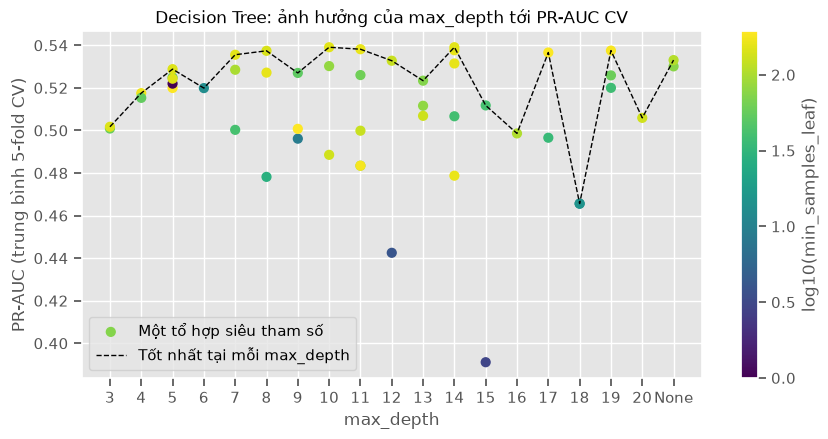

,count,mean,max
max_depth,,,
3,2,0.5013,0.5017
4,2,0.5164,0.5175
5,5,0.5240,0.5288
6,1,0.5199,0.5199
7,3,0.5215,0.5356
8,3,0.5143,0.5374
9,3,0.5080,0.5270
10,3,0.5193,0.5391
11,5,0.5062,0.5382


In [47]:
# Ảnh hưởng của max_depth tới PR-AUC CV của Decision Tree (từ cv_results_ của RandomizedSearchCV)
dt_res = pd.DataFrame(searches['dt'].cv_results_)
depth_order = list(range(3, 21)) + ['None']
dt_res['max_depth'] = dt_res['param_clf__max_depth'].apply(lambda d: 'None' if d is None else int(d))
dt_res['pos'] = dt_res['max_depth'].map({d: i for i, d in enumerate(depth_order)})
best_by_depth = dt_res.groupby('pos')['mean_test_ap'].max()

fig, ax = plt.subplots(figsize=(10, 4.5))
sc = ax.scatter(dt_res['pos'], dt_res['mean_test_ap'], c=np.log10(dt_res['param_clf__min_samples_leaf'].astype(float)),
                cmap='viridis', s=40, label='Một tổ hợp siêu tham số')
ax.plot(best_by_depth.index, best_by_depth.values, 'k--', lw=1, label='Tốt nhất tại mỗi max_depth')
ax.set_xticks(range(len(depth_order)))
ax.set_xticklabels(depth_order)
ax.set_xlabel('max_depth')
ax.set_ylabel('PR-AUC (trung bình 5-fold CV)')
ax.set_title('Decision Tree: ảnh hưởng của max_depth tới PR-AUC CV')
fig.colorbar(sc, ax=ax, label='log10(min_samples_leaf)')
ax.legend(loc='lower left')
save_fig('ch4_dt_max_depth_prauc', fig)
plt.show()
save_table(dt_res.groupby('max_depth')['mean_test_ap'].agg(['count', 'mean', 'max']).reindex(depth_order).round(4),
           'dt_max_depth_prauc')

**Nhận xét 4.2:** 

* **Decision Tree** cải thiện nhiều nhất: PR-AUC CV tăng từ 0,2924 (baseline tốt nhất, cây không giới hạn) lên **0,5391 ± 0,0134** (+0,2467), ROC-AUC từ 0,61 lên 0,7719. Cấu hình tốt nhất là `criterion='entropy'`, `max_depth=14`, **`min_samples_leaf=152`**, `ccp_alpha≈8·10⁻⁶`. Điều chuẩn qua kích thước lá tối thiểu đã loại bỏ hiện tượng overfit của cây mặc định.
* **Random Forest** tăng PR-AUC từ 0,5367 lên **0,5645 ± 0,0101** (+0,0278) với cây nông (`max_depth=6`, `min_samples_leaf=21`, `max_features=0,5`, 200 cây, `class_weight='balanced'`). Kết quả này cũng cho thấy rừng các cây nông, được điều chuẩn tốt hơn rừng các cây sâu mặc định.
* **Logistic Regression** gần như không đổi (0,5258 so với 0,5254). C tối ưu = 58,5, tức gần như không điều chuẩn, và bề mặt PR-AUC theo C rất phẳng. Hiệu năng của LR bị giới hạn bởi dạng tuyến tính chứ không bởi siêu tham số.
* Với refit theo PR-AUC, LR và DT chọn `class_weight=None`: PR-AUC không phụ thuộc ngưỡng nên trọng số lớp gần như không ảnh hưởng. Hệ quả là Recall ở ngưỡng 0,5 thấp (0,37 và 0,36). Việc xử lý mất cân bằng/ngưỡng được tách riêng ở mục 4.3.
* **Biểu đồ max_depth:** PR-AUC tốt nhất tăng nhanh từ 0,5017 (depth 3) lên 0,5288 (depth 5), đạt đỉnh ≈ 0,539 ở depth 8–14 (0,5391 tại depth 10 và 14), sau đó không tăng thêm. Ở cùng một độ sâu, PR-AUC dao động mạnh, ví dụ depth 12 từ 0,44 đến 0,53. Các điểm thấp nhất là những tổ hợp có lá rất nhỏ (màu tối): depth 15 với `min_samples_leaf=3` đạt 0,39, depth 12 với `min_samples_leaf=4` đạt 0,44, tức cây bị overfit. Một số tổ hợp có lá lớn nhưng PR-AUC thấp (≈ 0,48–0,49) là do `ccp_alpha` lớn (≈ 0,004–0,006), khiến cây bị tỉa quá mức. Với DT, `min_samples_leaf` và `ccp_alpha` quan trọng không kém `max_depth`: khi lá đủ lớn và tỉa vừa phải, cây sâu không còn bị overfit.

<a id='ch4_3'></a>
## 4.3. Mất cân bằng lớp và ngưỡng quyết định (trả lời CH3)

Giữ siêu tham số tốt nhất của mỗi mô hình ở 4.2 (bỏ `class_weight`), so sánh 4 cấu hình bằng 5-fold CV trên train (cùng `skf`):

* **A – none:** không xử lý mất cân bằng, ngưỡng 0,5.
* **B – balanced:** `class_weight='balanced'`.
* **C – SMOTE:** SMOTE bên trong Pipeline (chỉ sinh mẫu trên phần train của từng fold).
* **D – none + ngưỡng tối ưu F1:** `TunedThresholdClassifierCV(scoring='f1', cv=5)` bọc ngoài Pipeline của A; ngưỡng được chọn bằng CV **bên trong** phần train của mỗi fold ngoài, nên điểm của D là CV lồng (nested CV) không lạc quan.

Ngoài các độ đo thông thường, **F2** (β = 2, coi Recall quan trọng gấp đôi Precision) được dùng làm tiêu chí chọn cấu hình, vì bỏ sót khách hàng vỡ nợ tốn kém hơn cảnh báo nhầm.

In [48]:
best_params = {k: {p: v for p, v in s.best_params_.items() if p != 'clf__class_weight'} for k, s in searches.items()}
CONFIGS = {'A': 'none', 'B': 'balanced', 'C': 'smote', 'D': 'none'}
CONFIG_NAMES = {'A': 'A: none', 'B': 'B: balanced', 'C': 'C: SMOTE', 'D': 'D: none + ngưỡng F1'}


def base_pipe(kind, cfg):
    return make_model_v2(kind, CONFIGS[cfg]).set_params(**best_params[kind])


def config_estimator(kind, cfg):
    pipe = base_pipe(kind, cfg)
    return TunedThresholdClassifierCV(pipe, scoring='f1', cv=5) if cfg == 'D' else pipe


f2_scorer = make_scorer(fbeta_score, beta=2)
SCORING_43 = {'precision': 'precision', 'recall': 'recall', 'f1': 'f1', 'f2': f2_scorer,
              'ap': 'average_precision', 'roc_auc': 'roc_auc'}
METRIC_NAMES = {'precision': 'Precision', 'recall': 'Recall', 'f1': 'F1', 'f2': 'F2', 'ap': 'PR-AUC', 'roc_auc': 'ROC-AUC'}

cv43 = {}
t0 = time.perf_counter()
for kind in model_names:
    for cfg in CONFIGS:
        cv43[(kind, cfg)] = cross_validate(config_estimator(kind, cfg), X_train4, y_train,
                                           cv=skf, scoring=SCORING_43, n_jobs=-1)
print(f"12 tổ hợp (3 mô hình × 4 cấu hình) × 5 fold trong {time.perf_counter() - t0:.0f} giây")

cfg_table = pd.DataFrame({
    (model_names[k], CONFIG_NAMES[c]): {METRIC_NAMES[m]: r[f'test_{m}'].mean() for m in SCORING_43}
    for (k, c), r in cv43.items()
}).T.round(4)
cfg_table.index.names = ['Mô hình', 'Cấu hình']
cfg_std = pd.DataFrame({
    (model_names[k], CONFIG_NAMES[c]): {METRIC_NAMES[m] + ' std': r[f'test_{m}'].std() for m in SCORING_43}
    for (k, c), r in cv43.items()
}).T.round(4)
save_table(pd.concat([cfg_table, cfg_std], axis=1), 'imbalance_configs')

final_cfg = {k: max(CONFIGS, key=lambda c: cv43[(k, c)]['test_f2'].mean()) for k in model_names}
for k, c in final_cfg.items():
    print(f"{model_names[k]}: chọn cấu hình {CONFIG_NAMES[c]} (F2 CV = {cv43[(k, c)]['test_f2'].mean():.4f})")
cfg_table.style.format('{:.4f}').highlight_max(subset=['F2'], props='font-weight: bold')

12 tổ hợp (3 mô hình × 4 cấu hình) × 5 fold trong 84 giây
Logistic Regression: chọn cấu hình B: balanced (F2 CV = 0.5752)
Decision Tree: chọn cấu hình B: balanced (F2 CV = 0.5934)
Random Forest: chọn cấu hình B: balanced (F2 CV = 0.5908)


### Ngưỡng theo chi phí

Với cấu hình A, xác suất dự đoán out-of-fold trên train (`cross_val_predict(method='predict_proba')`, cùng `skf`) được dùng để tìm ngưỡng *t* tối thiểu hoá **chi phí kỳ vọng trên mỗi khách hàng**:

Chi phí(*t*) = (C<sub>FN</sub> · FN(*t*) + C<sub>FP</sub> · FP(*t*)) / n, với C<sub>FP</sub> = 1.

Kịch bản chính C<sub>FN</sub> : C<sub>FP</sub> = 5 : 1; phân tích độ nhạy với 3 : 1 và 10 : 1. Lý thuyết quyết định Bayes cho ngưỡng tối ưu t* = C<sub>FP</sub> / (C<sub>FP</sub> + C<sub>FN</sub>) nếu xác suất được hiệu chỉnh tốt (lần lượt 0,25; 0,167; 0,091) — dùng để đối chiếu.

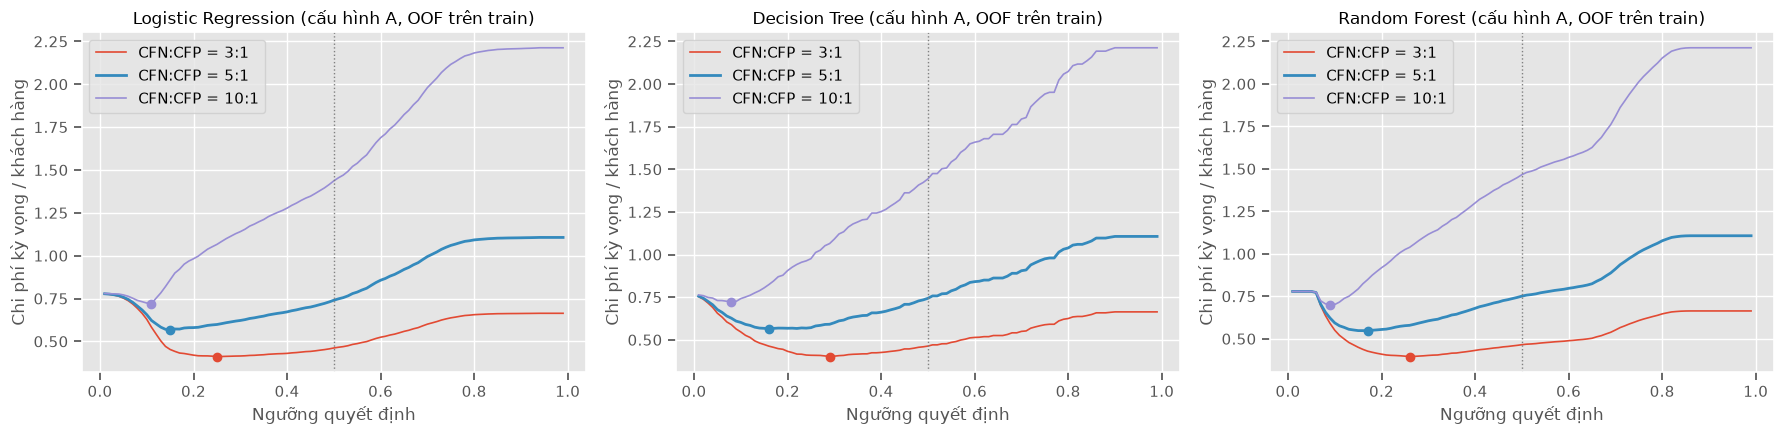

Ngưỡng tối ưu  Ngưỡng Bayes 1/(1+CFN)  Chi phí/KH tại ngưỡng tối ưu  \
Mô hình             CFN:CFP                                                                        
Logistic Regression 3:1             0.2500                  0.2500                        0.4116   
                    5:1             0.1500                  0.1670                        0.5688   
                    10:1            0.1100                  0.0910                        0.7203   
Decision Tree       3:1             0.2900                  0.2500                        0.4019   
                    5:1             0.1600                  0.1670                        0.5660   
                    10:1            0.0800                  0.0910                        0.7211   
Random Forest       3:1             0.2600                  0.2500                        0.3955   
                    5:1             0.1700                  0.1670                        0.5474   
                    10:1            0.0900                  0.0910                        0.7012   

                             Chi phí/KH tại 0,5  Recall  Precision     F2  
Mô hình             CFN:CFP                                                
Logistic Regression 3:1                  0.4615  0.5777     0.4933 0.5586  
                    5:1                  0.7401  0.7376     0.3695 0.6150  
                    10:1                 1.4366  0.9112     0.2779 0.6259  
Decision Tree       3:1                  0.4631  0.5722     0.5177 0.5604  
                    5:1                  0.7432  0.7670     0.3551 0.6226  
                    10:1                 1.4434  0.9146     0.2755 0.6247  
Random Forest       3:1                  0.4652  0.5850     0.5188 0.5705  
                    5:1                  0.7510  0.7287     0.3947 0.6232  
                    10:1                 1.4656  0.9282     0.2747 0.6289

In [49]:
oof_proba = {k: cross_val_predict(base_pipe(k, 'A'), X_train4, y_train, cv=skf,
                                  method='predict_proba', n_jobs=-1)[:, 1] for k in model_names}
thresholds = np.round(np.linspace(0.01, 0.99, 99), 2)
COST_RATIOS = [3, 5, 10]


def expected_cost(y_true, proba, c_fn, c_fp=1):
    """Chi phí kỳ vọng trên mỗi khách hàng tại từng ngưỡng trong `thresholds`."""
    y_true = np.asarray(y_true)[:, None]
    pred = proba[:, None] >= thresholds
    fn = (~pred & (y_true == 1)).sum(axis=0)
    fp = (pred & (y_true == 0)).sum(axis=0)
    return (c_fn * fn + c_fp * fp) / len(y_true)


cost_rows = []
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=False)
for ax, kind in zip(axes, model_names):
    for r in COST_RATIOS:
        cost = expected_cost(y_train, oof_proba[kind], c_fn=r)
        i = cost.argmin()
        pred = oof_proba[kind] >= thresholds[i]
        cost_rows.append({'Mô hình': model_names[kind], 'CFN:CFP': f'{r}:1', 'Ngưỡng tối ưu': thresholds[i],
                          'Ngưỡng Bayes 1/(1+CFN)': round(1 / (1 + r), 3), 'Chi phí/KH tại ngưỡng tối ưu': cost[i],
                          'Chi phí/KH tại 0,5': cost[thresholds.tolist().index(0.5)],
                          'Recall': recall_score(y_train, pred), 'Precision': precision_score(y_train, pred),
                          'F2': fbeta_score(y_train, pred, beta=2)})
        ax.plot(thresholds, cost, lw=2 if r == 5 else 1.2, label=f'CFN:CFP = {r}:1')
        ax.scatter(thresholds[i], cost[i], zorder=3)
    ax.axvline(0.5, color='gray', ls=':', lw=1)
    ax.set_title(f'{model_names[kind]} (cấu hình A, OOF trên train)')
    ax.set_xlabel('Ngưỡng quyết định')
    ax.set_ylabel('Chi phí kỳ vọng / khách hàng')
    ax.legend()
plt.tight_layout()
save_fig('ch4_cost_threshold', fig)
plt.show()

cost_table = pd.DataFrame(cost_rows).set_index(['Mô hình', 'CFN:CFP']).round(4)
save_table(cost_table, 'cost_threshold')

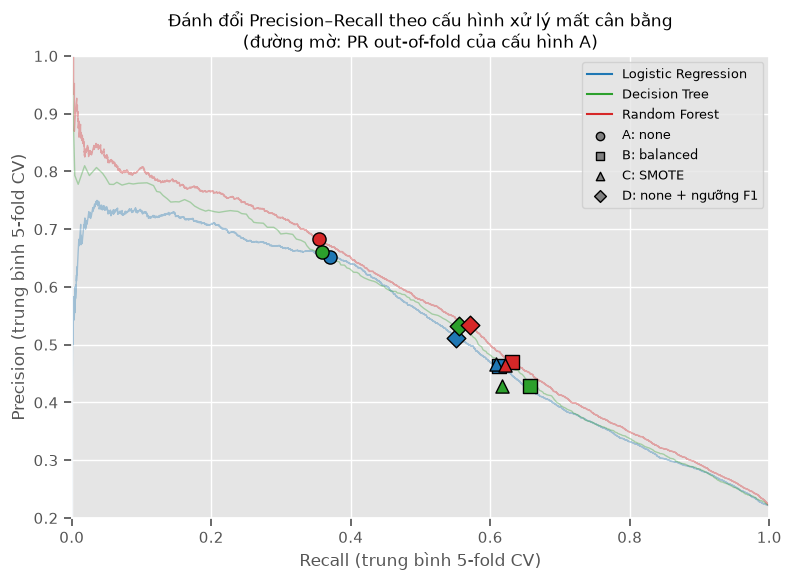

In [50]:
# Đánh đổi Precision–Recall: 4 cấu hình (điểm, trung bình CV) trên nền đường PR out-of-fold của cấu hình A
markers = {'A': 'o', 'B': 's', 'C': '^', 'D': 'D'}
colors = {'lr': 'tab:blue', 'dt': 'tab:green', 'rf': 'tab:red'}
fig, ax = plt.subplots(figsize=(9, 6))
for kind in model_names:
    prec, rec, _ = precision_recall_curve(y_train, oof_proba[kind])
    ax.plot(rec, prec, color=colors[kind], alpha=0.35, lw=1)
    for cfg in CONFIGS:
        r = cv43[(kind, cfg)]
        ax.scatter(r['test_recall'].mean(), r['test_precision'].mean(), color=colors[kind], marker=markers[cfg],
                   s=90, edgecolor='k', zorder=3)
for kind in model_names:
    ax.plot([], [], color=colors[kind], label=model_names[kind])
for cfg in CONFIGS:
    ax.scatter([], [], marker=markers[cfg], color='gray', edgecolor='k', label=CONFIG_NAMES[cfg])
ax.set_xlabel('Recall (trung bình 5-fold CV)')
ax.set_ylabel('Precision (trung bình 5-fold CV)')
ax.set_title('Đánh đổi Precision–Recall theo cấu hình xử lý mất cân bằng\n(đường mờ: PR out-of-fold của cấu hình A)')
ax.set_xlim(0, 1)
ax.set_ylim(0.2, 1)
ax.legend(loc='upper right', fontsize=9)
save_fig('ch4_pr_tradeoff_configs', fig)
plt.show()

**Nhận xét 4.3 (CH3):** 

* **Tác động của xử lý mất cân bằng:** ở ngưỡng 0,5, không xử lý (A) cho Recall chỉ 0,35–0,37 ở cả 3 mô hình. `class_weight='balanced'` (B) nâng Recall lên 0,61 (LR), **0,66 (DT)** và 0,63 (RF). Đổi lại, Precision giảm từ 0,65–0,68 xuống 0,43–0,47. F1 tăng khoảng 0,05–0,07 và F2 tăng khoảng 0,17–0,20.
* **PR-AUC và ROC-AUC gần như không đổi giữa A, B, D** (ví dụ RF: PR-AUC 0,5649 / 0,5645 / 0,5649). Xử lý mất cân bằng không làm mô hình **phân biệt** tốt hơn mà chỉ **dịch điểm làm việc** trên cùng một đường Precision–Recall. Biểu đồ đánh đổi minh hoạ rõ điều này: các điểm A, B, C, D của mỗi mô hình nằm trên hoặc sát đường PR out-of-fold của cấu hình A.
* **SMOTE (C)** không tốt hơn `balanced` ở mô hình nào. Với DT, SMOTE còn làm giảm PR-AUC (0,5044 so với 0,5369) vì các mẫu tổng hợp nội suy trên các cờ nhị phân/biến rời rạc làm nhiễu các nút chia.
* **Ngưỡng tối ưu F1 (D)** cho F1 cao nhất ở cả 3 mô hình (LR 0,5304; DT 0,5437; RF 0,5515) với Precision và Recall cân bằng (≈ 0,51–0,57). Tuy nhiên Recall (0,55–0,57) thấp hơn B.
* **Chọn cấu hình cuối theo F2:** F2 = 5·P·R/(4P + R) coi Recall quan trọng gấp đôi Precision, phù hợp với việc bỏ sót khách hàng vỡ nợ tốn kém hơn cảnh báo nhầm. **B (balanced) có F2 cao nhất ở cả 3 mô hình**: LR 0,5752, DT 0,5934, RF 0,5908 (so với D 0,5424 / 0,5508 / 0,5627 và C 0,5736 / 0,5664 / 0,5826). Vì vậy cả 3 mô hình cuối đều dùng `class_weight='balanced'` với ngưỡng 0,5.
* **Ngưỡng theo chi phí:** với C<sub>FN</sub>:C<sub>FP</sub> = 5:1, ngưỡng tối ưu trên xác suất OOF của cấu hình A là 0,15 (LR), 0,16 (DT) và 0,17 (RF). Các giá trị này rất gần ngưỡng Bayes 1/6 ≈ 0,167. Chi phí kỳ vọng/khách hàng giảm từ ≈ 0,74–0,75 (ngưỡng 0,5) xuống 0,55–0,57, tức giảm khoảng 23–27%. Tại ngưỡng này Recall đạt 0,73–0,77 nhưng Precision chỉ 0,36–0,39.
* **Độ nhạy với tỷ lệ chi phí:** ở tỷ lệ 3:1, ngưỡng tối ưu tăng lên 0,25–0,29 (Recall ≈ 0,58). Ở 10:1, ngưỡng giảm xuống 0,08–0,11 (Recall 0,91–0,93, Precision ≈ 0,28). Ngưỡng tối ưu thay đổi mạnh theo tỷ lệ chi phí, trong khi thứ hạng các mô hình gần như giữ nguyên: RF luôn có chi phí thấp nhất. Nếu ngân hàng xác định được tỷ lệ chi phí thực tế, nên đặt ngưỡng theo chi phí thay vì dùng ngưỡng 0,5 mặc định.

**Trả lời CH3:** xử lý mất cân bằng và điều chỉnh ngưỡng không cải thiện khả năng phân biệt (PR-AUC, ROC-AUC) nhưng quyết định điểm làm việc của mô hình. `class_weight='balanced'` tăng Recall từ ≈ 0,36 lên ≈ 0,61–0,66 và là cấu hình tốt nhất theo F2. SMOTE không mang lại lợi ích so với trọng số lớp. Khi có thông tin chi phí, ngưỡng theo chi phí (≈ 0,17 với tỷ lệ 5:1) giảm chi phí kỳ vọng khoảng một phần tư so với ngưỡng 0,5.

<a id='ch4_4'></a>
## 4.4. So sánh mô hình và kiểm định thống kê (trả lời CH2)

Ba mô hình cuối (siêu tham số ở 4.2, cấu hình ở 4.3) được đánh giá bằng `RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)` trên train — **cùng 50 fold cho cả 3 mô hình** nên có thể so sánh theo cặp. Cấu hình D (nếu được chọn) vẫn giữ `TunedThresholdClassifierCV` bên trong mỗi fold. Độ đo: PR-AUC, ROC-AUC, F1, Recall, Brier score (càng nhỏ càng tốt), **Gini = 2·AUC − 1** và **KS = max|TPR − FPR|** (thống kê Kolmogorov–Smirnov, scorer tự viết).

Do 50 fold dùng chung dữ liệu (các tập train chồng lấn), t-test ghép cặp thông thường đánh giá thấp phương sai và cho p-value quá nhỏ. Ta dùng **corrected resampled t-test** (Nadeau & Bengio, 2003):

t = mean(d) / √[(1/k + n<sub>test</sub>/n<sub>train</sub>) · var(d)],  với d là chênh lệch điểm trên k = 50 fold, n<sub>test</sub>/n<sub>train</sub> = 1/4, bậc tự do k − 1 = 49.

Ba cặp (LR–DT, LR–RF, DT–RF) được kiểm định trên PR-AUC và F1, hiệu chỉnh Bonferroni α = 0,05/3 ≈ 0,0167 cho mỗi độ đo.

In [51]:
def ks_stat(y_true, proba):
    """Thống kê KS = max |TPR - FPR| trên đường ROC."""
    fpr, tpr, _ = roc_curve(y_true, proba)
    return np.max(np.abs(tpr - fpr))


rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=N_REPEATS, random_state=RANDOM_STATE)
SCORING_44 = {'ap': 'average_precision', 'roc_auc': 'roc_auc', 'f1': 'f1', 'recall': 'recall',
              'brier': 'neg_brier_score', 'ks': make_scorer(ks_stat, response_method='predict_proba')}

fold_scores = {}
t0 = time.perf_counter()
for kind in model_names:
    r = cross_validate(config_estimator(kind, final_cfg[kind]), X_train4, y_train, cv=rskf,
                       scoring=SCORING_44, n_jobs=-1)
    fold_scores[kind] = pd.DataFrame({
        'PR-AUC': r['test_ap'], 'ROC-AUC': r['test_roc_auc'], 'Gini': 2 * r['test_roc_auc'] - 1,
        'KS': r['test_ks'], 'F1': r['test_f1'], 'Recall': r['test_recall'], 'Brier': -r['test_brier']})
print(f"3 mô hình × {5 * N_REPEATS} fold trong {time.perf_counter() - t0:.0f} giây")

save_table(pd.concat({model_names[k]: v for k, v in fold_scores.items()}, names=['Mô hình', 'Fold']), 'repeated_cv_folds')
rcv_table = pd.DataFrame({f"{model_names[k]} ({CONFIG_NAMES[final_cfg[k]]})": v.apply(mean_std)
                          for k, v in fold_scores.items()}).T
rcv_table.index.name = f'Mô hình (mean ± std trên {5 * N_REPEATS} fold)'
save_table(rcv_table, 'repeated_cv_summary')

3 mô hình × 50 fold trong 57 giây


,PR-AUC,ROC-AUC,Gini,KS,F1,Recall,Brier
Mô hình (mean ± std trên 50 fold),,,,,,,
Logistic Regression (B: balanced),0.5236 ± 0.0150,0.7693 ± 0.0085,0.5386 ± 0.0169,0.4186 ± 0.0154,0.5284 ± 0.0110,0.6132 ± 0.0153,0.1870 ± 0.0024
Decision Tree (B: balanced),0.5350 ± 0.0139,0.7691 ± 0.0079,0.5381 ± 0.0159,0.4204 ± 0.0125,0.5164 ± 0.0087,0.6623 ± 0.0178,0.1871 ± 0.0026
Random Forest (B: balanced),0.5636 ± 0.0146,0.7859 ± 0.0073,0.5718 ± 0.0147,0.4390 ± 0.0129,0.5404 ± 0.0088,0.6309 ± 0.0137,0.1783 ± 0.0023


In [52]:
def corrected_ttest(a, b, test_train_ratio=1 / 4):
    """Corrected resampled t-test (Nadeau & Bengio, 2003) cho điểm của 2 mô hình trên cùng các fold."""
    d = np.asarray(a) - np.asarray(b)
    k = len(d)
    t_stat = d.mean() / np.sqrt((1 / k + test_train_ratio) * d.var(ddof=1))
    return t_stat, 2 * t_dist.sf(abs(t_stat), df=k - 1)


ALPHA_BONF = 0.05 / 3
sig_rows = []
for m in ['PR-AUC', 'F1']:
    for a, b in [('lr', 'dt'), ('lr', 'rf'), ('dt', 'rf')]:
        sa, sb = fold_scores[a][m], fold_scores[b][m]
        t_c, p_c = corrected_ttest(sa, sb)
        t_n, p_n = ttest_rel(sa, sb)
        assert abs(t_c) <= abs(t_n) + 1e-9  # hiệu chỉnh chỉ làm phương sai lớn hơn
        sig_rows.append({'Độ đo': m, 'Cặp': f'{model_names[a]} – {model_names[b]}',
                          'Chênh lệch TB': sa.mean() - sb.mean(),
                          't (corrected)': t_c, 'p (corrected)': p_c,
                          f'Có ý nghĩa (p < {ALPHA_BONF:.4f})': 'Có' if p_c < ALPHA_BONF else 'Không',
                          't (ttest_rel)': t_n, 'p (ttest_rel)': p_n})
test_table = pd.DataFrame(sig_rows).set_index(['Độ đo', 'Cặp'])
save_table(test_table, 'significance_tests')
test_table.style.format({c: '{:.4g}' for c in test_table.columns if not c.startswith('Có')})

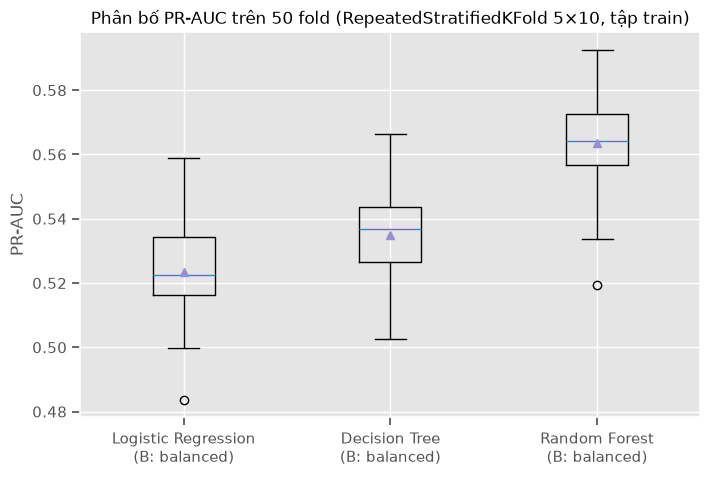

In [53]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([fold_scores[k]['PR-AUC'] for k in model_names], showmeans=True)
ax.set_xticks([1, 2, 3], [f"{model_names[k]}\n({CONFIG_NAMES[final_cfg[k]]})" for k in model_names])
ax.set_ylabel('PR-AUC')
ax.set_title(f'Phân bố PR-AUC trên {5 * N_REPEATS} fold (RepeatedStratifiedKFold 5×{N_REPEATS}, tập train)')
save_fig('ch4_prauc_boxplot', fig)
plt.show()

**Nhận xét 4.4 (CH2):** 

* **Hiệu năng trên 50 fold:** Random Forest dẫn đầu ở mọi độ đo xếp hạng: PR-AUC **0,5636 ± 0,0146**, ROC-AUC 0,7859 (Gini 0,5718), KS 0,4390, Brier thấp nhất 0,1783. RF cũng có F1 cao nhất (0,5404). Decision Tree có PR-AUC 0,5350 và Recall cao nhất (0,6623) nhưng F1 thấp nhất (0,5164). Logistic Regression có PR-AUC 0,5236, ROC-AUC 0,7693 (xấp xỉ DT 0,7691).
* **Kiểm định PR-AUC** (corrected t-test, α Bonferroni = 0,0167): RF tốt hơn LR (chênh lệch 0,0400; t = −8,38; p ≈ 5·10⁻¹¹) và tốt hơn DT (0,0286; t = −6,43; p ≈ 5·10⁻⁸), cả hai đều **có ý nghĩa**. Chênh lệch LR–DT (−0,0114; p = 0,12) **không có ý nghĩa**.
* **Kiểm định F1:** RF tốt hơn LR (0,0120; p = 0,0012) và DT (0,0240; p ≈ 10⁻⁶), đều có ý nghĩa. LR tốt hơn DT 0,0120 với p = 0,01664, chỉ vừa dưới ngưỡng 0,01667 nên đây là kết luận **sát ranh giới**, cần thận trọng.
* **So với t-test thường:** `ttest_rel` cho |t| lớn gấp √13,5 ≈ 3,67 lần (do hệ số hiệu chỉnh (1/50 + 1/4)/(1/50) = 13,5 trên phương sai) và p-value nhỏ hơn nhiều bậc (ví dụ LR–DT trên PR-AUC: p ≈ 5·10⁻⁷ so với 0,12). Nếu dùng t-test thường sẽ kết luận sai rằng LR và DT khác nhau rõ rệt. Nguyên nhân là 50 fold dùng chung dữ liệu nên các điểm không độc lập; hiệu chỉnh Nadeau–Bengio cần thiết để tránh sai lầm loại I.
* Boxplot cho thấy phân bố PR-AUC của RF nằm cao hơn hẳn hai mô hình còn lại. Phân bố của LR và DT chồng lấn nhiều.

**Trả lời CH2:** Random Forest (đã tinh chỉnh, `class_weight='balanced'`) là mô hình tốt nhất. Ưu thế về PR-AUC (+0,03 đến +0,04) và F1 (+0,01 đến +0,02) so với LR và DT có ý nghĩa thống kê sau khi hiệu chỉnh cho các fold phụ thuộc và cho so sánh bội. Logistic Regression và Decision Tree đã tinh chỉnh không khác nhau có ý nghĩa về PR-AUC.

<a id='ch4_5'></a>
## 4.5. Đánh giá cuối trên tập test

Đây là lần **duy nhất** tập test được dùng để đánh giá. Mỗi mô hình cuối được fit trên toàn bộ `X_train` và bọc trong `FixedThresholdClassifier` với ngưỡng đã chọn ở 4.3 (0,5 cho cấu hình A/B/C; với cấu hình D, ngưỡng do `TunedThresholdClassifierCV` chọn bằng 5-fold CV trên toàn bộ train), nên đối tượng mô hình chứa luôn ngưỡng quyết định.

In [54]:
final_thresholds, final_models = {}, {}
for kind in model_names:
    cfg = final_cfg[kind]
    if cfg == 'D':
        final_thresholds[kind] = float(config_estimator(kind, 'D').fit(X_train4, y_train).best_threshold_)
    else:
        final_thresholds[kind] = 0.5
    final_models[kind] = FixedThresholdClassifier(base_pipe(kind, cfg), threshold=final_thresholds[kind]
                                                  ).fit(X_train4, y_train)
    print(f"{model_names[kind]}: cấu hình {CONFIG_NAMES[cfg]}, ngưỡng = {final_thresholds[kind]:.4f}")

# ----- Chỉ từ đây trở đi mới dùng X_test -----
test_proba = {k: m.predict_proba(X_test4)[:, 1] for k, m in final_models.items()}
test_pred = {k: m.predict(X_test4) for k, m in final_models.items()}

eval_rows = []
for kind in model_names:
    p, yp = test_proba[kind], test_pred[kind]
    auc = roc_auc_score(y_test, p)
    eval_rows.append({'Mô hình': model_names[kind], 'Cấu hình': CONFIG_NAMES[final_cfg[kind]],
                      'Ngưỡng': final_thresholds[kind], 'Accuracy': accuracy_score(y_test, yp),
                      'Precision': precision_score(y_test, yp), 'Recall': recall_score(y_test, yp),
                      'F1': f1_score(y_test, yp), 'F2': fbeta_score(y_test, yp, beta=2),
                      'ROC-AUC': auc, 'PR-AUC': average_precision_score(y_test, p), 'Gini': 2 * auc - 1,
                      'KS': ks_stat(y_test, p), 'Brier': brier_score_loss(y_test, p)})
    print(f"===== {model_names[kind]} =====")
    print(classification_report(y_test, yp, digits=4))
final_test_table = pd.DataFrame(eval_rows).set_index('Mô hình')
save_table(final_test_table.round(4), 'test_metrics')

Logistic Regression: cấu hình B: balanced, ngưỡng = 0.5000


Decision Tree: cấu hình B: balanced, ngưỡng = 0.5000


Random Forest: cấu hình B: balanced, ngưỡng = 0.5000
===== Logistic Regression =====
              precision    recall  f1-score   support

           0     0.8736    0.8039    0.8373      4667
           1     0.4611    0.5905    0.5179      1326

    accuracy                         0.7567      5993
   macro avg     0.6674    0.6972    0.6776      5993
weighted avg     0.7823    0.7567    0.7666      5993

===== Decision Tree =====
              precision    recall  f1-score   support

           0     0.8749    0.7570    0.8117      4667
           1     0.4199    0.6192    0.5005      1326

    accuracy                         0.7265      5993
   macro avg     0.6474    0.6881    0.6561      5993
weighted avg     0.7743    0.7265    0.7428      5993

===== Random Forest =====
              precision    recall  f1-score   support

           0     0.8802    0.8016    0.8391      4667
           1     0.4687    0.6161    0.5324      1326

    accuracy                         0.7606  

,Cấu hình,Ngưỡng,Accuracy,Precision,Recall,F1,F2,ROC-AUC,PR-AUC,Gini,KS,Brier
Mô hình,,,,,,,,,,,,
Logistic Regression,B: balanced,0.5000,0.7567,0.4611,0.5905,0.5179,0.5591,0.7624,0.5275,0.5247,0.4030,0.1876
Decision Tree,B: balanced,0.5000,0.7265,0.4199,0.6192,0.5005,0.5655,0.7535,0.5272,0.5069,0.3865,0.1916
Random Forest,B: balanced,0.5000,0.7606,0.4687,0.6161,0.5324,0.5797,0.7736,0.5559,0.5471,0.4251,0.1815


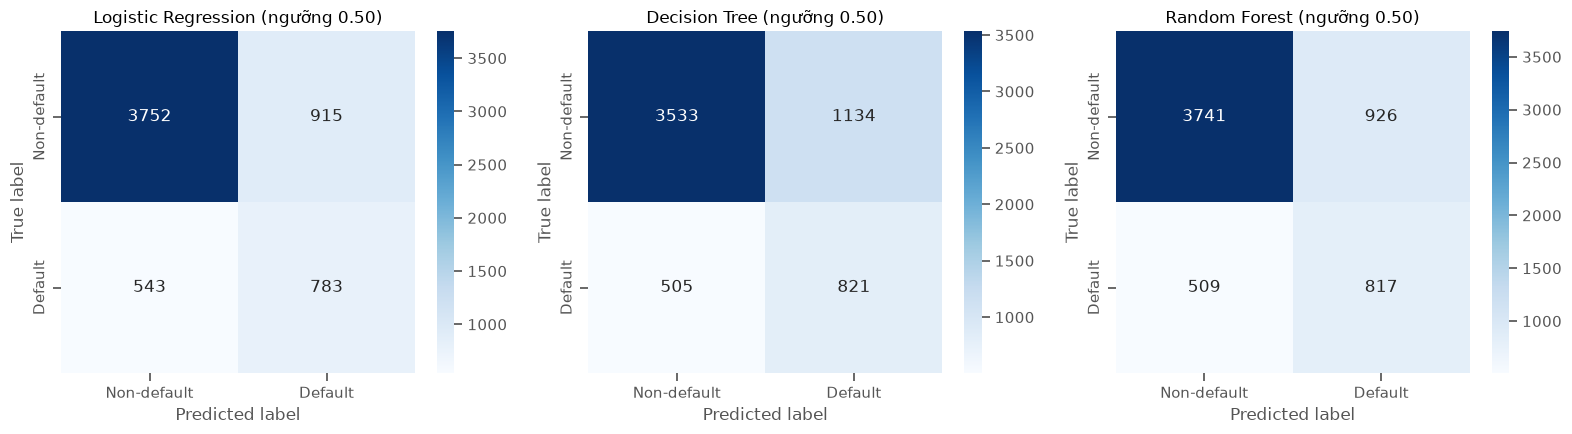

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, kind in zip(axes, model_names):
    sns.heatmap(confusion_matrix(y_test, test_pred[kind]), annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Non-default', 'Default'], yticklabels=['Non-default', 'Default'])
    ax.set_title(f"{model_names[kind]} (ngưỡng {final_thresholds[kind]:.2f})")
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
plt.tight_layout()
save_fig('ch4_confusion_matrices_test', fig)
plt.show()

**Khoảng tin cậy bootstrap:** lấy mẫu có hoàn lại 1.000 lần tập test (cùng các chỉ số mẫu cho cả 3 mô hình), tính ROC-AUC và PR-AUC trên mỗi mẫu; khoảng tin cậy 95% là phân vị 2,5% – 97,5%.

In [56]:
rng = np.random.default_rng(RANDOM_STATE)
y_test_arr = y_test.to_numpy()
boot_idx = rng.integers(0, len(y_test_arr), size=(N_BOOT, len(y_test_arr)))
boot = {k: np.array([[roc_auc_score(y_test_arr[i], test_proba[k][i]),
                      average_precision_score(y_test_arr[i], test_proba[k][i])] for i in boot_idx])
        for k in model_names}

ci_rows = []
for kind in model_names:
    for j, m in enumerate(['ROC-AUC', 'PR-AUC']):
        lo, hi = np.percentile(boot[kind][:, j], [2.5, 97.5])
        ci_rows.append({'Mô hình': model_names[kind], 'Độ đo': m, 'Giá trị (test)': final_test_table.loc[model_names[kind], m],
                        'CI 95% dưới': lo, 'CI 95% trên': hi})
ci_table = pd.DataFrame(ci_rows).set_index(['Mô hình', 'Độ đo']).round(4)
save_table(ci_table, 'test_bootstrap_ci')

Giá trị (test)  CI 95% dưới  CI 95% trên
Mô hình             Độ đo                                            
Logistic Regression ROC-AUC          0.7624       0.7472       0.7779
                    PR-AUC           0.5275       0.4999       0.5580
Decision Tree       ROC-AUC          0.7535       0.7387       0.7688
                    PR-AUC           0.5272       0.4997       0.5551
Random Forest       ROC-AUC          0.7736       0.7593       0.7884
                    PR-AUC           0.5559       0.5279       0.5822

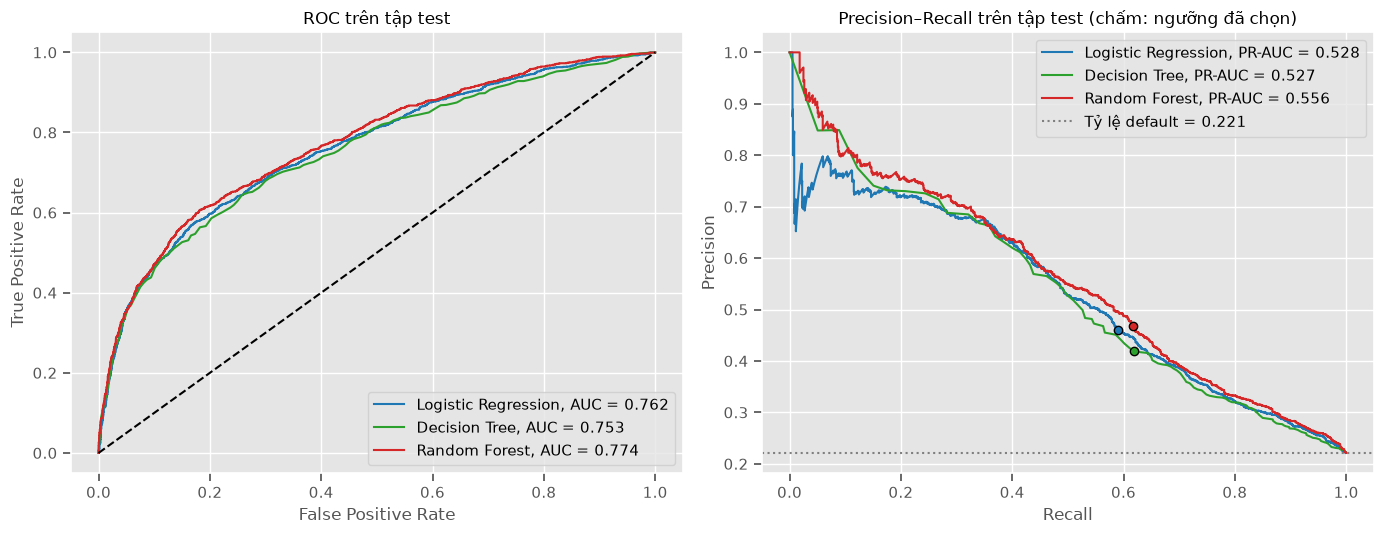

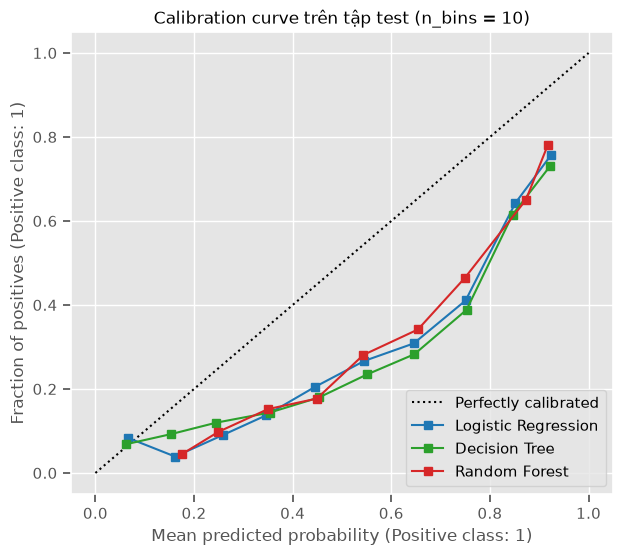

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for kind in model_names:
    p = test_proba[kind]
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=colors[kind], label=f"{model_names[kind]}, AUC = {roc_auc_score(y_test, p):.3f}")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, color=colors[kind], label=f"{model_names[kind]}, PR-AUC = {average_precision_score(y_test, p):.3f}")
    yp = test_pred[kind]
    axes[1].scatter(recall_score(y_test, yp), precision_score(y_test, yp), color=colors[kind], edgecolor='k', zorder=3)
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set(title='ROC trên tập test', xlabel='False Positive Rate', ylabel='True Positive Rate')
axes[0].legend(loc='lower right')
axes[1].axhline(y_test.mean(), color='gray', ls=':', label=f'Tỷ lệ default = {y_test.mean():.3f}')
axes[1].set(title='Precision–Recall trên tập test (chấm: ngưỡng đã chọn)', xlabel='Recall', ylabel='Precision')
axes[1].legend(loc='upper right')
plt.tight_layout()
save_fig('ch4_roc_pr_test', fig)
plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
for kind in model_names:
    CalibrationDisplay.from_predictions(y_test, test_proba[kind], n_bins=10, name=model_names[kind],
                                       color=colors[kind], ax=ax)
ax.set_title('Calibration curve trên tập test (n_bins = 10)')
save_fig('ch4_calibration_test', fig)
plt.show()

In [58]:
# Bảng so sánh baseline (Chương 3, trên cùng tập test) và sau tinh chỉnh
cmp_cols = ['Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']
baseline_test = pd.DataFrame({model_names[k]: test_metrics[model_names[k]] for k in model_names}).T
baseline_test.columns = ['Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']
compare_table = pd.concat({'Baseline (Chương 3)': baseline_test[cmp_cols],
                           'Sau tinh chỉnh (Chương 4)': final_test_table[cmp_cols],
                           'Chênh lệch': final_test_table[cmp_cols] - baseline_test[cmp_cols]}, axis=1).round(4)
compare_table.insert(0, ('', 'Phương án baseline'), [chosen[k] for k in model_names])
save_table(compare_table, 'baseline_vs_tuned_test')

Baseline (Chương 3)                               \
                    Phương án baseline           Precision Recall     F1 ROC-AUC PR-AUC   
Logistic Regression           balanced              0.4609 0.5905 0.5177  0.7616 0.5275   
Decision Tree                    smote              0.3665 0.4804 0.4158  0.6221 0.2910   
Random Forest                 balanced              0.5441 0.4789 0.5094  0.7607 0.5279   

                    Sau tinh chỉnh (Chương 4)                              Chênh lệch         \
                                    Precision Recall     F1 ROC-AUC PR-AUC  Precision Recall   
Logistic Regression                    0.4611 0.5905 0.5179  0.7624 0.5275     0.0003 0.0000   
Decision Tree                          0.4199 0.6192 0.5005  0.7535 0.5272     0.0534 0.1388   
Random Forest                          0.4687 0.6161 0.5324  0.7736 0.5559    -0.0754 0.1373   

                                           
                        F1 ROC-AUC PR-AUC  
Logistic Regression 0.0002  0.0008 0.0000  
Decision Tree       0.0847  0.1313 0.2362  
Random Forest       0.0230  0.0129 0.0280

**Nhận xét 4.5:** 

* **Kết quả test khớp với CV** (chênh lệch ≤ 0,016 ở PR-AUC và ROC-AUC, ví dụ RF: PR-AUC 0,5559 test so với 0,5636 CV). Không có dấu hiệu lựa chọn quá khớp. Thứ hạng giữ nguyên: **RF** có ROC-AUC 0,7736 [CI 95%: 0,7593–0,7884], PR-AUC 0,5559 [0,5279–0,5822], Gini 0,5471, KS 0,4251, Brier 0,1815. LR có PR-AUC 0,5275 [0,4999–0,5580], DT 0,5272 [0,4997–0,5551].
* Khoảng tin cậy bootstrap của PR-AUC giữa RF và LR/DT **chồng lấn một phần**. Với một tập test 5.993 dòng, chênh lệch ≈ 0,03 chưa đủ để tách bạch hai khoảng. Kết luận về ý nghĩa thống kê dựa trên kiểm định ghép cặp 50 fold ở mục 4.4, không dựa trên việc so khoảng tin cậy độc lập.
* **Ở ngưỡng đã chọn:** RF phát hiện 61,6% khách hàng vỡ nợ (Recall 0,6161) với Precision 0,4687, F1 0,5324, F2 0,5797 (cao nhất). DT có Recall cao nhất (0,6192) nhưng Precision thấp nhất (0,4199). LR có Recall 0,5905 và Precision 0,4611.
* **So với baseline Chương 3 (cùng tập test):** DT cải thiện mạnh (PR-AUC +0,2362, ROC-AUC +0,1313, Recall +0,1388). RF tăng Recall +0,1373 (0,48 → 0,62), PR-AUC +0,0280 và F1 +0,0230, đổi lại Precision giảm 0,0754 vì chuyển sang ưu tiên Recall. LR gần như không đổi (chênh lệch ≤ 0,001), phù hợp với kết quả CV ở 4.1–4.2.
* **Calibration:** cả 3 đường cong nằm **dưới đường chéo** ở vùng xác suất trung bình và cao (ví dụ dự đoán ≈ 0,75 nhưng tỷ lệ vỡ nợ thực tế chỉ ≈ 0,4). Đây là hệ quả của `class_weight='balanced'`, vốn phóng đại xác suất của lớp thiểu số. Mô hình phù hợp để **xếp hạng/phân loại**. Nếu cần xác suất vỡ nợ (PD) đúng nghĩa, ví dụ cho trích lập dự phòng, cần hiệu chỉnh thêm (`CalibratedClassifierCV`, isotonic/sigmoid) trên dữ liệu train.

<a id='ch4_5b'></a>
## 4.5b. Mô hình với xác suất được hiệu chỉnh: Random Forest cấu hình A + ngưỡng theo chi phí

Calibration curve ở mục 4.5 cho thấy `class_weight='balanced'` **phóng đại xác suất vỡ nợ**: nhóm được dự đoán ≈ 0,75 thực tế chỉ có ≈ 0,4 vỡ nợ, và mức nền SHAP bằng 0,5 thay vì tỷ lệ vỡ nợ thực tế ≈ 0,221. Ứng dụng ở Chương 5 cần hiển thị **xác suất vỡ nợ có ý nghĩa**, nên ta xét một mô hình ứng viên khác đạt mục tiêu ưu tiên Recall bằng cách hạ ngưỡng thay vì đặt trọng số lớp:

* **RF A:** Random Forest cấu hình A (siêu tham số tốt nhất ở 4.2, `class_weight=None`). Mô hình không đặt trọng số lớp nên xác suất dự đoán phản ánh đúng tỷ lệ gốc.
* **Ngưỡng chi phí:** ngưỡng tối thiểu hoá chi phí kỳ vọng với C<sub>FN</sub>:C<sub>FP</sub> = 5:1, chọn trên xác suất OOF của train (mục 4.3), đọc lại từ `cost_table`.
* **Mô hình ứng viên "RF A + ngưỡng chi phí"** = `FixedThresholdClassifier(RF A, threshold = ngưỡng chi phí)`.

Kết quả của cấu hình B (mục 4.3–4.5) được giữ nguyên để so sánh.

**Quy tắc chọn mô hình cuối (cố định TRƯỚC khi xem tập test).** So sánh trên train bằng cùng `RepeatedStratifiedKFold` 5×10 (`rskf`) như mục 4.4. Với RF A, ngưỡng được chọn **lại bên trong mỗi fold** bằng `TunedThresholdClassifierCV` (chi phí 5:1, cv = 5) để kết quả không lạc quan. Chọn **RF A + ngưỡng chi phí** nếu đồng thời thoả ba điều kiện:
1. F2 **không kém** RF B một cách có ý nghĩa: không xảy ra trường hợp F2 trung bình thấp hơn với p < 0,05 (corrected t-test);
2. chi phí kỳ vọng 5:1 **không kém** RF B một cách có ý nghĩa: không xảy ra trường hợp chi phí trung bình cao hơn với p < 0,05;
3. Brier score trung bình **thấp hơn** RF B.

Nếu không, giữ RF B.

In [59]:
C_FN, C_FP = 5, 1
RF_COST_THRESHOLD = float(cost_table.loc[('Random Forest', f'{C_FN}:1'), 'Ngưỡng tối ưu'])
print(f"Ngưỡng chi phí của RF A (CFN:CFP = {C_FN}:1, chọn trên OOF train ở mục 4.3): {RF_COST_THRESHOLD:.2f}")


def cost_per_customer(y_true, y_pred, c_fn=C_FN, c_fp=C_FP):
    """Chi phí kỳ vọng trên mỗi khách hàng: (C_FN·FN + C_FP·FP) / n."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return (c_fn * ((y_pred == 0) & (y_true == 1)).sum() + c_fp * ((y_pred == 1) & (y_true == 0)).sum()) / len(y_true)


# Scorer "chi phí âm" (greater_is_better=False) chấm trên nhãn dự đoán tại từng ngưỡng
cost_scorer = make_scorer(cost_per_customer, greater_is_better=False)
assert cost_per_customer([1, 1, 0, 0], [0, 1, 1, 0]) == (5 + 1) / 4

rf_candidates = {
    'RF B (balanced, ngưỡng 0,5)': base_pipe('rf', 'B'),
    'RF A + ngưỡng chi phí': TunedThresholdClassifierCV(base_pipe('rf', 'A'), scoring=cost_scorer, cv=5,
                                                        thresholds=np.linspace(0.01, 0.99, 99)),
}
SCORING_B = {'precision': 'precision', 'recall': 'recall', 'f1': 'f1', 'f2': f2_scorer, 'cost': cost_scorer,
             'ap': 'average_precision', 'roc_auc': 'roc_auc', 'brier': 'neg_brier_score', 'logloss': 'neg_log_loss'}

t0 = time.perf_counter()
cand_scores = {}
for name, est in rf_candidates.items():
    r = cross_validate(est, X_train4, y_train, cv=rskf, scoring=SCORING_B, n_jobs=-1)
    cand_scores[name] = pd.DataFrame({
        'Precision': r['test_precision'], 'Recall': r['test_recall'], 'F1': r['test_f1'], 'F2': r['test_f2'],
        f'Chi phí/KH ({C_FN}:1)': -r['test_cost'], 'PR-AUC': r['test_ap'], 'ROC-AUC': r['test_roc_auc'],
        'Brier': -r['test_brier'], 'Log loss': -r['test_logloss']})
print(f"2 mô hình × {5 * N_REPEATS} fold trong {time.perf_counter() - t0:.0f} giây")

save_table(pd.concat(cand_scores, names=['Mô hình', 'Fold']), 'rf_A_vs_B_cv_folds', prefix='ch4b')
cand_cv_table = pd.DataFrame({n: s.apply(mean_std) for n, s in cand_scores.items()}).T
cand_cv_table.index.name = f'Mô hình (mean ± std trên {5 * N_REPEATS} fold)'
save_table(cand_cv_table, 'rf_A_vs_B_cv_summary', prefix='ch4b')

Ngưỡng chi phí của RF A (CFN:CFP = 5:1, chọn trên OOF train ở mục 4.3): 0.17


2 mô hình × 50 fold trong 367 giây


,Precision,Recall,F1,F2,Chi phí/KH (5:1),PR-AUC,ROC-AUC,Brier,Log loss
Mô hình (mean ± std trên 50 fold),,,,,,,,,
"RF B (balanced, ngưỡng 0,5)",0.4728 ± 0.0096,0.6309 ± 0.0137,0.5404 ± 0.0088,0.5913 ± 0.0106,0.5641 ± 0.0142,0.5636 ± 0.0146,0.7859 ± 0.0073,0.1783 ± 0.0023,0.5430 ± 0.0060
RF A + ngưỡng chi phí,0.3862 ± 0.0207,0.7412 ± 0.0317,0.5068 ± 0.0122,0.6249 ± 0.0110,0.5490 ± 0.0137,0.5637 ± 0.0142,0.7853 ± 0.0073,0.1334 ± 0.0022,0.4261 ± 0.0056


In [60]:
NAME_B, NAME_A = list(rf_candidates)
cost_col = f'Chi phí/KH ({C_FN}:1)'
cmp_rows = []
for m in ['F2', cost_col, 'Brier']:
    a, b = cand_scores[NAME_A][m], cand_scores[NAME_B][m]
    t_c, p_c = corrected_ttest(a, b)
    cmp_rows.append({'Độ đo': m, 'RF A + ngưỡng chi phí': a.mean(), 'RF B': b.mean(), 'Chênh lệch (A − B)': a.mean() - b.mean(),
                     't (corrected)': t_c, 'p (corrected)': p_c, 't (ttest_rel)': ttest_rel(a, b)[0]})
cand_tests = pd.DataFrame(cmp_rows).set_index('Độ đo')

# Quy tắc chọn (đã cố định ở markdown phía trên)
d = cand_tests
worse_f2 = d.loc['F2', 'Chênh lệch (A − B)'] < 0 and d.loc['F2', 'p (corrected)'] < 0.05
worse_cost = d.loc[cost_col, 'Chênh lệch (A − B)'] > 0 and d.loc[cost_col, 'p (corrected)'] < 0.05
better_brier = d.loc['Brier', 'Chênh lệch (A − B)'] < 0
USE_RF_A = (not worse_f2) and (not worse_cost) and better_brier
print(f"F2 của A kém B có ý nghĩa? {worse_f2} | Chi phí 5:1 của A kém B có ý nghĩa? {worse_cost} | "
      f"Brier của A tốt hơn? {better_brier}")
print(f"=> QUYẾT ĐỊNH: mô hình cuối là {'RF A + ngưỡng chi phí' if USE_RF_A else 'RF B (balanced, ngưỡng 0,5)'}")
save_table(cand_tests, 'rf_A_vs_B_cv_tests', prefix='ch4b')

F2 của A kém B có ý nghĩa? False | Chi phí 5:1 của A kém B có ý nghĩa? False | Brier của A tốt hơn? True
=> QUYẾT ĐỊNH: mô hình cuối là RF A + ngưỡng chi phí


,RF A + ngưỡng chi phí,RF B,Chênh lệch (A − B),t (corrected),p (corrected),t (ttest_rel)
Độ đo,,,,,,
F2,0.6249,0.5913,0.0337,5.4773,0.0000,20.1248
Chi phí/KH (5:1),0.5490,0.5641,-0.0151,-2.2146,0.0315,-8.1369
Brier,0.1334,0.1783,-0.0449,-51.4084,0.0000,-188.8866


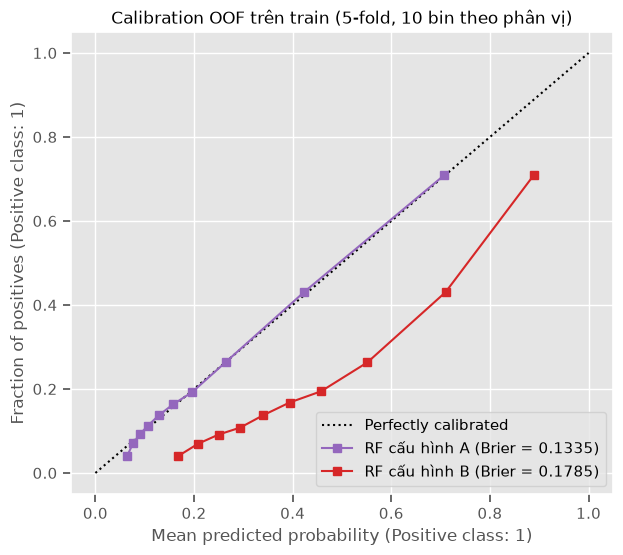

RF A: xác suất OOF trung bình = 0.2214 (tỷ lệ vỡ nợ thực tế trên train = 0.2213)
RF B: xác suất OOF trung bình = 0.4262 (tỷ lệ vỡ nợ thực tế trên train = 0.2213)


In [61]:
# Calibration OOF trên train (cross_val_predict 5-fold, cùng skf) cho RF cấu hình A và B
oof_rf = {'A': oof_proba['rf'],  # đã tính ở mục 4.3 với base_pipe('rf', 'A')
          'B': cross_val_predict(base_pipe('rf', 'B'), X_train4, y_train, cv=skf, method='predict_proba', n_jobs=-1)[:, 1]}
fig, ax = plt.subplots(figsize=(7, 6))
for cfg, color in [('A', 'tab:purple'), ('B', 'tab:red')]:
    CalibrationDisplay.from_predictions(y_train, oof_rf[cfg], n_bins=10, strategy='quantile', color=color, ax=ax,
                                       name=f"RF cấu hình {cfg} (Brier = {brier_score_loss(y_train, oof_rf[cfg]):.4f})")
ax.set_title('Calibration OOF trên train (5-fold, 10 bin theo phân vị)')
save_fig('ch4b_calibration_oof_train', fig)
plt.show()
for cfg in 'AB':
    print(f"RF {cfg}: xác suất OOF trung bình = {oof_rf[cfg].mean():.4f} (tỷ lệ vỡ nợ thực tế trên train = {y_train.mean():.4f})")

**Nhận xét so sánh trên train:** 

* **Ngưỡng chi phí** đọc từ `cost_table` là **0,17**, chọn trên xác suất OOF train với C<sub>FN</sub>:C<sub>FP</sub> = 5:1, gần với ngưỡng Bayes 1/6 ≈ 0,167.
* **Khả năng phân biệt như nhau:** PR-AUC 0,5637 (A) so với 0,5636 (B), ROC-AUC 0,7853 so với 0,7859. Hai mô hình có cùng siêu tham số, chỉ khác trọng số lớp nên xếp hạng khách hàng gần như giống hệt.
* **Điểm làm việc:** RF A + ngưỡng chi phí có Recall **0,7412** (B: 0,6309) và Precision 0,3862 (B: 0,4728). F2 tăng từ 0,5913 lên **0,6249** (+0,0337; corrected t = 5,48; p < 10⁻⁵). Chi phí kỳ vọng 5:1 giảm từ 0,5641 xuống **0,5490**/khách hàng (−0,0151; t = −2,21; p = 0,032). F1 giảm (0,5068 so với 0,5404) vì F1 coi Precision và Recall ngang nhau. Recall của A dao động nhiều hơn giữa các fold (std 0,032 so với 0,014) vì ngưỡng được chọn lại trong từng fold.
* **Chất lượng xác suất tốt hơn rõ rệt:** Brier 0,1334 so với 0,1783 (−0,0449; t = −51,4; p < 10⁻⁴), log loss 0,4261 so với 0,5430. Xác suất OOF trung bình của RF A là **0,2214**, khớp tỷ lệ vỡ nợ thực tế 0,2213. RF B cho 0,4262, gần gấp đôi. Trên calibration curve OOF, RF A bám sát đường chéo, còn RF B nằm dưới đường chéo ở mọi bin.
* **Áp dụng quy tắc chọn:** F2 và chi phí 5:1 của RF A không những không kém mà còn **tốt hơn RF B có ý nghĩa** (α = 0,05), và Brier thấp hơn. Vì vậy **RF A + ngưỡng chi phí được chọn làm mô hình cuối**. Quyết định này được đưa ra hoàn toàn trên train, trước khi đánh giá test.
* Để đối chiếu: nếu dùng t-test thường, |t| lớn gấp ≈ 3,67 lần. Với F2 và Brier, kết luận không đổi. Với chi phí, p của t-test thường nhỏ hơn nhiều so với p = 0,032 của corrected t-test.

### Đánh giá RF A + ngưỡng chi phí trên tập test

Mô hình ứng viên được fit trên toàn bộ `X_train4` với ngưỡng chi phí đã chọn trên train, rồi đánh giá trên `X_test4`. RF B lấy lại từ mục 4.5 (`final_models['rf']`), nên cùng một đối tượng mô hình đã đánh giá trước đó. Khoảng tin cậy bootstrap dùng lại đúng `boot_idx` của mục 4.5.

In [62]:
rf_A_cost = FixedThresholdClassifier(base_pipe('rf', 'A'), threshold=RF_COST_THRESHOLD).fit(X_train4, y_train)
rf_models_b = {NAME_B: final_models['rf'], NAME_A: rf_A_cost}
proba_b = {n: m.predict_proba(X_test4)[:, 1] for n, m in rf_models_b.items()}
pred_b = {n: m.predict(X_test4) for n, m in rf_models_b.items()}

rows = []
for n in rf_models_b:
    p, yp = proba_b[n], pred_b[n]
    auc = roc_auc_score(y_test, p)
    rows.append({'Mô hình': n, 'Ngưỡng': rf_models_b[n].threshold, 'Precision': precision_score(y_test, yp),
                 'Recall': recall_score(y_test, yp), 'F1': f1_score(y_test, yp), 'F2': fbeta_score(y_test, yp, beta=2),
                 cost_col: cost_per_customer(y_test, yp), 'PR-AUC': average_precision_score(y_test, p),
                 'ROC-AUC': auc, 'Gini': 2 * auc - 1, 'KS': ks_stat(y_test, p), 'Brier': brier_score_loss(y_test, p),
                 'Log loss': log_loss(y_test, p), 'P(default) trung bình': p.mean()})
    print(f"===== {n} =====")
    print(classification_report(y_test, yp, digits=4))
rf_test_b = pd.DataFrame(rows).set_index('Mô hình')
print(f"Tỷ lệ vỡ nợ thực tế trên test: {y_test.mean():.4f}")
for n in rf_models_b:
    print(f"Xác suất vỡ nợ dự đoán trung bình — {n}: {proba_b[n].mean():.4f}")
save_table(rf_test_b, 'rf_A_vs_B_test', prefix='ch4b').T

===== RF B (balanced, ngưỡng 0,5) =====
              precision    recall  f1-score   support

           0     0.8802    0.8016    0.8391      4667
           1     0.4687    0.6161    0.5324      1326

    accuracy                         0.7606      5993
   macro avg     0.6745    0.7089    0.6857      5993
weighted avg     0.7892    0.7606    0.7712      5993

===== RF A + ngưỡng chi phí =====
              precision    recall  f1-score   support

           0     0.8902    0.6705    0.7648      4667
           1     0.3793    0.7089    0.4942      1326

    accuracy                         0.6790      5993
   macro avg     0.6348    0.6897    0.6295      5993
weighted avg     0.7772    0.6790    0.7050      5993

Tỷ lệ vỡ nợ thực tế trên test: 0.2213
Xác suất vỡ nợ dự đoán trung bình — RF B (balanced, ngưỡng 0,5): 0.4260
Xác suất vỡ nợ dự đoán trung bình — RF A + ngưỡng chi phí: 0.2206


Mô hình,"RF B (balanced, ngưỡng 0,5)",RF A + ngưỡng chi phí
Ngưỡng,0.5000,0.1700
Precision,0.4687,0.3793
Recall,0.6161,0.7089
F1,0.5324,0.4942
F2,0.5797,0.6040
Chi phí/KH (5:1),0.5792,0.5787
PR-AUC,0.5559,0.5586
ROC-AUC,0.7736,0.7733
Gini,0.5471,0.5466
KS,0.4251,0.4239


In [63]:
ci_rows = []
for n in rf_models_b:
    p = proba_b[n]
    vals = np.array([[roc_auc_score(y_test_arr[i], p[i]), average_precision_score(y_test_arr[i], p[i]),
                      brier_score_loss(y_test_arr[i], p[i])] for i in boot_idx])
    for j, m in enumerate(['ROC-AUC', 'PR-AUC', 'Brier']):
        lo, hi = np.percentile(vals[:, j], [2.5, 97.5])
        ci_rows.append({'Mô hình': n, 'Độ đo': m, 'Giá trị (test)': rf_test_b.loc[n, m], 'CI 95% dưới': lo, 'CI 95% trên': hi})
rf_ci_b = pd.DataFrame(ci_rows).set_index(['Mô hình', 'Độ đo'])
save_table(rf_ci_b, 'rf_A_vs_B_test_bootstrap_ci', prefix='ch4b')

Giá trị (test)  CI 95% dưới  CI 95% trên
Mô hình                     Độ đo                                            
RF B (balanced, ngưỡng 0,5) ROC-AUC          0.7736       0.7593       0.7884
                            PR-AUC           0.5559       0.5279       0.5822
                            Brier            0.1815       0.1769       0.1859
RF A + ngưỡng chi phí       ROC-AUC          0.7733       0.7586       0.7879
                            PR-AUC           0.5586       0.5299       0.5848
                            Brier            0.1359       0.1299       0.1417

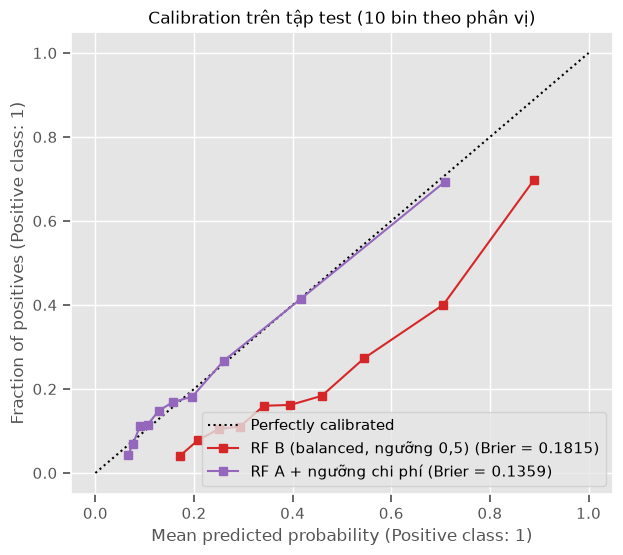

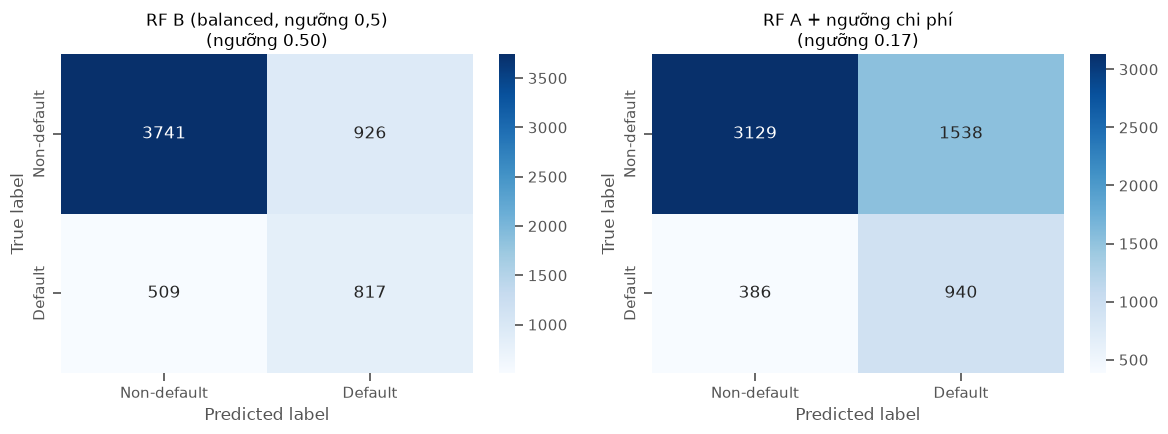

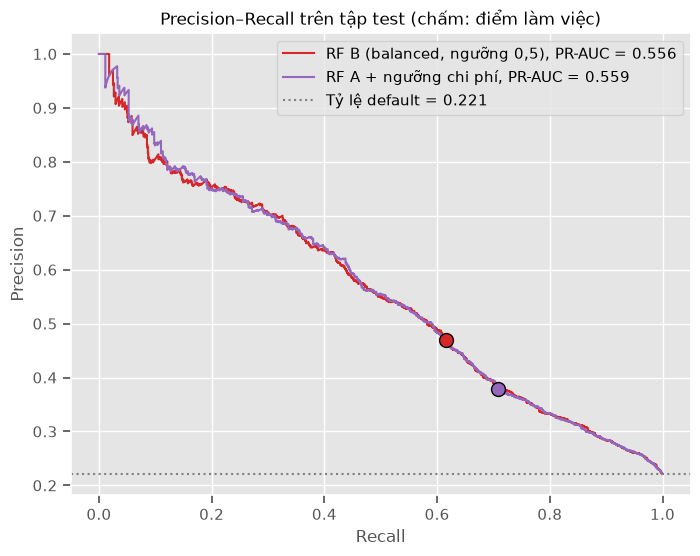

In [64]:
colors_b = {NAME_B: 'tab:red', NAME_A: 'tab:purple'}
# (a) Calibration trên test
fig, ax = plt.subplots(figsize=(7, 6))
for n in rf_models_b:
    CalibrationDisplay.from_predictions(y_test, proba_b[n], n_bins=10, strategy='quantile', color=colors_b[n], ax=ax,
                                       name=f"{n} (Brier = {rf_test_b.loc[n, 'Brier']:.4f})")
ax.set_title('Calibration trên tập test (10 bin theo phân vị)')
save_fig('ch4b_calibration_test', fig)
plt.show()

# (b) Confusion matrix cạnh nhau
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, n in zip(axes, rf_models_b):
    sns.heatmap(confusion_matrix(y_test, pred_b[n]), annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Non-default', 'Default'], yticklabels=['Non-default', 'Default'])
    ax.set_title(f"{n}\n(ngưỡng {rf_models_b[n].threshold:.2f})")
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
plt.tight_layout()
save_fig('ch4b_confusion_test', fig)
plt.show()

# (c) Đường PR trên test, đánh dấu điểm làm việc
fig, ax = plt.subplots(figsize=(8, 6))
for n in rf_models_b:
    prec, rec, _ = precision_recall_curve(y_test, proba_b[n])
    ax.plot(rec, prec, color=colors_b[n], label=f"{n}, PR-AUC = {rf_test_b.loc[n, 'PR-AUC']:.3f}")
    ax.scatter(rf_test_b.loc[n, 'Recall'], rf_test_b.loc[n, 'Precision'], color=colors_b[n], edgecolor='k', s=100, zorder=3)
ax.axhline(y_test.mean(), color='gray', ls=':', label=f'Tỷ lệ default = {y_test.mean():.3f}')
ax.set(xlabel='Recall', ylabel='Precision', title='Precision–Recall trên tập test (chấm: điểm làm việc)')
ax.legend(loc='upper right')
save_fig('ch4b_pr_test', fig)
plt.show()

**Nhận xét 4.5b (tập test):** 

* **Xác suất có ý nghĩa:** xác suất vỡ nợ dự đoán trung bình trên test của RF A là **0,2206**, sát tỷ lệ thực tế 0,2213. RF B cho 0,4260. Calibration curve trên test của RF A nằm gần như trên đường chéo, ví dụ bin dự đoán ≈ 0,42 có tỷ lệ thực tế ≈ 0,41. RF B nằm dưới đường chéo ở mọi bin, ví dụ bin dự đoán ≈ 0,70 chỉ có ≈ 0,40 vỡ nợ.
* **Brier:** 0,1359 [CI 95%: 0,1299–0,1417] so với 0,1815 [0,1769–0,1859]; hai khoảng tin cậy **không chồng lấn**. Log loss 0,4332 so với 0,5503.
* **Khả năng phân biệt không đổi:** PR-AUC 0,5586 [0,5299–0,5848] so với 0,5559, ROC-AUC 0,7733 so với 0,7736, Gini 0,5466 và KS 0,4239 xấp xỉ RF B.
* **Đánh đổi ở điểm làm việc:** với ngưỡng 0,17, RF A phát hiện **70,9%** khách hàng vỡ nợ (940/1.326) so với 61,6% (817) của RF B, tức thêm 123 khách hàng vỡ nợ được cảnh báo. Đổi lại có thêm ≈ 612 cảnh báo nhầm: FP tăng từ 926 lên 1.538, Precision giảm từ 0,4687 xuống 0,3793, Accuracy từ 0,7606 xuống 0,6790. F2 tăng từ 0,5797 lên 0,6040. Chi phí kỳ vọng 5:1 trên test gần như bằng nhau (0,5787 so với 0,5792): 123 × 5 ≈ 615 đơn vị tiết kiệm từ FN bù cho ≈ 612 đơn vị chi phí FP tăng thêm. Ưu thế về chi phí thấy trên CV (−0,015) không lặp lại rõ trên một tập test.
* Kết quả test nhất quán với lựa chọn đã làm trên train. RF A + ngưỡng chi phí giữ nguyên khả năng phân biệt của RF B, tăng Recall và cho xác suất vỡ nợ **dùng được trực tiếp** (hiển thị trong ứng dụng, phân nhóm rủi ro, tính tổn thất kỳ vọng).

<a id='ch4_6'></a>
## 4.6. Diễn giải mô hình (trả lời CH1)

* **Permutation importance** trên tập test (`scoring='average_precision'`, 30 lần hoán vị): mức giảm PR-AUC khi xáo trộn ngẫu nhiên một cột — đo trực tiếp mức độ mô hình dựa vào đặc trưng đó trên dữ liệu chưa thấy, áp dụng được cho cả RF và LR. Hoán vị được thực hiện trên cột đầu vào gốc (trước one-hot/log1p), nên EDUCATION hay PAY_RATIO được đánh giá như một đặc trưng.
* **MDI** (`feature_importances_` của RF): tính trên dữ liệu train, thiên vị các đặc trưng liên tục/nhiều giá trị — dùng để đối chiếu.
* **Hệ số và odds ratio** của LR trên dữ liệu đã chuẩn hoá: odds ratio = exp(hệ số) là hệ số nhân của odds vỡ nợ khi đặc trưng tăng 1 độ lệch chuẩn (với biến one-hot: so với nhóm tham chiếu).

Permutation importance trong 13 giây


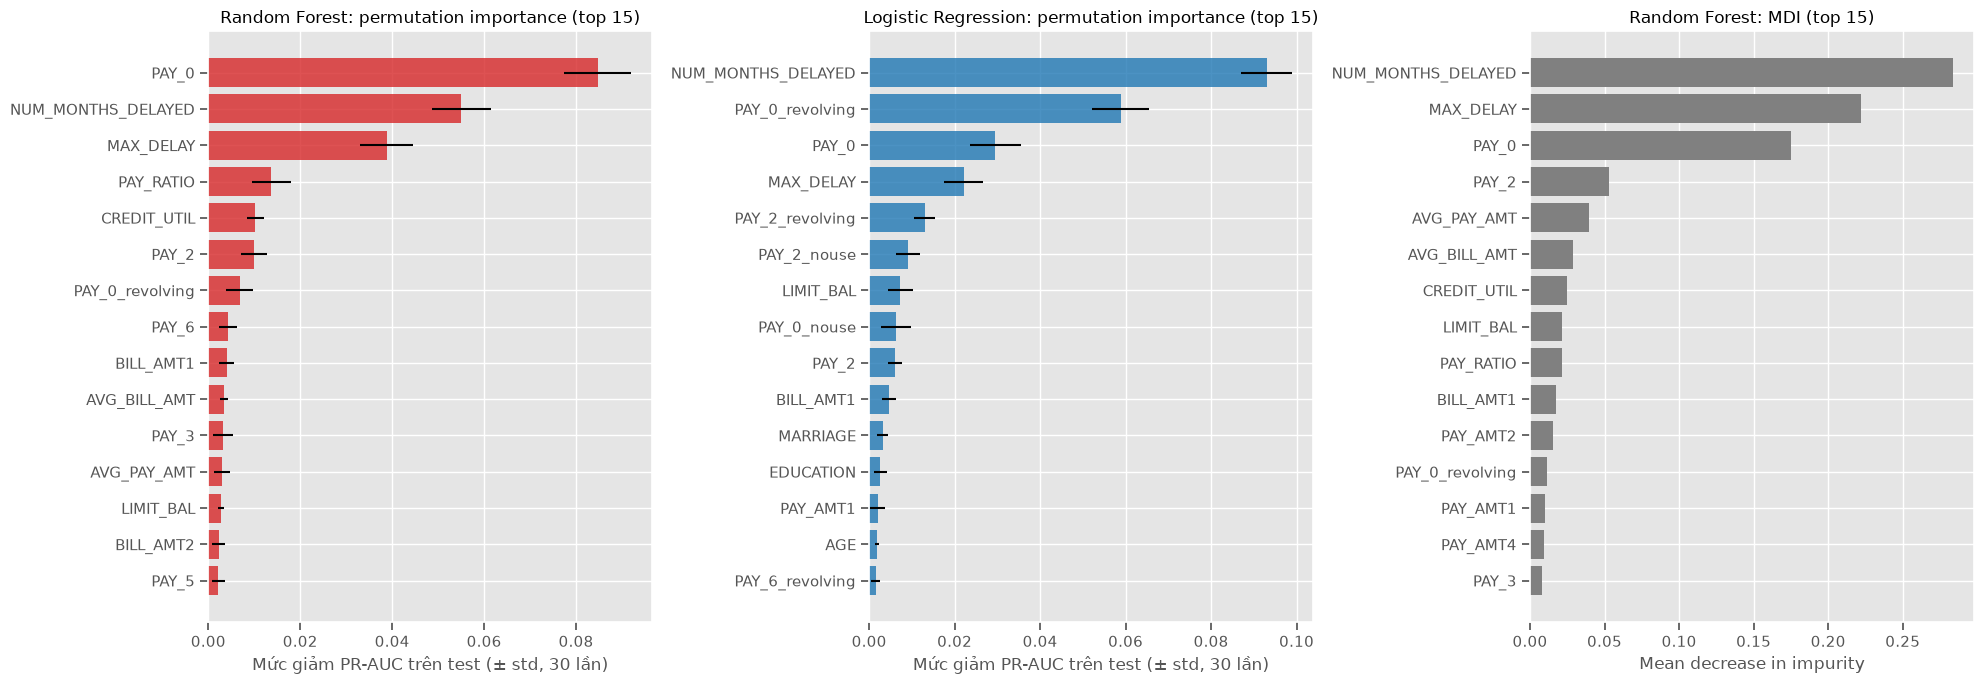

RF: tương quan hạng Spearman giữa permutation importance và MDI = 0.686; 12/15 đặc trưng chung trong top 15
Top 5 RF (perm): ['PAY_0', 'NUM_MONTHS_DELAYED', 'MAX_DELAY', 'PAY_RATIO', 'CREDIT_UTIL']
Top 5 LR (perm): ['NUM_MONTHS_DELAYED', 'PAY_0_revolving', 'PAY_0', 'MAX_DELAY', 'PAY_2_revolving']


,RF perm mean,RF perm std,RF perm hạng,RF MDI,RF MDI hạng,LR perm mean,LR perm std,LR perm hạng
PAY_0,0.0847,0.0073,1.0000,0.1753,3.0000,0.0295,0.0060,3.0000
NUM_MONTHS_DELAYED,0.0550,0.0064,2.0000,0.2836,1.0000,0.0930,0.0059,1.0000
MAX_DELAY,0.0388,0.0058,3.0000,0.2221,2.0000,0.0221,0.0046,4.0000
PAY_RATIO,0.0137,0.0042,4.0000,0.0213,9.0000,0.0009,0.0004,19.0000
CREDIT_UTIL,0.0102,0.0018,5.0000,0.0247,7.0000,0.0015,0.0017,16.0000
PAY_2,0.0099,0.0028,6.0000,0.0529,4.0000,0.0060,0.0016,9.0000
PAY_0_revolving,0.0068,0.0030,7.0000,0.0112,12.0000,0.0588,0.0066,2.0000
PAY_6,0.0043,0.0020,8.0000,0.0011,28.0000,-0.0004,0.0011,41.0000
BILL_AMT1,0.0040,0.0016,9.0000,0.0177,10.0000,0.0046,0.0017,10.0000
AVG_BILL_AMT,0.0034,0.0009,10.0000,0.0289,6.0000,0.0000,0.0000,34.0000


In [65]:
t0 = time.perf_counter()
perm = {}
for kind in ['rf', 'lr']:
    r = permutation_importance(final_models[kind], X_test4, y_test, scoring='average_precision',
                               n_repeats=PI_REPEATS, random_state=RANDOM_STATE, n_jobs=-1)
    perm[kind] = pd.DataFrame({'mean': r.importances_mean, 'std': r.importances_std},
                              index=X_test4.columns).sort_values('mean', ascending=False)
print(f"Permutation importance trong {time.perf_counter() - t0:.0f} giây")

rf_pipe = final_models['rf'].estimator_
rf_mdi = pd.Series(rf_pipe.named_steps['clf'].feature_importances_,
                   index=rf_pipe.named_steps['prep'].get_feature_names_out()).sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, kind in zip(axes[:2], ['rf', 'lr']):
    top = perm[kind].head(15)[::-1]
    ax.barh(top.index, top['mean'], xerr=top['std'], color=colors[kind], alpha=0.8)
    ax.set_title(f'{model_names[kind]}: permutation importance (top 15)')
    ax.set_xlabel('Mức giảm PR-AUC trên test (± std, 30 lần)')
top = rf_mdi.head(15)[::-1]
axes[2].barh(top.index, top.values, color='gray')
axes[2].set_title('Random Forest: MDI (top 15)')
axes[2].set_xlabel('Mean decrease in impurity')
plt.tight_layout()
save_fig('ch4_permutation_importance', fig)
plt.show()

imp_table = pd.concat({
    'RF perm mean': perm['rf']['mean'], 'RF perm std': perm['rf']['std'],
    'RF perm hạng': perm['rf']['mean'].rank(ascending=False),
    'RF MDI': rf_mdi, 'RF MDI hạng': rf_mdi.rank(ascending=False),
    'LR perm mean': perm['lr']['mean'], 'LR perm std': perm['lr']['std'],
    'LR perm hạng': perm['lr']['mean'].rank(ascending=False),
}, axis=1).sort_values('RF perm mean', ascending=False)
save_table(imp_table.round(5), 'feature_importance')
rho = imp_table[['RF perm mean', 'RF MDI']].corr(method='spearman').iloc[0, 1]
overlap = set(perm['rf'].head(15).index) & set(rf_mdi.head(15).index)
print(f"RF: tương quan hạng Spearman giữa permutation importance và MDI = {rho:.3f}; "
      f"{len(overlap)}/15 đặc trưng chung trong top 15")
print(f"Top 5 RF (perm): {list(perm['rf'].index[:5])}")
print(f"Top 5 LR (perm): {list(perm['lr'].index[:5])}")
imp_table.head(15).round(4)

In [66]:
lr_pipe = final_models['lr'].estimator_
lr_coef_table = pd.DataFrame({'Hệ số': lr_pipe.named_steps['clf'].coef_[0]},
                             index=lr_pipe.named_steps['prep'].get_feature_names_out())
lr_coef_table['Odds ratio'] = np.exp(lr_coef_table['Hệ số'])
lr_coef_table = lr_coef_table.sort_values('Hệ số', key=abs, ascending=False)
lr_coef_table.index.name = 'Đặc trưng (đã chuẩn hoá)'
save_table(lr_coef_table.round(4), 'lr_coefficients')
print(f"Hệ số chặn: {lr_pipe.named_steps['clf'].intercept_[0]:.4f}; C = {lr_pipe.named_steps['clf'].C:.4g}")
lr_coef_table.head(15).round(4)

Hệ số chặn: -0.1705; C = 58.48


,Hệ số,Odds ratio
Đặc trưng (đã chuẩn hoá),,
EDUCATION_4,-0.9086,0.4031
PAY_0_revolving,-0.5234,0.5925
NUM_MONTHS_DELAYED,0.4229,1.5264
PAY_0,0.2793,1.3222
MAX_DELAY,0.2775,1.3198
LIMIT_BAL,-0.2239,0.7994
PAY_2_revolving,0.2062,1.2290
PAY_2_nouse,-0.1993,0.8193
PAY_0_nouse,0.1787,1.1957


### SHAP cho Random Forest

SHAP (`TreeExplainer`) phân rã xác suất vỡ nợ dự đoán của từng khách hàng thành đóng góp của từng đặc trưng, tính trên mẫu 1.000 dòng của tập test. Summary plot (beeswarm) cho thấy hướng tác động (giá trị đặc trưng cao/thấp đẩy xác suất lên hay xuống); waterfall plot giải thích dự đoán cho 2 khách hàng cụ thể (1 vỡ nợ, 1 không vỡ nợ).

SHAP cho 1000 dòng trong 0 giây (shap 0.52.0)


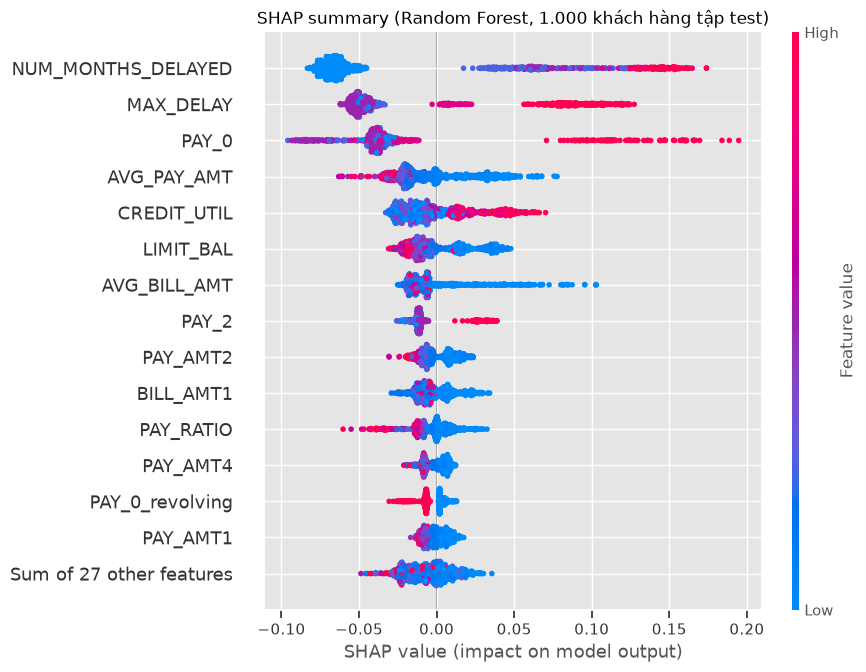

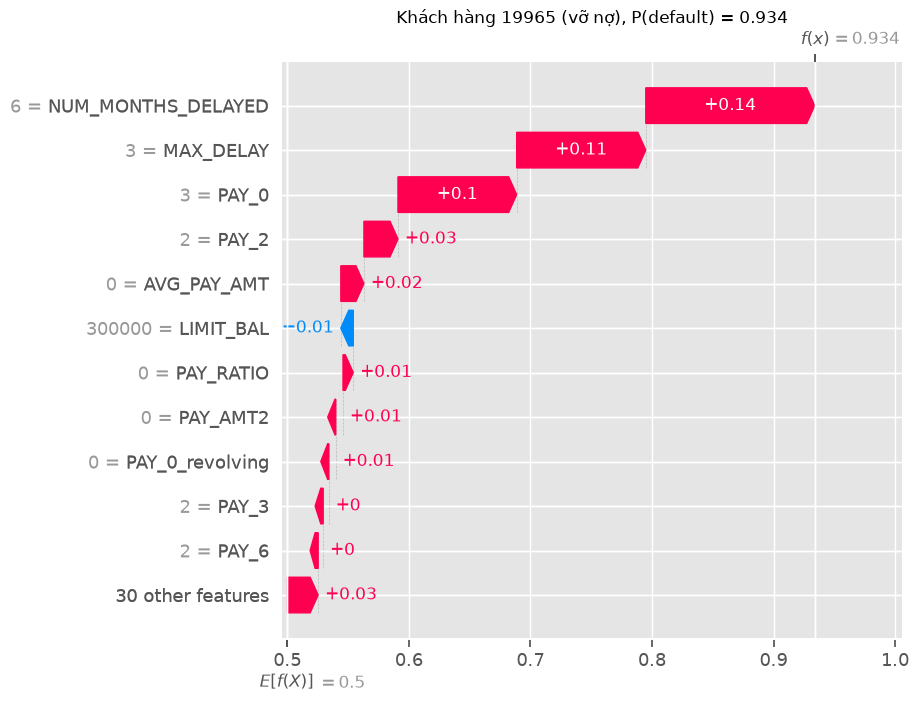

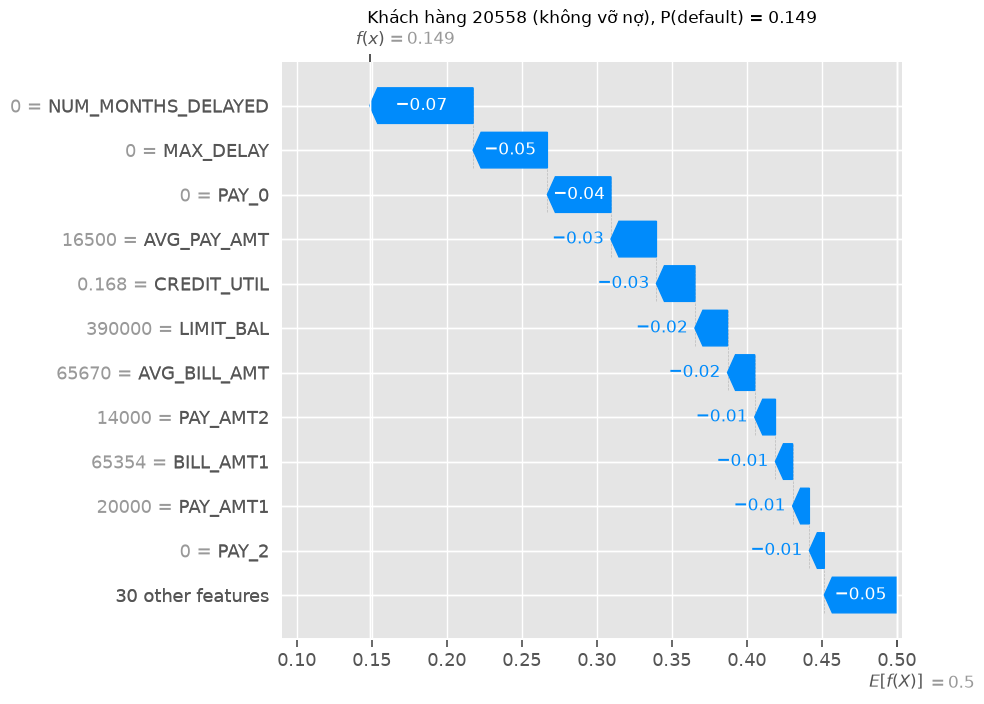

NUM_MONTHS_DELAYED   0.0740
MAX_DELAY            0.0578
PAY_0                0.0481
AVG_PAY_AMT          0.0211
CREDIT_UTIL          0.0187
LIMIT_BAL            0.0160
AVG_BILL_AMT         0.0158
PAY_2                0.0146
PAY_AMT2             0.0093
BILL_AMT1            0.0092


In [67]:
try:
    import shap
except ImportError:
    shap = None
    print("Không cài được thư viện shap — bỏ qua phần SHAP.")

if shap is not None:
    X_shap = X_test4.sample(SHAP_N, random_state=RANDOM_STATE)
    Xt = X_shap
    for name, step in rf_pipe.steps[:-1]:
        if name != 'smote':  # SMOTE chỉ tác động lúc fit
            Xt = step.transform(Xt)
    Xt = pd.DataFrame(np.asarray(Xt), columns=rf_pipe.named_steps['prep'].get_feature_names_out(), index=X_shap.index)
    t0 = time.perf_counter()
    sv = shap.TreeExplainer(rf_pipe.named_steps['clf'])(Xt)[:, :, 1]  # lớp 1 = default
    print(f"SHAP cho {SHAP_N} dòng trong {time.perf_counter() - t0:.0f} giây (shap {shap.__version__})")

    shap.plots.beeswarm(sv, max_display=15, show=False)
    plt.title('SHAP summary (Random Forest, 1.000 khách hàng tập test)')
    save_fig('ch4_shap_beeswarm_rf')
    plt.show()

    proba_shap = pd.Series(test_proba['rf'], index=X_test4.index).loc[X_shap.index]
    y_shap = y_test.loc[X_shap.index]
    examples = {'default': proba_shap[y_shap == 1].idxmax(), 'nondefault': proba_shap[y_shap == 0].idxmin()}
    for label, idx in examples.items():
        pos = X_shap.index.get_loc(idx)
        shap.plots.waterfall(sv[pos], max_display=12, show=False)
        plt.title(f"Khách hàng {idx} ({'vỡ nợ' if label == 'default' else 'không vỡ nợ'}), "
                  f"P(default) = {proba_shap[idx]:.3f}")
        save_fig(f'ch4_shap_waterfall_{label}')
        plt.show()
    shap_rank = pd.Series(np.abs(sv.values).mean(axis=0), index=Xt.columns, name='mean |SHAP|').sort_values(ascending=False)
    save_table(shap_rank.round(5).to_frame(), 'shap_mean_abs')
    print(shap_rank.head(10).round(4).to_string())

Hai khách hàng minh hoạ được chọn là khách hàng vỡ nợ có xác suất dự đoán cao nhất và khách hàng không vỡ nợ có xác suất thấp nhất trong mẫu 1.000 dòng.

**Nhận xét 4.6 (CH1):**  

* **Hành vi trả nợ gần đây chi phối dự đoán.** Với RF, top 3 theo permutation importance là **PAY_0** (PR-AUC giảm 0,0847 khi xáo trộn), **NUM_MONTHS_DELAYED** (0,0550) và **MAX_DELAY** (0,0388). Theo MDI và SHAP (mean |SHAP|: NUM_MONTHS_DELAYED 0,074; MAX_DELAY 0,058; PAY_0 0,048), cùng 3 đặc trưng này vẫn đứng đầu, chỉ khác thứ tự. Với LR, top đầu là NUM_MONTHS_DELAYED (0,0930), PAY_0_revolving (0,0588), PAY_0 (0,0295) và MAX_DELAY (0,0221).
* **Nhóm thứ hai là năng lực tài chính và mức sử dụng tín dụng:** PAY_RATIO, CREDIT_UTIL, AVG_PAY_AMT, LIMIT_BAL, BILL_AMT1. Beeswarm SHAP cho thấy hướng tác động phù hợp nghiệp vụ: CREDIT_UTIL cao làm tăng rủi ro; LIMIT_BAL cao, AVG_PAY_AMT cao và PAY_RATIO cao làm giảm rủi ro.
* **Biến nhân khẩu học ảnh hưởng yếu.** Với RF, AGE, SEX, MARRIAGE, EDUCATION không có trong top 15 permutation importance. Hệ số âm lớn của EDUCATION_4 trong LR (−0,91; odds ratio 0,40) thuộc về nhóm "khác" chỉ chiếm 1,6% dữ liệu, nên không nên diễn giải như một yếu tố chính.
* **Permutation importance so với MDI (RF):** tương quan hạng Spearman 0,686, 12/15 đặc trưng chung trong top 15. MDI đánh giá cao các đặc trưng liên tục nhiều giá trị: AVG_PAY_AMT xếp hạng 5 theo MDI nhưng 12 theo permutation, AVG_BILL_AMT hạng 6 so với 10. Ngược lại, MDI đánh giá thấp PAY_6 (hạng 28 so với 8). Permutation importance trên test đáng tin cậy hơn để trả lời CH1.
* **Hệ số LR (đã chuẩn hoá):** tăng 1 độ lệch chuẩn NUM_MONTHS_DELAYED làm odds vỡ nợ tăng 1,53 lần; PAY_0 và MAX_DELAY mỗi biến ×1,32; LIMIT_BAL ×0,80; PAY_AMT1/PAY_AMT2 ×0,85–0,86. Khách hàng dùng tín dụng quay vòng ở tháng gần nhất (PAY_0_revolving = 1) có odds thấp hơn (×0,59) khi giữ các biến khác không đổi. Điều này khẳng định lại giá trị của cờ nhị phân tạo ở Chương 3.
* **Waterfall SHAP:** khách hàng vỡ nợ minh hoạ (P = 0,934) trễ hạn cả 6 tháng (NUM_MONTHS_DELAYED = 6, MAX_DELAY = 3, PAY_0 = 3). Ba đặc trưng này đẩy xác suất từ mức nền 0,5 lên thêm +0,14, +0,11 và +0,10. Khách hàng không vỡ nợ (P = 0,149) không trễ hạn tháng nào, trả trung bình 16.500/tháng và chỉ dùng 16,8% hạn mức. Mọi đặc trưng chính đều kéo xác suất xuống. (Mức nền 0,5 là do `class_weight='balanced'`.)

**Trả lời CH1:** các yếu tố ảnh hưởng mạnh nhất đến khả năng vỡ nợ là **lịch sử trễ hạn gần đây**: tình trạng trả nợ tháng gần nhất (PAY_0), số tháng trễ hạn trong 6 tháng (NUM_MONTHS_DELAYED) và mức trễ hạn lớn nhất (MAX_DELAY). Tiếp theo là **khả năng và mức độ thanh toán** (PAY_RATIO, AVG_PAY_AMT, PAY_AMT) và **mức sử dụng/hạn mức tín dụng** (CREDIT_UTIL, LIMIT_BAL). Kết luận này nhất quán giữa hai mô hình (RF, LR) và ba phương pháp (permutation importance, MDI, SHAP). Các đặc trưng tổng hợp tạo ở bước Feature Engineering (NUM_MONTHS_DELAYED, MAX_DELAY, CREDIT_UTIL, PAY_RATIO) chiếm phần lớn nhóm đầu.

<a id='ch4_6b'></a>
### 4.6b. Diễn giải mô hình cuối sau mục 4.5b

Nếu mô hình cuối chuyển sang **RF A + ngưỡng chi phí**, permutation importance (`scoring='average_precision'`, 30 lần) và SHAP được tính lại cho mô hình này. Mẫu 1.000 dòng và **hai khách hàng minh hoạ giữ nguyên như mục 4.6**, để so sánh trực tiếp với RF B. Với RF A, mức nền SHAP E[f(X)] (xác suất trung bình của mô hình) phải xấp xỉ tỷ lệ vỡ nợ thực tế ≈ 0,221 thay vì 0,5.

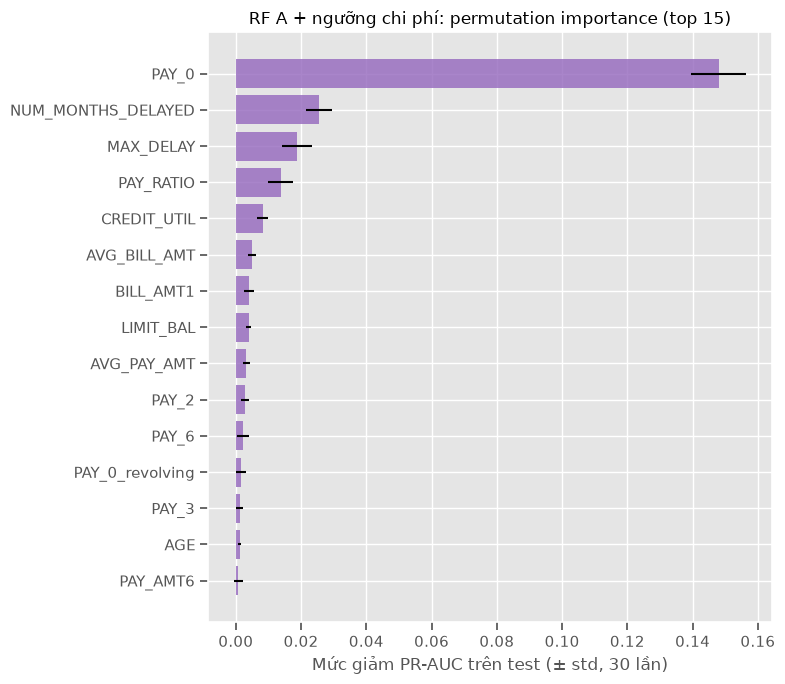

Tương quan hạng Spearman permutation importance RF A vs RF B = 0.838; top 15 chung: 13/15
                    RF A perm mean  RF A perm std  RF A hạng  RF B perm mean  RF B hạng
PAY_0                       0.1480         0.0084     1.0000          0.0847     1.0000
NUM_MONTHS_DELAYED          0.0256         0.0040     2.0000          0.0550     2.0000
MAX_DELAY                   0.0188         0.0046     3.0000          0.0388     3.0000
PAY_RATIO                   0.0138         0.0038     4.0000          0.0137     4.0000
CREDIT_UTIL                 0.0083         0.0017     5.0000          0.0102     5.0000
AVG_BILL_AMT                0.0049         0.0012     6.0000          0.0034    10.0000
BILL_AMT1                   0.0040         0.0015     7.0000          0.0040     9.0000
LIMIT_BAL                   0.0040         0.0007     8.0000          0.0028    13.0000
AVG_PAY_AMT                 0.0032         0.0011     9.0000          0.0029    12.0000
PAY_2                       0.

In [68]:
if not USE_RF_A:
    print("Mô hình cuối vẫn là RF B — phần diễn giải ở mục 4.6 giữ nguyên.")
else:
    r = permutation_importance(rf_A_cost, X_test4, y_test, scoring='average_precision',
                               n_repeats=PI_REPEATS, random_state=RANDOM_STATE, n_jobs=-1)
    perm_A = pd.DataFrame({'mean': r.importances_mean, 'std': r.importances_std},
                          index=X_test4.columns).sort_values('mean', ascending=False)
    perm_AB = pd.concat({'RF A perm mean': perm_A['mean'], 'RF A perm std': perm_A['std'],
                         'RF A hạng': perm_A['mean'].rank(ascending=False),
                         'RF B perm mean': perm['rf']['mean'], 'RF B hạng': perm['rf']['mean'].rank(ascending=False)},
                        axis=1).sort_values('RF A perm mean', ascending=False)
    save_table(perm_AB, 'rf_A_permutation_importance', prefix='ch4b')

    fig, ax = plt.subplots(figsize=(8, 7))
    top = perm_A.head(15)[::-1]
    ax.barh(top.index, top['mean'], xerr=top['std'], color='tab:purple', alpha=0.8)
    ax.set_title('RF A + ngưỡng chi phí: permutation importance (top 15)')
    ax.set_xlabel('Mức giảm PR-AUC trên test (± std, 30 lần)')
    plt.tight_layout()
    save_fig('ch4b_permutation_importance', fig)
    plt.show()
    rho_AB = perm_AB[['RF A perm mean', 'RF B perm mean']].corr(method='spearman').iloc[0, 1]
    print(f"Tương quan hạng Spearman permutation importance RF A vs RF B = {rho_AB:.3f}; "
          f"top 15 chung: {len(set(perm_A.head(15).index) & set(perm['rf'].head(15).index))}/15")
    print(perm_AB.head(15).round(4).to_string())

SHAP base value E[f(X)]: RF A = 0.2213, RF B = 0.5001 (tỷ lệ vỡ nợ train = 0.2213)


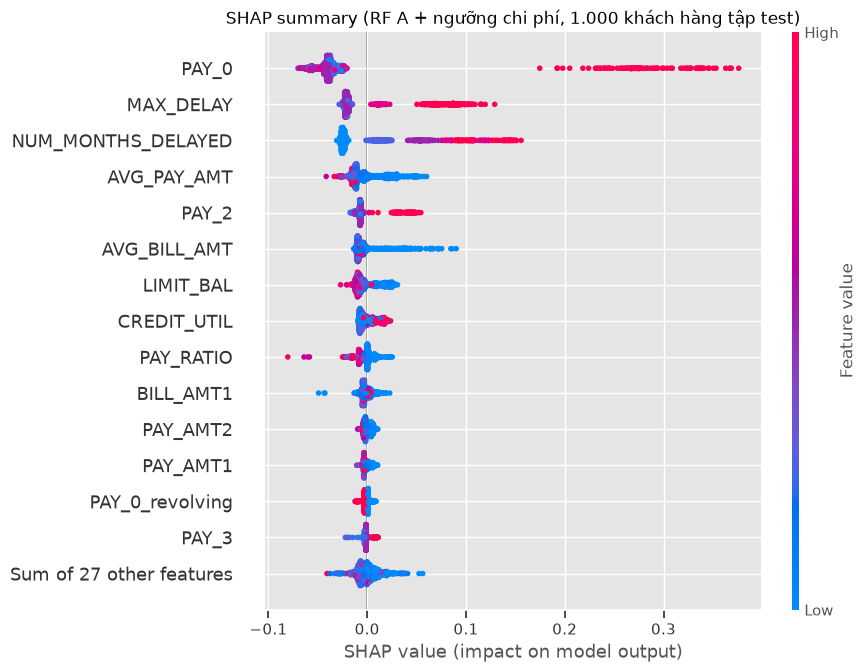

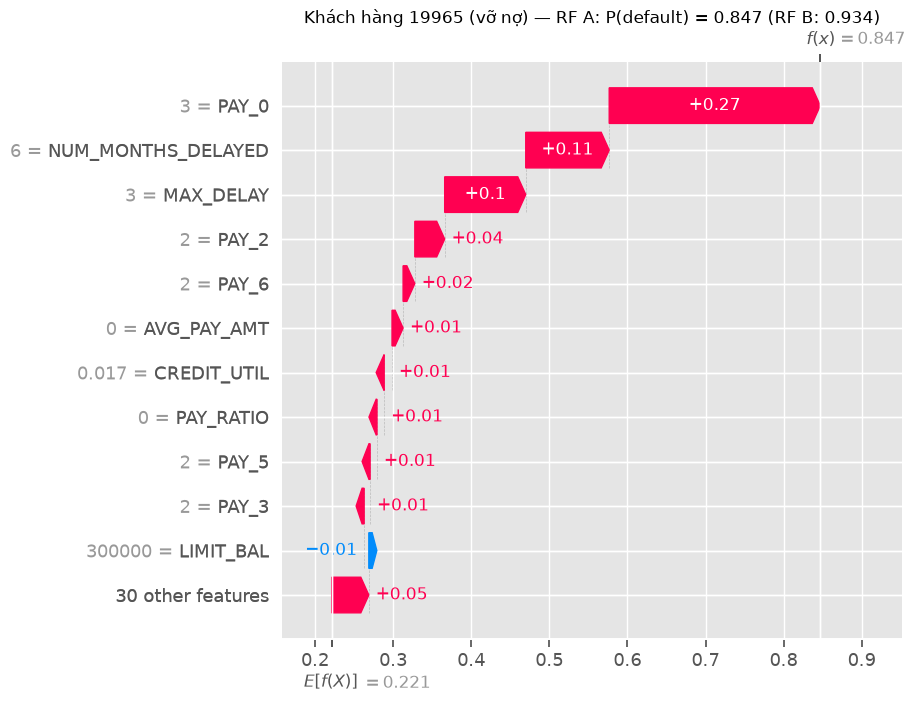

Khách hàng 19965: P(default) RF A = 0.8470, RF B = 0.9338; dự đoán RF A = 1 (ngưỡng 0.17)


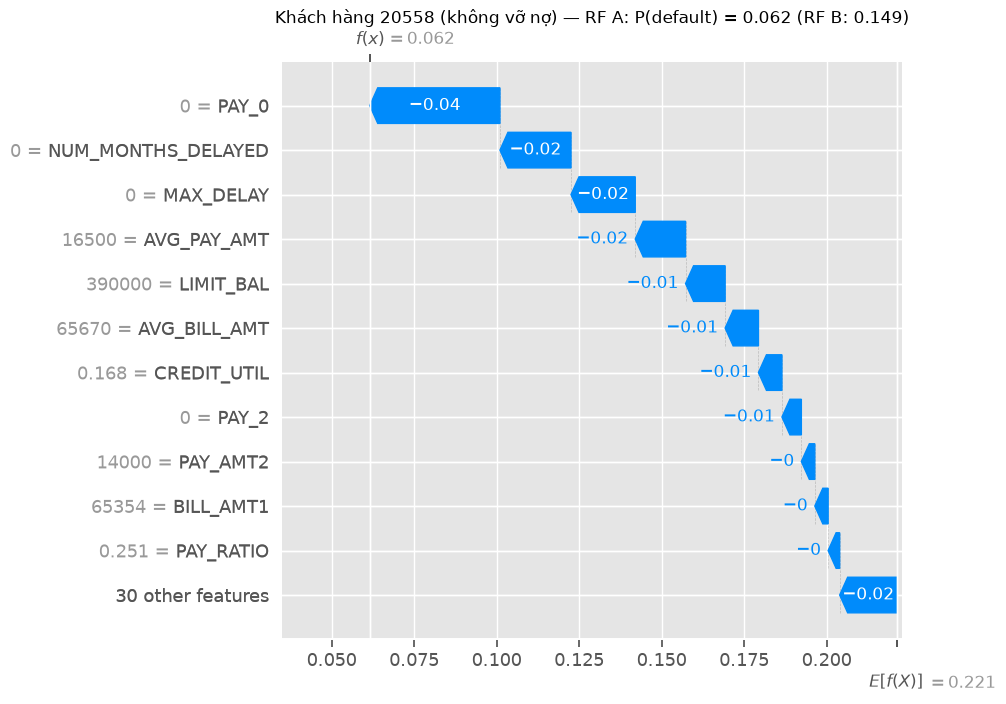

Khách hàng 20558: P(default) RF A = 0.0615, RF B = 0.1487; dự đoán RF A = 0 (ngưỡng 0.17)
PAY_0                0.0627
MAX_DELAY            0.0357
NUM_MONTHS_DELAYED   0.0349
AVG_PAY_AMT          0.0143
PAY_2                0.0117
AVG_BILL_AMT         0.0108
LIMIT_BAL            0.0106
CREDIT_UTIL          0.0070
PAY_RATIO            0.0056
BILL_AMT1            0.0042


In [69]:
if USE_RF_A and shap is not None:
    rf_A_pipe = rf_A_cost.estimator_
    Xt_A = pd.DataFrame(rf_A_pipe.named_steps['prep'].transform(X_shap),
                        columns=rf_A_pipe.named_steps['prep'].get_feature_names_out(), index=X_shap.index)
    sv_A = shap.TreeExplainer(rf_A_pipe.named_steps['clf'])(Xt_A)[:, :, 1]
    print(f"SHAP base value E[f(X)]: RF A = {sv_A.base_values[0]:.4f}, RF B = {sv.base_values[0]:.4f} "
          f"(tỷ lệ vỡ nợ train = {y_train.mean():.4f})")

    shap.plots.beeswarm(sv_A, max_display=15, show=False)
    plt.title('SHAP summary (RF A + ngưỡng chi phí, 1.000 khách hàng tập test)')
    save_fig('ch4b_shap_beeswarm_rf_A')
    plt.show()

    proba_shap_A = pd.Series(proba_b[NAME_A], index=X_test4.index).loc[X_shap.index]
    for label, idx in examples.items():  # cùng 2 khách hàng như mục 4.6
        pos = X_shap.index.get_loc(idx)
        shap.plots.waterfall(sv_A[pos], max_display=12, show=False)
        plt.title(f"Khách hàng {idx} ({'vỡ nợ' if label == 'default' else 'không vỡ nợ'}) — RF A: "
                  f"P(default) = {proba_shap_A[idx]:.3f} (RF B: {proba_shap[idx]:.3f})")
        save_fig(f'ch4b_shap_waterfall_{label}')
        plt.show()
        print(f"Khách hàng {idx}: P(default) RF A = {proba_shap_A[idx]:.4f}, RF B = {proba_shap[idx]:.4f}; "
              f"dự đoán RF A = {int(proba_shap_A[idx] >= RF_COST_THRESHOLD)} (ngưỡng {RF_COST_THRESHOLD:.2f})")
    shap_rank_A = pd.Series(np.abs(sv_A.values).mean(axis=0), index=Xt_A.columns, name='mean |SHAP|').sort_values(ascending=False)
    save_table(shap_rank_A.to_frame(), 'rf_A_shap_mean_abs', prefix='ch4b')
    print(shap_rank_A.head(10).round(4).to_string())

**Nhận xét 4.6b:** 

* **Mức nền SHAP của RF A là 0,2213**, đúng bằng tỷ lệ vỡ nợ trên train, so với 0,5001 của RF B. Đóng góp SHAP giờ là độ lệch so với xác suất vỡ nợ trung bình thực tế, nên dễ giải thích với người dùng nghiệp vụ.
* **Thứ tự quan trọng gần như giữ nguyên:** tương quan hạng Spearman của permutation importance giữa RF A và RF B là 0,838, với 13/15 đặc trưng chung trong top 15. Năm đặc trưng đầu giống hệt: PAY_0, NUM_MONTHS_DELAYED, MAX_DELAY, PAY_RATIO, CREDIT_UTIL. Khác biệt chính là RF A dựa **nhiều hơn vào PAY_0**: xáo trộn PAY_0 làm PR-AUC giảm 0,1480, so với 0,0847 ở RF B. RF A cũng dựa ít hơn vào NUM_MONTHS_DELAYED (0,0256 so với 0,0550) và MAX_DELAY (0,0188 so với 0,0388). Theo mean |SHAP|, PAY_0 cũng đứng đầu (0,0627), tiếp theo là MAX_DELAY (0,0357) và NUM_MONTHS_DELAYED (0,0349).
* **Hai khách hàng minh hoạ (giống mục 4.6):**
  * Khách hàng 19965 (vỡ nợ) có P(default) = 0,847 theo RF A (RF B: 0,934). Xuất phát từ mức nền 0,221, PAY_0 = 3 cộng +0,27, NUM_MONTHS_DELAYED = 6 cộng +0,11, MAX_DELAY = 3 cộng +0,10.
  * Khách hàng 20558 (không vỡ nợ) có P(default) = 0,062 theo RF A, thuộc nhóm rủi ro Thấp. RF B cho 0,149, dễ gây hiểu nhầm là rủi ro trung bình.
* Kết luận cho CH1 ở mục 4.6 không đổi: lịch sử trễ hạn gần đây, đặc biệt là tình trạng tháng gần nhất PAY_0, là yếu tố quyết định, tiếp theo là khả năng thanh toán và mức sử dụng hạn mức.

<a id='ch4_7'></a>
## 4.7. Chọn mô hình và lưu

### Nhóm rủi ro

Xác suất dự đoán của mô hình cuối được chia thành 3 nhóm rủi ro: **Thấp (< 0,10)**, **Trung bình (0,10–0,30)**, **Cao (≥ 0,30)**. Bảng dưới cho số khách hàng và tỷ lệ vỡ nợ thực tế từng nhóm trên tập test, kèm phân bố trên xác suất OOF của train để đối chiếu. Để có phương án ngưỡng nhóm khác, ta lấy **phân vị 50% và 80% của xác suất OOF trên train**: nửa số khách hàng được xếp Thấp, 30% Trung bình, 20% Cao. Phương án này chỉ dựa trên train, không dùng tập test để chọn.

In [70]:
FINAL_NAME = NAME_A if USE_RF_A else NAME_B
final_model = rf_models_b[FINAL_NAME]
final_proba_test = proba_b[FINAL_NAME]
final_oof = oof_rf['A' if USE_RF_A else 'B']
BAND_LABELS = ['Thấp', 'Trung bình', 'Cao']


def risk_band_table(proba, y, edges):
    """Số khách hàng, tỷ trọng và tỷ lệ vỡ nợ thực tế theo nhóm rủi ro [edges[i], edges[i+1])."""
    bands = pd.cut(proba, bins=[0] + list(edges) + [1 + 1e-9], right=False, labels=BAND_LABELS)
    g = pd.Series(np.asarray(y)).groupby(bands, observed=False)
    return pd.DataFrame({'Số KH': g.size(), 'Tỷ trọng': g.size() / len(y), 'Số vỡ nợ': g.sum(),
                         'Tỷ lệ vỡ nợ thực tế': g.mean(), 'P(default) TB dự đoán':
                         pd.Series(proba).groupby(bands, observed=False).mean()})


FIXED_EDGES = [0.10, 0.30]
QUANTILE_EDGES = [round(float(q), 2) for q in np.quantile(final_oof, [0.5, 0.8])]
band_tables = {
    ('Cố định 0,10 / 0,30', 'OOF train'): risk_band_table(final_oof, y_train, FIXED_EDGES),
    ('Cố định 0,10 / 0,30', 'Test'): risk_band_table(final_proba_test, y_test, FIXED_EDGES),
    (f'Phân vị OOF {QUANTILE_EDGES[0]:.2f} / {QUANTILE_EDGES[1]:.2f}', 'OOF train'): risk_band_table(final_oof, y_train, QUANTILE_EDGES),
    (f'Phân vị OOF {QUANTILE_EDGES[0]:.2f} / {QUANTILE_EDGES[1]:.2f}', 'Test'): risk_band_table(final_proba_test, y_test, QUANTILE_EDGES),
}
risk_table = pd.concat(band_tables, names=['Phương án ngưỡng nhóm', 'Tập', 'Nhóm'])
print(f"Mô hình cuối: {FINAL_NAME}; ngưỡng nhóm theo phân vị 50%/80% của OOF train: {QUANTILE_EDGES}")
save_table(risk_table, 'risk_bands', prefix='ch4b')

Mô hình cuối: RF A + ngưỡng chi phí; ngưỡng nhóm theo phân vị 50%/80% của OOF train: [0.14, 0.33]


Số KH  Tỷ trọng  Số vỡ nợ  Tỷ lệ vỡ nợ thực tế  \
Phương án ngưỡng nhóm   Tập       Nhóm                                                         
Cố định 0,10 / 0,30     OOF train Thấp         7558    0.3153       519               0.0687   
                                  Trung bình  11236    0.4687      1922               0.1711   
                                  Cao          5178    0.2160      2863               0.5529   
                        Test      Thấp         1882    0.3140       143               0.0760   
                                  Trung bình   2819    0.4704       484               0.1717   
                                  Cao          1292    0.2156       699               0.5410   
Phân vị OOF 0.14 / 0.33 OOF train Thấp        11741    0.4898      1050               0.0894   
                                  Trung bình   7458    0.3111      1532               0.2054   
                                  Cao          4773    0.1991      2722               0.5703   
                        Test      Thấp         2930    0.4889       283               0.0966   
                                  Trung bình   1891    0.3155       390               0.2062   
                                  Cao          1172    0.1956       653               0.5572   

                                              P(default) TB dự đoán  
Phương án ngưỡng nhóm   Tập       Nhóm                               
Cố định 0,10 / 0,30     OOF train Thấp                       0.0779  
                                  Trung bình                 0.1681  
                                  Cao                        0.5464  
                        Test      Thấp                       0.0785  
                                  Trung bình                 0.1671  
                                  Cao                        0.5442  
Phân vị OOF 0.14 / 0.33 OOF train Thấp                       0.0922  
                                  Trung bình                 0.2042  
                                  Cao                        0.5660  
                        Test      Thấp                       0.0923  
                                  Trung bình                 0.2041  
                                  Cao                        0.5678

**Nhận xét nhóm rủi ro:** với ngưỡng cố định 0,10 / 0,30, ba nhóm trên test có tỷ trọng **31,4% / 47,0% / 21,6%** và tỷ lệ vỡ nợ thực tế **7,6% / 17,2% / 54,1%**. Tỷ lệ tăng đơn điệu và cách xa nhau: nhóm Cao có rủi ro gấp ≈ 7 lần nhóm Thấp. Xác suất dự đoán trung bình từng nhóm (7,9% / 16,7% / 54,4%) khớp với tỷ lệ thực tế, xác nhận mô hình được hiệu chỉnh tốt. Phân bố trên OOF train gần như giống hệt (31,5% / 46,9% / 21,6%; 6,9% / 17,1% / 55,3%). Các nhóm không lệch quá mức nên **giữ ngưỡng nhóm 0,10 / 0,30** vì dễ giải thích. Phương án theo phân vị OOF train (0,14 / 0,33, tỷ trọng ≈ 50% / 30% / 20%) cho tỷ lệ vỡ nợ 9,7% / 20,6% / 55,7% trên test. Phương án này chỉ nên dùng nếu ngân hàng muốn nhóm Thấp chiếm khoảng một nửa danh mục.

Lưu ý: ngưỡng quyết định 0,17 nằm **trong** nhóm Trung bình. Khách hàng có xác suất 0,17–0,30 được mô hình gắn nhãn "có nguy cơ vỡ nợ" nhưng thuộc nhóm rủi ro Trung bình. Ứng dụng nên hiển thị cả xác suất, nhóm rủi ro và nhãn cảnh báo.

### Tổng hợp và chọn mô hình cuối

* **CH1 – Yếu tố ảnh hưởng:** lịch sử trễ hạn gần đây (PAY_0, NUM_MONTHS_DELAYED, MAX_DELAY) chi phối dự đoán. Với mô hình cuối, xáo trộn PAY_0 làm PR-AUC test giảm 0,148. Tiếp theo là khả năng thanh toán (PAY_RATIO, AVG_PAY_AMT) và mức sử dụng/hạn mức tín dụng (CREDIT_UTIL, LIMIT_BAL). Biến nhân khẩu học ảnh hưởng yếu. Kết luận nhất quán giữa RF A, RF B, LR và giữa permutation importance, MDI, SHAP.
* **CH2 – So sánh mô hình:** trên 50 fold, Random Forest đạt PR-AUC 0,5636, cao hơn DT (0,5350) và LR (0,5236). Chênh lệch có ý nghĩa theo corrected resampled t-test với hiệu chỉnh Bonferroni (p < 10⁻⁷). Trên test, RF vẫn đứng đầu (PR-AUC 0,5559–0,5586).
* **CH3 – Mất cân bằng và ngưỡng:** các kỹ thuật xử lý mất cân bằng không thay đổi khả năng phân biệt (PR-AUC/ROC-AUC) mà chỉ dịch điểm làm việc. Trong 4 cấu hình ở ngưỡng mặc định, `class_weight='balanced'` tốt nhất theo F2 (Recall ≈ 0,61–0,66 so với ≈ 0,36 khi không xử lý), còn SMOTE không tốt hơn. Tuy nhiên, **hạ ngưỡng theo chi phí trên mô hình không trọng số (RF A, ngưỡng 0,17)** đạt cùng mục tiêu tốt hơn: trên CV có F2 cao hơn (0,6249 so với 0,5913), chi phí 5:1 thấp hơn (0,5490 so với 0,5641), cả hai có ý nghĩa, và giữ được xác suất đã hiệu chỉnh (Brier 0,1334 so với 0,1783). Trọng số lớp phóng đại xác suất (trung bình 0,43 so với tỷ lệ thực 0,22). Dịch ngưỡng làm được việc tương tự mà không làm sai xác suất.

**Mô hình cuối: Random Forest cấu hình A + ngưỡng chi phí** (200 cây, `max_depth=6`, `min_samples_leaf=21`, `max_features=0,5`, `class_weight=None`, ngưỡng **0,17** chọn theo chi phí 5:1 trên OOF train). Lý do:

1. **Hiệu năng:** khả năng phân biệt tốt nhất trong 3 thuật toán, bằng RF B (PR-AUC test 0,5586, ROC-AUC 0,7733). F2 và chi phí 5:1 trên CV tốt hơn RF B có ý nghĩa thống kê.
2. **Xác suất có ý nghĩa**, đúng yêu cầu của ứng dụng Chương 5: calibration bám đường chéo, xác suất trung bình 0,2206 so với tỷ lệ thực 0,2213, và nhóm rủi ro có tỷ lệ vỡ nợ đúng như dự đoán.
3. **Diễn giải:** SHAP có mức nền 0,221 bằng tỷ lệ vỡ nợ trung bình, nên đóng góp của từng đặc trưng dễ đọc. Thứ tự đặc trưng quan trọng nhất quán với các mô hình khác.

**Đánh đổi cần nêu rõ:** mô hình cuối ưu tiên Recall (70,9% trên test so với 61,6% của RF B) và xác suất đúng. Cái giá là nhiều cảnh báo nhầm hơn: Precision 0,379 so với 0,469, Accuracy 0,679 so với 0,761. Ngưỡng 0,17 chỉ tối ưu khi tỷ lệ chi phí C<sub>FN</sub>:C<sub>FP</sub> ≈ 5:1. Nếu tỷ lệ chi phí thực tế khác, đặt lại ngưỡng theo phân tích độ nhạy ở mục 4.3 (3:1 → ≈ 0,26; 10:1 → ≈ 0,09) mà **không cần huấn luyện lại** mô hình. RF B vẫn được lưu để đối chiếu.

Pipeline cuối (tiền xử lý, mô hình và ngưỡng, bọc trong `FixedThresholdClassifier`) được lưu vào `models/final_model.joblib`, metadata vào `models/metadata.json`, và bản RF B vào `models/rf_config_B.joblib`.

In [71]:
RISK_EDGES = FIXED_EDGES
joblib.dump(final_models['rf'], MODEL_DIR / 'rf_config_B.joblib')  # bản RF B cũ để đối chiếu
joblib.dump(final_model, MODEL_DIR / 'final_model.joblib')

metadata = {
    'model_name': f'Random Forest — {FINAL_NAME}',
    'imbalance_config': CONFIG_NAMES['A'] if USE_RF_A else CONFIG_NAMES['B'],
    'hyperparameters': {p.replace('clf__', ''): v for p, v in
                        final_model.estimator_.named_steps['clf'].get_params().items()},
    'threshold': float(final_model.threshold),
    'threshold_rule': (f'min expected cost, CFN:CFP={C_FN}:{C_FP}, chọn trên OOF train' if USE_RF_A
                       else 'ngưỡng mặc định 0,5 (cấu hình B chọn theo F2 CV)'),
    'calibrated_probabilities': bool(USE_RF_A),
    'risk_bands': {'edges': RISK_EDGES, 'labels': BAND_LABELS,
                   'rule': 'Thấp: p < edges[0]; Trung bình: edges[0] <= p < edges[1]; Cao: p >= edges[1]',
                   'test_default_rate': risk_band_table(final_proba_test, y_test, RISK_EDGES)['Tỷ lệ vỡ nợ thực tế'].round(4).to_dict()},
    'input_columns': list(X_train4.columns),
    'note': ('Đầu vào là các cột sau Feature Engineering của Chương 3 cộng BILL_TREND (hàm add_bill_trend); '
             'đối tượng là FixedThresholdClassifier nên predict() đã áp dụng ngưỡng, predict_proba() trả xác suất vỡ nợ.'),
    'cv_repeated_5x10_mean': cand_scores[FINAL_NAME].mean().round(4).to_dict(),
    'test_metrics': rf_test_b.loc[FINAL_NAME].astype(float).round(4).to_dict(),
    'test_bootstrap_ci95': {m: [round(rf_ci_b.loc[(FINAL_NAME, m), 'CI 95% dưới'], 4), round(rf_ci_b.loc[(FINAL_NAME, m), 'CI 95% trên'], 4)]
                            for m in ['ROC-AUC', 'PR-AUC', 'Brier']},
    'random_state': RANDOM_STATE,
    'sklearn_version': sklearn.__version__,
    'imblearn_version': imblearn.__version__,
}
(MODEL_DIR / 'metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2, default=str), encoding='utf-8')

# Kiểm tra: nạp lại mô hình và dự đoán giống hệt
reloaded = joblib.load(MODEL_DIR / 'final_model.joblib')
assert (reloaded.predict(X_test4) == pred_b[FINAL_NAME]).all()
assert np.allclose(reloaded.predict_proba(X_test4)[:, 1], final_proba_test)
print(f"Đã lưu {MODEL_DIR / 'final_model.joblib'}, {MODEL_DIR / 'rf_config_B.joblib'} và {MODEL_DIR / 'metadata.json'}")
print(json.dumps({k: v for k, v in metadata.items() if k != 'input_columns'}, ensure_ascii=False, indent=2, default=str))

Đã lưu models/final_model.joblib, models/rf_config_B.joblib và models/metadata.json
{
  "model_name": "Random Forest — RF A + ngưỡng chi phí",
  "imbalance_config": "A: none",
  "hyperparameters": {
    "bootstrap": true,
    "ccp_alpha": 0.0,
    "class_weight": null,
    "criterion": "gini",
    "max_depth": 6,
    "max_features": 0.5,
    "max_leaf_nodes": null,
    "max_samples": null,
    "min_impurity_decrease": 0.0,
    "min_samples_leaf": 21,
    "min_samples_split": 2,
    "min_weight_fraction_leaf": 0.0,
    "monotonic_cst": null,
    "n_estimators": 200,
    "n_jobs": null,
    "oob_score": false,
    "random_state": 42,
    "verbose": 0,
    "warm_start": false
  },
  "threshold": 0.17,
  "threshold_rule": "min expected cost, CFN:CFP=5:1, chọn trên OOF train",
  "calibrated_probabilities": true,
  "risk_bands": {
    "edges": [
      0.1,
      0.3
    ],
    "labels": [
      "Thấp",
      "Trung bình",
      "Cao"
    ],
    "rule": "Thấp: p < edges[0]; Trung bình: edges[

<a id='ch4_8'></a>
## 4.8. Kết quả huấn luyện (OOF) và tổng hợp Accuracy

Mục này bổ sung **kết quả huấn luyện** cho từng mô hình (Accuracy, ma trận nhầm lẫn, Precision, Recall, F1) theo khung báo cáo. Các mục trước chỉ báo cáo trung bình CV.

* **Trên train:** dùng dự đoán **out-of-fold (OOF)**, `cross_val_predict(method='predict_proba')` với `skf` (StratifiedKFold 5, shuffle, random_state = 42). Mỗi khách hàng trong train được dự đoán bởi mô hình **không** học từ chính khách hàng đó, nên đây là ước lượng trung thực của hiệu năng huấn luyện, không phải điểm "học thuộc" khi dự đoán lại dữ liệu đã fit. Nhãn dự đoán = 1 nếu xác suất ≥ ngưỡng của mô hình.
* **Trên test:** dùng đúng các mô hình đã fit ở mục 4.5 (LR, DT, RF cấu hình B) và 4.5b (RF A + ngưỡng chi phí), **không fit lại**.
* Bốn mô hình với siêu tham số và cấu hình đọc từ các biến có sẵn (`final_cfg`, `final_thresholds`, `best_params`, `RF_COST_THRESHOLD`): LR, DT, RF cấu hình B với ngưỡng 0,5; RF cấu hình A với ngưỡng chi phí (mô hình cuối).

In [72]:
# Bốn mô hình: (tên, cấu hình, ngưỡng, xác suất OOF trên train, mô hình đã fit cho test)
MODELS_48 = {}
for kind, key in [('lr', 'lr'), ('dt', 'dt'), ('rf', 'rf_B')]:
    cfg = final_cfg[kind]
    oof = oof_rf['B'] if kind == 'rf' else cross_val_predict(base_pipe(kind, cfg), X_train4, y_train, cv=skf,
                                                               method='predict_proba', n_jobs=-1)[:, 1]
    MODELS_48[key] = (model_names[kind], CONFIG_NAMES[cfg], final_thresholds[kind], oof, final_models[kind])
MODELS_48['rf_A'] = ('Random Forest', 'A: none + ngưỡng chi phí', RF_COST_THRESHOLD, oof_rf['A'], rf_A_cost)
assert final_models['rf'].threshold == 0.5 and rf_A_cost.threshold == RF_COST_THRESHOLD  # mô hình cuối không bị fit lại


def eval_labels(y_true, y_pred, proba=None):
    """Accuracy, Precision/Recall/F1/F2 của lớp vỡ nợ, TN/FP/FN/TP (và AUC nếu có xác suất)."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    out = {'Accuracy': accuracy_score(y_true, y_pred), 'Precision': precision_score(y_true, y_pred),
           'Recall': recall_score(y_true, y_pred), 'F1': f1_score(y_true, y_pred), 'F2': fbeta_score(y_true, y_pred, beta=2)}
    if proba is not None:
        out.update({'ROC-AUC': roc_auc_score(y_true, proba), 'PR-AUC': average_precision_score(y_true, proba)})
    return {**out, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp}


print(f"Tập train: {len(y_train)} khách hàng, {int(y_train.sum())} vỡ nợ ({y_train.mean():.2%})\n")
oof_rows = {}
for key, (name, cfg, thr, oof, _) in MODELS_48.items():
    y_pred = (oof >= thr).astype(int)
    oof_rows[key] = eval_labels(y_train, y_pred)
    m = oof_rows[key]
    print(f"===== {name} — {cfg}, ngưỡng {thr:.2f} (OOF trên train) =====")
    print(classification_report(y_train, y_pred, digits=4))
    print(f"Accuracy = {m['Accuracy']:.4f} | lớp vỡ nợ: Precision = {m['Precision']:.4f}, Recall = {m['Recall']:.4f}, "
          f"F1 = {m['F1']:.4f}")
    print(f"Ma trận nhầm lẫn: TN = {m['TN']}, FP = {m['FP']}, FN = {m['FN']}, TP = {m['TP']}\n")
oof_table = pd.DataFrame(oof_rows).T
oof_table.index = [f"{MODELS_48[k][0]} ({MODELS_48[k][1]}, ngưỡng {MODELS_48[k][2]:.2f})" for k in oof_table.index]
save_table(oof_table, 'train_oof_metrics', prefix='ch4c')

Tập train: 23972 khách hàng, 5304 vỡ nợ (22.13%)

===== Logistic Regression — B: balanced, ngưỡng 0.50 (OOF trên train) =====
              precision    recall  f1-score   support

           0     0.8787    0.7989    0.8369     18668
           1     0.4637    0.6120    0.5276      5304

    accuracy                         0.7576     23972
   macro avg     0.6712    0.7054    0.6823     23972
weighted avg     0.7869    0.7576    0.7685     23972

Accuracy = 0.7576 | lớp vỡ nợ: Precision = 0.4637, Recall = 0.6120, F1 = 0.5276
Ma trận nhầm lẫn: TN = 14914, FP = 3754, FN = 2058, TP = 3246

===== Decision Tree — B: balanced, ngưỡng 0.50 (OOF trên train) =====
              precision    recall  f1-score   support

           0     0.8851    0.7504    0.8122     18668
           1     0.4279    0.6571    0.5183      5304

    accuracy                         0.7297     23972
   macro avg     0.6565    0.7037    0.6652     23972
weighted avg     0.7839    0.7297    0.7471     23972

Accurac

,Accuracy,Precision,Recall,F1,F2,TN,FP,FN,TP
"Logistic Regression (B: balanced, ngưỡng 0.50)",0.7576,0.4637,0.6120,0.5276,0.5752,14914.0000,3754.0000,2058.0000,3246.0000
"Decision Tree (B: balanced, ngưỡng 0.50)",0.7297,0.4279,0.6571,0.5183,0.5935,14008.0000,4660.0000,1819.0000,3485.0000
"Random Forest (B: balanced, ngưỡng 0.50)",0.7613,0.4706,0.6312,0.5392,0.5909,14902.0000,3766.0000,1956.0000,3348.0000
"Random Forest (A: none + ngưỡng chi phí, ngưỡng 0.17)",0.6927,0.3947,0.7287,0.5120,0.6232,12740.0000,5928.0000,1439.0000,3865.0000


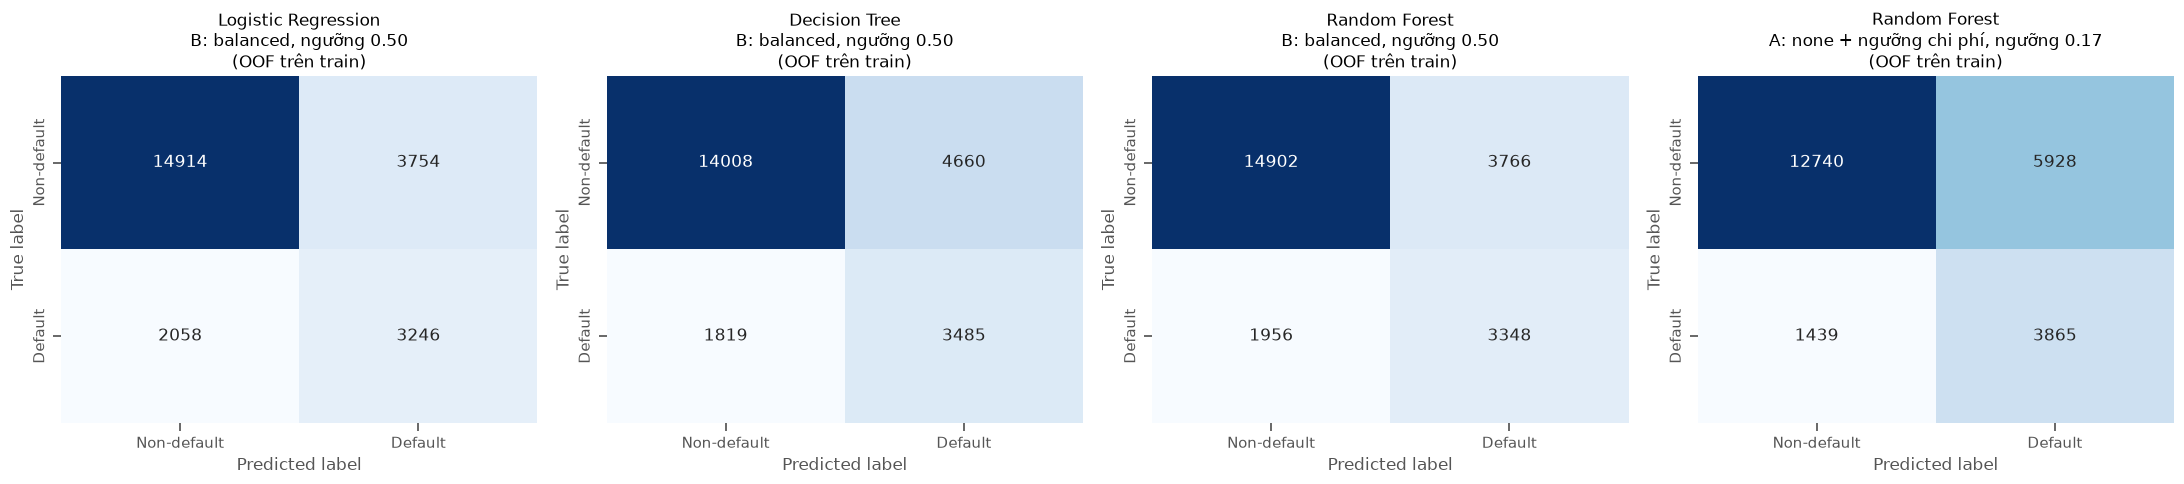

In [73]:
def plot_cm(ax, y_true, y_pred, title):
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['Non-default', 'Default'], yticklabels=['Non-default', 'Default'])
    ax.set(title=title, xlabel='Predicted label', ylabel='True label')


def cm_title(key, where):
    name, cfg, thr, _, _ = MODELS_48[key]
    return f"{name}\n{cfg}, ngưỡng {thr:.2f}\n({where})"


# Hình gộp: 4 ma trận nhầm lẫn OOF trên train
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, (key, (_, _, thr, oof, _)) in zip(axes, MODELS_48.items()):
    plot_cm(ax, y_train, (oof >= thr).astype(int), cm_title(key, 'OOF trên train'))
plt.tight_layout()
save_fig('ch4c_confusion_oof_train', fig)
plt.show()

# Hình riêng từng mô hình (để chèn vào từng mục của báo cáo), không hiển thị lại
for key, (_, _, thr, oof, _) in MODELS_48.items():
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    plot_cm(ax, y_train, (oof >= thr).astype(int), cm_title(key, 'OOF trên train'))
    plt.tight_layout()
    save_fig(f'ch4c_confusion_oof_train_{key}', fig)
    plt.close(fig)

In [74]:
# Tập test: dùng các mô hình đã fit sẵn (mục 4.5 và 4.5b), không fit lại
test_rows = {}
for key, (name, cfg, thr, _, model) in MODELS_48.items():
    test_rows[key] = eval_labels(y_test, model.predict(X_test4), model.predict_proba(X_test4)[:, 1])
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    plot_cm(ax, y_test, model.predict(X_test4), cm_title(key, 'tập test'))
    plt.tight_layout()
    save_fig(f'ch4c_confusion_test_{key}', fig)
    plt.close(fig)
test_table_48 = pd.DataFrame(test_rows).T
test_table_48.index = oof_table.index
save_table(test_table_48, 'test_metrics', prefix='ch4c')

,Accuracy,Precision,Recall,F1,F2,ROC-AUC,PR-AUC,TN,FP,FN,TP
"Logistic Regression (B: balanced, ngưỡng 0.50)",0.7567,0.4611,0.5905,0.5179,0.5591,0.7624,0.5275,3752.0000,915.0000,543.0000,783.0000
"Decision Tree (B: balanced, ngưỡng 0.50)",0.7265,0.4199,0.6192,0.5005,0.5655,0.7535,0.5272,3533.0000,1134.0000,505.0000,821.0000
"Random Forest (B: balanced, ngưỡng 0.50)",0.7606,0.4687,0.6161,0.5324,0.5797,0.7736,0.5559,3741.0000,926.0000,509.0000,817.0000
"Random Forest (A: none + ngưỡng chi phí, ngưỡng 0.17)",0.6790,0.3793,0.7089,0.4942,0.6040,0.7733,0.5586,3129.0000,1538.0000,386.0000,940.0000


In [75]:
# Bảng tổng hợp train (OOF) và test cạnh nhau
METRICS_48 = ['Accuracy', 'Precision', 'Recall', 'F1']
train_vs_test = pd.concat({'Train (OOF)': oof_table[METRICS_48], 'Test': test_table_48[METRICS_48],
                           'Chênh lệch (test − train)': test_table_48[METRICS_48] - oof_table[METRICS_48]}, axis=1)
train_vs_test[('Số mẫu', 'Train')] = len(y_train)
train_vs_test[('Số mẫu', 'Test')] = len(y_test)
save_table(train_vs_test, 'train_vs_test', prefix='ch4c')
train_vs_test.style.format('{:.4f}', subset=[c for c in train_vs_test.columns if c[0] != 'Số mẫu'])

In [76]:
# Số khách hàng vỡ nợ phát hiện thêm / cảnh báo nhầm thêm của RF A (ngưỡng chi phí) so với RF B (ngưỡng 0,5)
for label, tbl in [('Train (OOF)', oof_rows), ('Test', test_rows)]:
    a, b = tbl['rf_A'], tbl['rf_B']
    print(f"{label}: RF A phát hiện thêm {a['TP'] - b['TP']} khách hàng vỡ nợ (TP {b['TP']} → {a['TP']}), "
          f"thêm {a['FP'] - b['FP']} cảnh báo nhầm (FP {b['FP']} → {a['FP']}); "
          f"Accuracy {b['Accuracy']:.4f} → {a['Accuracy']:.4f}")

Train (OOF): RF A phát hiện thêm 517 khách hàng vỡ nợ (TP 3348 → 3865), thêm 2162 cảnh báo nhầm (FP 3766 → 5928); Accuracy 0.7613 → 0.6927
Test: RF A phát hiện thêm 123 khách hàng vỡ nợ (TP 817 → 940), thêm 612 cảnh báo nhầm (FP 926 → 1538); Accuracy 0.7606 → 0.6790


**Nhận xét 4.8:**

* **Kết quả huấn luyện (OOF trên 23.972 khách hàng train, 5.304 vỡ nợ):**
  * **Logistic Regression** (B, ngưỡng 0,5): Accuracy **0,7576**, Precision 0,4637, Recall 0,6120, F1 0,5276 (TN 14.914, FP 3.754, FN 2.058, TP 3.246).
  * **Decision Tree** (B, ngưỡng 0,5): Accuracy **0,7297**, Precision 0,4279, Recall 0,6571, F1 0,5183 (TN 14.008, FP 4.660, FN 1.819, TP 3.485).
  * **Random Forest** (B, ngưỡng 0,5): Accuracy **0,7613**, Precision 0,4706, Recall 0,6312, F1 0,5392 (TN 14.902, FP 3.766, FN 1.956, TP 3.348).
  * **Random Forest A + ngưỡng chi phí 0,17** (mô hình cuối): Accuracy **0,6927**, Precision 0,3947, Recall 0,7287, F1 0,5120 (TN 12.740, FP 5.928, FN 1.439, TP 3.865).
* **Train (OOF) và test chênh lệch nhỏ**, không có dấu hiệu overfit. Accuracy trên test thấp hơn OOF từ 0,0008 (LR) đến 0,0137 (RF A). F1 chênh 0,007–0,018. Recall chênh nhiều nhất ở DT (0,6571 → 0,6192, −0,038), các mô hình còn lại ≤ 0,022. Kết quả OOF là dự đoán trên dữ liệu mà mô hình chưa học, nên đây là ước lượng trung thực. Ngược lại, Accuracy khi dự đoán lại chính dữ liệu đã fit sẽ lạc quan hơn nhiều, nhất là với cây và rừng.
* **So sánh 3 thuật toán trong cùng điều kiện (cấu hình B, ngưỡng 0,5):** trên test, Random Forest có Accuracy cao nhất (0,7606) và F1 cao nhất (0,5324), tiếp theo là Logistic Regression (0,7567; 0,5179) và Decision Tree (0,7265; 0,5005). DT có Recall cao nhất (0,6192) nhưng nhiều cảnh báo nhầm nhất (FP 1.134). Kết quả khớp với so sánh CV và kiểm định ở mục 4.4. **RF A + ngưỡng 0,17 không tham gia so sánh thuật toán.** Đây là bước chọn ngưỡng vận hành (và bỏ trọng số lớp để xác suất đúng) sau khi RF đã được chọn là thuật toán tốt nhất.
* **Vì sao Accuracy của RF A (0,6790 trên test) thấp hơn RF B (0,7606) dù PR-AUC/ROC-AUC tương đương (0,5586/0,7733 so với 0,5559/0,7736):** hai mô hình xếp hạng khách hàng gần như giống nhau. Chỉ khác ngưỡng: 0,17 thấp hơn nhiều nên nhiều khách hàng hơn bị gắn nhãn vỡ nợ. Trên test, RF A **phát hiện thêm 123 khách hàng vỡ nợ** (TP 817 → 940, Recall 0,6161 → 0,7089), đổi lại **thêm 612 cảnh báo nhầm** (FP 926 → 1.538). Trên train OOF: thêm 517 TP và 2.162 FP. Accuracy coi mỗi lỗi như nhau nên giảm. Theo giả định chi phí 5:1, 123 × 5 = 615 đơn vị tiết kiệm từ FN gần như bù đúng 612 đơn vị chi phí FP tăng thêm.
* **Accuracy không phải độ đo phù hợp để chọn mô hình ở bài toán này.** Một mô hình luôn dự đoán "không vỡ nợ" đạt Accuracy 1 − 0,2213 = **0,7787** trên test, cao hơn mọi mô hình ở trên, nhưng không phát hiện được khách hàng vỡ nợ nào (Recall = 0). Vì vậy đồ án chọn mô hình theo PR-AUC, F2 và chi phí kỳ vọng. Accuracy chỉ được báo cáo cho đủ khung báo cáo.